# "Join the locals" vs. "Try harder"


## Load Data

### Summary stats per hexagon

In [3]:
.libPaths(c("/net/home/swolf/R/x86_64-pc-linux-gnu-library/4.4", .libPaths()))

In [4]:
library(data.table) 
dtn = 10
setDTthreads(threads = dtn) #defines how many threads data.table is allowed to use

In [1]:
combined_data <- read.csv("/net/scratch/swolf/GBIF/gbif_res3_try6_CS_wcvp_summary_stats_inkl_pca_mean_group_region_log10_notrim_misstree.csv")  
head(combined_data)

,h3_res3,group,PC1,PC2,PC3,PC4,PC5,count,count_sp,mean_perc_na,⋯,X.X237,X.X614,X.X351,X.X6,X.X95,X.X138,X.X1080,X.X78,X.X4,X.X47
,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,83001afffffffff,all,-10.334354,1.3228614,-1.7255834,1.0414618,2.1589100,10,4,5.68,⋯,-0.016,3.884,-0.020,-0.698,85.452,2.183,3.140,-0.547,0.3330000,0.152
2,83001afffffffff,native,-10.334354,1.3228614,-1.7255834,1.0414618,2.1589100,10,4,5.68,⋯,-0.016,3.884,-0.020,-0.698,85.452,2.183,3.140,-0.547,0.3330000,0.152
3,83001cfffffffff,all,-10.005360,-0.2380058,0.2491376,2.9137390,0.9757523,1,1,16.22,⋯,-0.119,3.810,0.001,-0.744,92.099,2.545,3.121,-0.563,0.3166111,0.175
4,83001cfffffffff,native,-9.988809,-0.3014320,0.2822225,2.9136399,0.9666302,1,1,16.22,⋯,-0.119,3.810,0.001,-0.744,92.099,2.545,3.121,-0.563,0.3291221,0.175
5,83001efffffffff,all,-10.690103,-0.8713593,-0.9452468,-0.2685651,1.3119540,4,3,3.38,⋯,0.122,4.005,0.003,-0.699,88.269,2.311,3.671,-1.933,0.4090000,0.211
6,83001efffffffff,native,-10.690103,-0.8713593,-0.9452468,-0.2685651,1.3119540,4,3,3.38,⋯,0.122,4.005,0.003,-0.699,88.269,2.311,3.671,-1.933,0.4090000,0.211


In [13]:
library(dplyr)

# combined_data - new row with percent_naturalized based on column count fro group=all and group=native
combined_data <- combined_data %>%
    group_by(h3_res3) %>%
    mutate(
        perc_naturalized = ifelse(
            any(group == "all") & any(group == "native"),
            (count[group == "all"] - count[group == "native"]) / count[group == "all"] * 100,
            NA
        )
        )
head(combined_data)


h3_res3,group,PC1,PC2,PC3,PC4,PC5,count,count_sp,X.X3117,⋯,X.X614,X.X351,X.X6,X.X95,X.X138,X.X1080,X.X78,X.X4,region,perc_naturalized
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>
83001afffffffff,all,-10.340785,1.3463123,-1.7276493,-1.0482630,-2.1657556,10,4,21.336,⋯,3.884,-0.020,-0.698,85.452,2.183,3.140,-0.547,0.3330000,11_PA,0
83001afffffffff,native,-10.340785,1.3463123,-1.7276493,-1.0482630,-2.1657556,10,4,21.336,⋯,3.884,-0.020,-0.698,85.452,2.183,3.140,-0.547,0.3330000,11_PA,0
83001cfffffffff,all,-9.994814,-0.2430451,0.2367820,-2.9060144,-1.0022472,1,1,15.259,⋯,3.810,0.001,-0.744,92.099,2.545,3.121,-0.563,0.3272027,,0
83001cfffffffff,native,-10.002619,-0.3291607,0.3134314,-2.9203937,-0.9736157,1,1,15.259,⋯,3.810,0.001,-0.744,92.099,2.545,3.121,-0.563,0.3360682,,0
83001efffffffff,all,-10.704678,-0.8306347,-0.9563224,0.2603966,-1.3077282,4,3,16.946,⋯,4.005,0.003,-0.699,88.269,2.311,3.671,-1.933,0.4090000,11_PA,0
83001efffffffff,native,-10.704678,-0.8306347,-0.9563224,0.2603966,-1.3077282,4,3,16.946,⋯,4.005,0.003,-0.699,88.269,2.311,3.671,-1.933,0.4090000,11_PA,0


In [14]:
#filter combined_data for rows where group == "all"
gdf <- combined_data %>%
    filter(group == "all") 
head(gdf)

h3_res3,group,PC1,PC2,PC3,PC4,PC5,count,count_sp,X.X3117,⋯,X.X614,X.X351,X.X6,X.X95,X.X138,X.X1080,X.X78,X.X4,region,perc_naturalized
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>
83001afffffffff,all,-10.340785,1.3463123,-1.7276493,-1.04826303,-2.1657556,10,4,21.336,⋯,3.884,-0.020,-0.698,85.452,2.183,3.140,-0.547,0.3330000,11_PA,0
83001cfffffffff,all,-9.994814,-0.2430451,0.2367820,-2.90601436,-1.0022472,1,1,15.259,⋯,3.810,0.001,-0.744,92.099,2.545,3.121,-0.563,0.3272027,,0
83001efffffffff,all,-10.704678,-0.8306347,-0.9563224,0.26039659,-1.3077282,4,3,16.946,⋯,4.005,0.003,-0.699,88.269,2.311,3.671,-1.933,0.4090000,11_PA,0
830025fffffffff,all,-9.932428,0.6468680,-1.3331355,0.13212320,-2.0923569,16,8,20.123,⋯,3.960,0.002,-0.745,89.280,2.133,3.548,-0.810,0.3620000,11_PA,0
830028fffffffff,all,-10.158281,-1.7372160,-1.0907707,-0.08598429,-0.7938732,58,13,14.742,⋯,3.855,0.008,-0.807,90.864,2.376,3.544,-1.873,0.4320000,11_PA,0
830029fffffffff,all,-9.776967,-0.7924605,-1.1169053,-1.02248828,-0.8994772,38,13,16.301,⋯,3.798,-0.009,-0.772,90.744,2.362,3.430,-1.351,0.4100000,11_PA,0


In [38]:
# calculate average perc_naturalized for each region
average_perc_naturalized_region <- gdf %>%
    group_by(region) %>%
    summarise(average_perc_naturalized = mean(perc_naturalized, na.rm = TRUE))

head(average_perc_naturalized_region)

region,average_perc_naturalized
<chr>,<dbl>
,25.544210
10_AA,26.657888
10_AT,26.190155
10_IM,26.457700
10_NT,13.375786
10_PA,7.416842


In [32]:
# read the aggregated shapefile
library(sf)
wwf_aggregated <- st_read("~/iNaturalist/Data/WWF/wwf_terr_ecos_aggregated.shp")
print(wwf_aggregated)

Reading layer `wwf_terr_ecos_aggregated' from data source 
  `/net/home/swolf/iNaturalist/Data/WWF/wwf_terr_ecos_aggregated.shp' 
  using driver `ESRI Shapefile'
Simple feature collection with 64 features and 1 field
Geometry type: MULTIPOLYGON
Dimension:     XY
Bounding box:  xmin: -180 ymin: -87.26008 xmax: 180 ymax: 83.62313
Geodetic CRS:  WGS 84
Simple feature collection with 64 features and 1 field
Geometry type: MULTIPOLYGON
Dimension:     XY
Bounding box:  xmin: -180 ymin: -87.26008 xmax: 180 ymax: 83.62313
Geodetic CRS:  WGS 84
First 10 features:
   bim_rlm                       geometry
1    10_AA MULTIPOLYGON (((171.4289 -4...
2    10_AT MULTIPOLYGON (((34.56465 1....
3    10_IM MULTIPOLYGON (((116.6342 6....
4    10_NT MULTIPOLYGON (((-76.14241 4...
5    10_PA MULTIPOLYGON (((64.75403 34...
6    11_AA MULTIPOLYGON (((179.1841 -4...
7    11_AN MULTIPOLYGON (((-66.89195 -...
8    11_NA MULTIPOLYGON (((-42.17305 6...
9    11_PA MULTIPOLYGON (((149.4331 68...
10   12_AA MULTIPOL

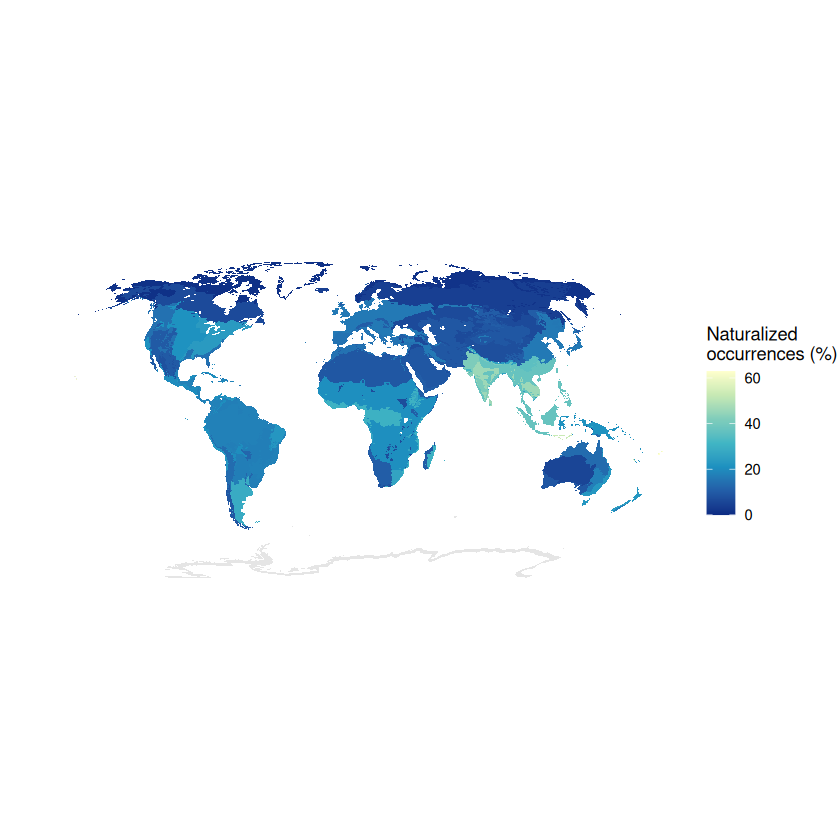

In [40]:
library(dplyr)
library(sf)
library(ggplot2)

# Average percentage naturalized per region
average_perc_naturalized_region <- gdf %>%
  group_by(region) %>%
  summarise(
    average_perc_naturalized = mean(perc_naturalized, na.rm = TRUE),
    .groups = "drop"
  )

# Join to WWF polygons
wwf_map <- wwf_aggregated %>%
  left_join(
    average_perc_naturalized_region,
    by = c("bim_rlm" = "region")
  )

# Plot
wwf_map_equalearth <- st_transform(
  wwf_map,
  "+proj=eqearth +datum=WGS84 +units=m +no_defs"
)

ggplot(wwf_map_robinson) +
  geom_sf(aes(fill = average_perc_naturalized), color = "white", linewidth = 0.01) +
  scale_fill_distiller(
    palette = "YlGnBu",
    name = "Naturalized\noccurrences (%)",
    na.value = "grey90"
  ) +
  theme_void()

  # Save as pdf
ggsave("~/Func_Neo_Phytes/Results/Figures/average_perc_naturalized_map.pdf", width = 10, height = 6, dpi = 300)

### Get biome stats

In [23]:
# read ~/Func_Neo_Phytes/Results/quantification_shifts_regions_Olsen_GBIF_wcvp_CS_log10_notrim_misstree.csv
biome_shifts_data <- read.csv("~/Func_Neo_Phytes/Results/quantification_shifts_regions_Olsen_GBIF_wcvp_CS_log10_notrim_misstree.csv")

In [24]:
# merge combined_results_region with average_perc_naturalized_region
biome_shifts_data <- biome_shifts_data %>%
    left_join(average_perc_naturalized_region, by = c("region"))    
head(biome_shifts_data)


,region,biome_number,biome_name,realm_abbrev,realm_name,cliffs_delta_PC1,cliffs_delta_PC2,cliffs_delta_PC3,cliffs_delta_PC4,cliffs_delta_PC5,⋯,effect_size_PC2,effect_size_PC3,effect_size_PC4,effect_size_PC5,significance_PC1,significance_PC2,significance_PC3,significance_PC4,significance_PC5,average_perc_naturalized
,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>
1,1_IM,1,Tropical & Subtropical Moist Broadleaf Forests,IM,Indomalaya,-0.21712727,0.120380165,-0.2467339,0.09298843,-0.02101488,⋯,small,small,negligible,negligible,***,**,***,,,37.26276
2,1_NT,1,Tropical & Subtropical Moist Broadleaf Forests,NT,Neotropical,-0.02023687,0.122340930,-0.1339892,0.01804425,0.04442939,⋯,small,small,negligible,negligible,,**,***,,,17.65715
3,2_AA,2,Tropical & Subtropical Dry Broadleaf Forests,AA,Australasia,0.30578512,0.008264463,-0.5537190,0.90082645,-0.09090909,⋯,negligible,large,large,negligible,,,,**,,52.77438
4,2_IM,2,Tropical & Subtropical Dry Broadleaf Forests,IM,Indomalaya,-0.29799688,0.265478668,-0.2946150,0.14997399,-0.12591051,⋯,small,medium,small,small,**,**,***,,,46.01088
5,2_NT,2,Tropical & Subtropical Dry Broadleaf Forests,NT,Neotropical,-0.04068047,0.155140533,-0.2106139,-0.03679734,0.02829142,⋯,small,small,negligible,negligible,,,*,,,20.27522
6,4_AA,4,Temperate Broadleaf & Mixed Forests,AA,Australasia,-0.11223330,0.379876278,-0.3076632,-0.04860497,0.06249211,⋯,medium,medium,negligible,negligible,,***,**,,,22.58698


## Per Biome relationship of effect size and percentage naturalized

In [26]:
library(tidyr)

plot_data <- biome_shifts_data %>%
  # remove effect_size_PC1	effect_size_PC2	effect_size_PC3	effect_size_PC4	effect_size_PC5
  select(-starts_with("effect_size_")) %>%
  pivot_longer(
    cols = matches("^(cliffs_delta|significance)_PC[1-5]$"),
    names_to = c(".value", "PC"),
    names_pattern = "(cliffs_delta|significance)_(PC[1-5])"
  )

In [27]:
head(plot_data)

region,biome_number,biome_name,realm_abbrev,realm_name,average_perc_naturalized,PC,cliffs_delta,significance
<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<chr>,<dbl>,<chr>
1_IM,1,Tropical & Subtropical Moist Broadleaf Forests,IM,Indomalaya,37.26276,PC1,-0.21712727,***
1_IM,1,Tropical & Subtropical Moist Broadleaf Forests,IM,Indomalaya,37.26276,PC2,0.12038017,**
1_IM,1,Tropical & Subtropical Moist Broadleaf Forests,IM,Indomalaya,37.26276,PC3,-0.24673388,***
1_IM,1,Tropical & Subtropical Moist Broadleaf Forests,IM,Indomalaya,37.26276,PC4,0.09298843,
1_IM,1,Tropical & Subtropical Moist Broadleaf Forests,IM,Indomalaya,37.26276,PC5,-0.02101488,
1_NT,1,Tropical & Subtropical Moist Broadleaf Forests,NT,Neotropical,17.65715,PC1,-0.02023687,


In [28]:
cor_results <- plot_data %>%
  group_by(PC) %>%
  summarise(
    rho = cor(
      average_perc_naturalized,
      cliffs_delta,
      method = "spearman",
      use = "complete.obs"
    ),
    p_value = cor.test(
      average_perc_naturalized,
      cliffs_delta,
      method = "spearman",
      exact = FALSE
    )$p.value,
    .groups = "drop"
  ) %>%
  mutate(
    p_adjusted = p.adjust(p_value, method = "BH")
  )

cor_results

PC,rho,p_value,p_adjusted
<chr>,<dbl>,<dbl>,<dbl>
PC1,-0.16491228,0.49988059,0.6248507
PC2,0.07017544,0.77528177,0.7752818
PC3,-0.49649123,0.03059620,0.1529810
PC4,0.41754386,0.07527979,0.1881995
PC5,-0.30701754,0.20105403,0.3350901


`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'Cliff's δ' in 'mbcsToSbcs': for δ (U+03B4)”


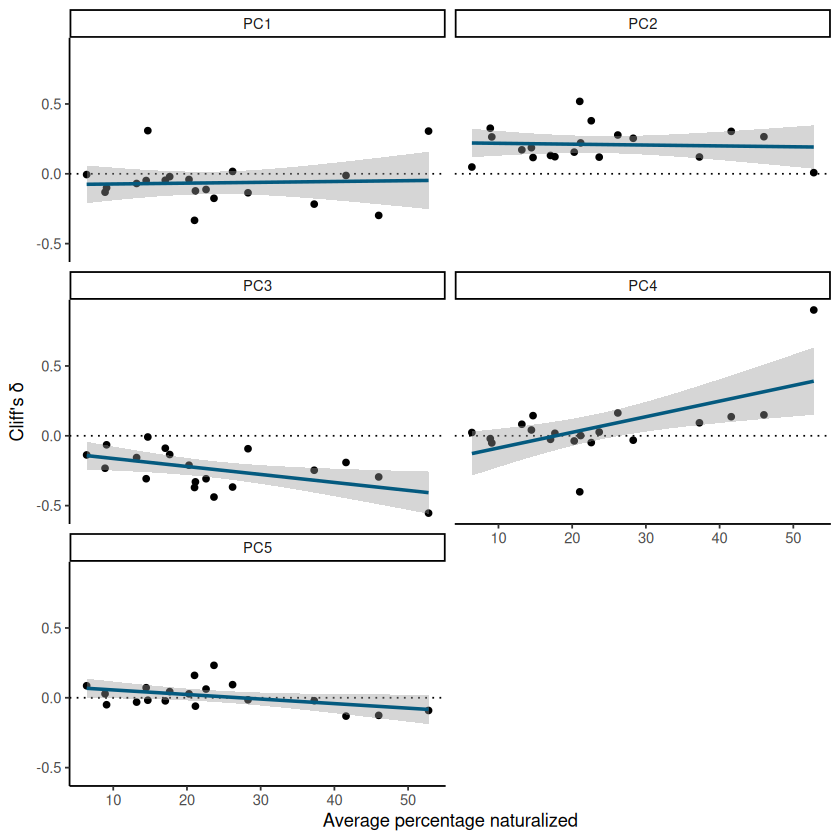

In [30]:
library(ggplot2)

ggplot(plot_data, aes(
  x = average_perc_naturalized,
  y = cliffs_delta
)) +
  geom_hline(yintercept = 0, linetype = "dotted", color = "black") +
  geom_point() +
  geom_smooth(method = "lm", se = TRUE, color = "#045A7FFF") +
  facet_wrap(~ PC, ncol = 2) +
  labs(
    x = "Average percentage naturalized",
    y = "Cliff's δ"
  ) +
  theme_classic()

ggsave(
  "~/Func_Neo_Phytes/Results/Figures/cliffs_delta_average_percent_nat.pdf",
  width = 12,
  height = 7
)


### Vector length in relation to percent introduced occurences

In [ ]:
# merge vector_lengths_df with average_perc_naturalized_region
merged_analysis <- vector_lengths_df %>%
  inner_join(average_perc_naturalized_region, by = "region")    

In [ ]:
# correlate vector lengths with average perc_naturalized per region
vector_lengths_df <- vector_lengths_df %>%
  left_join(average_perc_naturalized_region, by = "region")
head(vector_lengths_df)

cor_test <- cor.test(vector_lengths_df$vector_length, vector_lengths_df$average_perc_naturalized, method = "pearson")
print(cor_test)

# plot correlation
highlight_regions <- get_list_of_regions(combined_results_gbif)

# Ensure the columns are numeric
vector_lengths_df <- vector_lengths_df %>%
  mutate(
    vector_length = as.numeric(vector_length),
    average_perc_naturalized = as.numeric(average_perc_naturalized)
  )
  # Perform the correlation test
  cor_test <- cor.test(vector_lengths_df$average_perc_naturalized, vector_lengths_df$vector_length, method = "pearson")
  print(cor_test)

  # Plot correlation
  p_cor <- ggplot(vector_lengths_df, aes(x = vector_length, y = average_perc_naturalized)) +
    geom_point(aes(color = region %in% highlight_regions), size = 3) +
    geom_text(data = vector_lengths_df %>% filter(region %in% highlight_regions),
              aes(label = region), hjust = -0.2, vjust = -0.2, size = 3, color = "magenta") +
    geom_smooth(method = "lm", se = TRUE, color = "blue") +
    scale_color_manual(values = c("TRUE" = "magenta", "FALSE" = "black"), guide = "none") +
    theme_minimal() +
    theme(panel.grid = element_blank(), panel.border = element_rect(color = "black", fill = NA)) +
    labs(title = "Correlation between Average Percentage of Naturalized Species and Vector Lengths",
       x = "Vector Lengths",     
       y = "Average Percentage of Naturalized Species") +
    annotate("text", x = Inf, y = Inf, label = paste("r =", round(cor_test$estimate, 3), "\np =", signif(cor_test$p.value, 3)),
         hjust = 1.1, vjust = 1.1, size = 5)

    ggsave(filename = "../Results/Figures/correlation_vector_lengths_perc_naturalized_GBIF.png",
    plot = p_cor, width = 8, height = 8, dpi = 300)
    print(p_cor)


## Pixel - based shifts in relation to percent introduced species

In [42]:
# read data from a CSV file

summary_stats = fread("/net/scratch/swolf/GBIF/gbif_res3_try6_CS_wcvp_summary_stats_inkl_pca_mean_log10_notrim_misstree.csv")
head(summary_stats)

h3_res3,PC1_all,PC1_native,PC2_all,PC2_native,PC3_all,PC3_native,PC4_all,PC4_native,PC5_all,⋯,X.X78..median_native,X.X78..percent_change_mean,X.X78..percent_change_median,X.X4..mean_all,X.X4..mean_native,X.X4..median_all,X.X4..median_native,X.X4..percent_change_mean,X.X4..percent_change_median,resolution
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
832830fffffffff,-1.7232637,-1.27813427,0.9263347,0.1675457,0.1216236,0.5990069,0.29216332,0.4658460,0.08546972,⋯,-0.864,55.81,44.21,0.441,0.468,0.430,0.461,-5.77,-6.72,h3_res3
832834fffffffff,-1.6859293,-1.21423339,0.4578784,-0.2735865,0.1432890,0.6384654,0.48021442,0.6358498,0.19281510,⋯,-0.970,46.03,23.30,0.452,0.477,0.449,0.471,-5.24,-4.67,h3_res3
832831fffffffff,-1.8427677,-1.46762408,0.7897748,0.2858632,0.6707373,1.1363666,0.01756052,0.1472808,-0.01040755,⋯,-1.237,39.08,32.01,0.441,0.460,0.437,0.458,-4.13,-4.59,h3_res3
832655fffffffff,-0.2800225,0.03134629,2.3471014,2.2086049,0.5942497,1.0449347,0.41408056,0.3146419,0.29580870,⋯,-0.276,115.56,9.42,0.441,0.446,0.435,0.438,-1.12,-0.68,h3_res3
832a16fffffffff,-0.8489522,-0.32125390,2.6709352,2.3161817,0.8020473,1.8158122,0.48402609,0.6516194,0.01723522,⋯,-0.860,54.81,61.86,0.422,0.440,0.406,0.426,-4.09,-4.69,h3_res3
8329a5fffffffff,-1.7092541,-1.55298012,-0.2244413,-1.2233556,-1.0649597,-0.6430801,0.22944994,0.4727205,0.58945743,⋯,-0.039,321.79,979.49,0.459,0.484,0.465,0.478,-5.17,-2.72,h3_res3


### Calculate percentage introduced occurence and species per pixel

In [48]:
# for each row, calculate percent introduced occurences and percent introduced species 
# based on the columns count_all and count_native and count_sp_all and count_sp_native respectively
summary_stats <- summary_stats %>%
  mutate(
    perc_introduced_occurrences = ifelse(
      count_all > 0,
      (count_all - count_native) / count_all * 100,
      NA
    ),
    perc_introduced_species = ifelse(
      count_sp_all > 0,
      (count_sp_all - count_sp_native) / count_sp_all * 100,
      NA
    )
  )

In [49]:
head(summary_stats)

h3_res3,PC1_all,PC1_native,PC2_all,PC2_native,PC3_all,PC3_native,PC4_all,PC4_native,PC5_all,⋯,X.X78..percent_change_median,X.X4..mean_all,X.X4..mean_native,X.X4..median_all,X.X4..median_native,X.X4..percent_change_mean,X.X4..percent_change_median,resolution,perc_introduced_occurrences,perc_introduced_species
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>
832830fffffffff,-1.7232637,-1.27813427,0.9263347,0.1675457,0.1216236,0.5990069,0.29216332,0.4658460,0.08546972,⋯,44.21,0.441,0.468,0.430,0.461,-5.77,-6.72,h3_res3,29.16261,39.90315
832834fffffffff,-1.6859293,-1.21423339,0.4578784,-0.2735865,0.1432890,0.6384654,0.48021442,0.6358498,0.19281510,⋯,23.30,0.452,0.477,0.449,0.471,-5.24,-4.67,h3_res3,25.50949,41.09436
832831fffffffff,-1.8427677,-1.46762408,0.7897748,0.2858632,0.6707373,1.1363666,0.01756052,0.1472808,-0.01040755,⋯,32.01,0.441,0.460,0.437,0.458,-4.13,-4.59,h3_res3,19.83345,38.84494
832655fffffffff,-0.2800225,0.03134629,2.3471014,2.2086049,0.5942497,1.0449347,0.41408056,0.3146419,0.29580870,⋯,9.42,0.441,0.446,0.435,0.438,-1.12,-0.68,h3_res3,21.46665,24.53608
832a16fffffffff,-0.8489522,-0.32125390,2.6709352,2.3161817,0.8020473,1.8158122,0.48402609,0.6516194,0.01723522,⋯,61.86,0.422,0.440,0.406,0.426,-4.09,-4.69,h3_res3,37.67995,39.68816
8329a5fffffffff,-1.7092541,-1.55298012,-0.2244413,-1.2233556,-1.0649597,-0.6430801,0.22944994,0.4727205,0.58945743,⋯,979.49,0.459,0.484,0.465,0.478,-5.17,-2.72,h3_res3,35.20508,48.45361


`geom_smooth()` using formula = 'y ~ x'


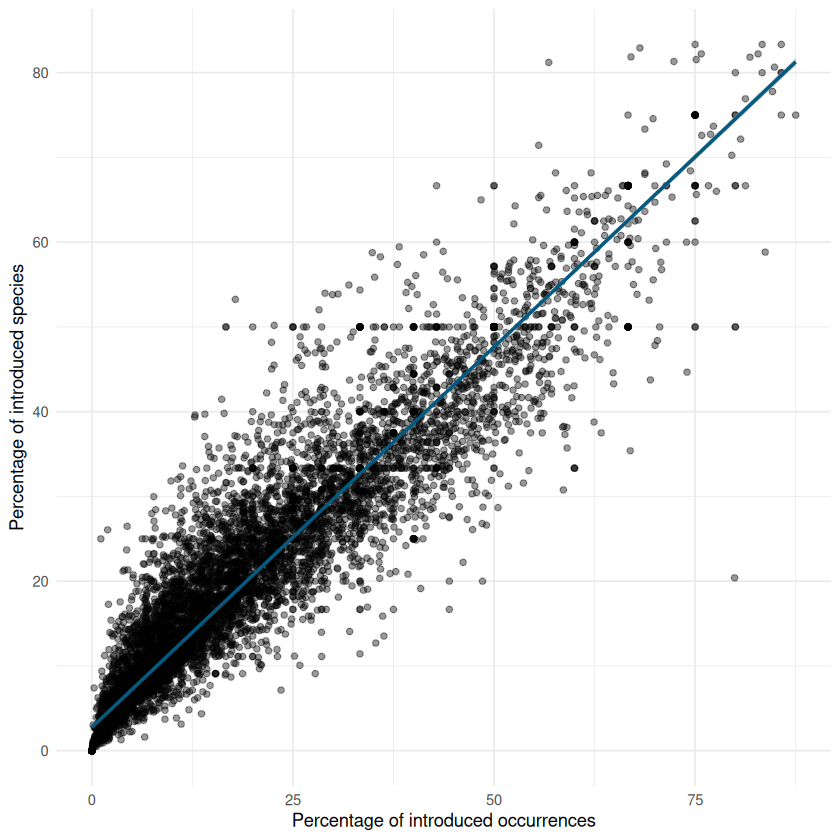

In [55]:
# plot perc_introduced_occurrences vs perc_introduced_species
ggplot(summary_stats, aes(
    x = perc_introduced_occurrences,
    y = perc_introduced_species
)) +
    geom_point(alpha = 0.4) +
    geom_smooth(method = "lm", se = TRUE, color = "#045A7FFF") +
    labs(
        x = "Percentage of introduced occurrences",
        y = "Percentage of introduced species"
    ) +
    theme_minimal()

### Calculate differnce in PCA space per pixel

In [56]:
# Calcualte difference  PC1_all-PC1_native, PC2_all-PC2_native, PC3_all-PC3_native, PC4_all-PC4_native, PC5_all-PC5_native
summary_stats$PC1_diff <- summary_stats$PC1_all - summary_stats$PC1_native
summary_stats$PC2_diff <- summary_stats$PC2_all - summary_stats$PC2_native
summary_stats$PC3_diff <- summary_stats$PC3_all - summary_stats$PC3_native
summary_stats$PC4_diff <- summary_stats$PC4_all - summary_stats$PC4_native
summary_stats$PC5_diff <- summary_stats$PC5_all - summary_stats$PC5_native

In [57]:
head(summary_stats)

h3_res3,PC1_all,PC1_native,PC2_all,PC2_native,PC3_all,PC3_native,PC4_all,PC4_native,PC5_all,⋯,X.X4..percent_change_mean,X.X4..percent_change_median,resolution,perc_introduced_occurrences,perc_introduced_species,PC1_diff,PC2_diff,PC3_diff,PC4_diff,PC5_diff
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
832830fffffffff,-1.7232637,-1.27813427,0.9263347,0.1675457,0.1216236,0.5990069,0.29216332,0.4658460,0.08546972,⋯,-5.77,-6.72,h3_res3,29.16261,39.90315,-0.4451294,0.7587890,-0.4773833,-0.17368270,0.02620156
832834fffffffff,-1.6859293,-1.21423339,0.4578784,-0.2735865,0.1432890,0.6384654,0.48021442,0.6358498,0.19281510,⋯,-5.24,-4.67,h3_res3,25.50949,41.09436,-0.4716959,0.7314649,-0.4951764,-0.15563541,0.04474717
832831fffffffff,-1.8427677,-1.46762408,0.7897748,0.2858632,0.6707373,1.1363666,0.01756052,0.1472808,-0.01040755,⋯,-4.13,-4.59,h3_res3,19.83345,38.84494,-0.3751436,0.5039116,-0.4656293,-0.12972026,0.02988633
832655fffffffff,-0.2800225,0.03134629,2.3471014,2.2086049,0.5942497,1.0449347,0.41408056,0.3146419,0.29580870,⋯,-1.12,-0.68,h3_res3,21.46665,24.53608,-0.3113687,0.1384965,-0.4506850,0.09943862,-0.03786375
832a16fffffffff,-0.8489522,-0.32125390,2.6709352,2.3161817,0.8020473,1.8158122,0.48402609,0.6516194,0.01723522,⋯,-4.09,-4.69,h3_res3,37.67995,39.68816,-0.5276983,0.3547535,-1.0137649,-0.16759335,0.37181438
8329a5fffffffff,-1.7092541,-1.55298012,-0.2244413,-1.2233556,-1.0649597,-0.6430801,0.22944994,0.4727205,0.58945743,⋯,-5.17,-2.72,h3_res3,35.20508,48.45361,-0.1562740,0.9989143,-0.4218796,-0.24327055,0.30597865


In [60]:
library(dplyr)
library(tidyr)

correlation_results <- lapply(1:5, function(i) {

  pc_diff_col <- paste0("PC", i, "_diff")

  # Introduced occurrences
  cor_occurrences <- cor.test(
    summary_stats[[pc_diff_col]],
    summary_stats$perc_introduced_occurrences,
    method = "spearman",
    exact = FALSE
  )

  # Introduced species
  cor_species <- cor.test(
    summary_stats[[pc_diff_col]],
    summary_stats$perc_introduced_species,
    method = "spearman",
    exact = FALSE
  )

  data.frame(
    PC = paste0("PC", i),
    predictor = c(
      "Introduced occurrences (%)",
      "Introduced species (%)"
    ),
    rho = c(
      unname(cor_occurrences$estimate),
      unname(cor_species$estimate)
    ),
    p_value = c(
      cor_occurrences$p.value,
      cor_species$p.value
    )
  )
}) %>%
  bind_rows() %>%
  mutate(
    p_adjusted = p.adjust(p_value, method = "BH"),
    across(c(rho, p_value, p_adjusted), ~ round(.x, 4))
  )

correlation_results

PC,predictor,rho,p_value,p_adjusted
<chr>,<chr>,<dbl>,<dbl>,<dbl>
PC1,Introduced occurrences (%),-0.1931,0.0000,0.0000
PC1,Introduced species (%),-0.2074,0.0000,0.0000
PC2,Introduced occurrences (%),0.4448,0.0000,0.0000
PC2,Introduced species (%),0.4601,0.0000,0.0000
PC3,Introduced occurrences (%),-0.4936,0.0000,0.0000
PC3,Introduced species (%),-0.4906,0.0000,0.0000
PC4,Introduced occurrences (%),0.1616,0.0000,0.0000
PC4,Introduced species (%),0.1428,0.0000,0.0000
PC5,Introduced occurrences (%),0.0124,0.2205,0.2205


`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


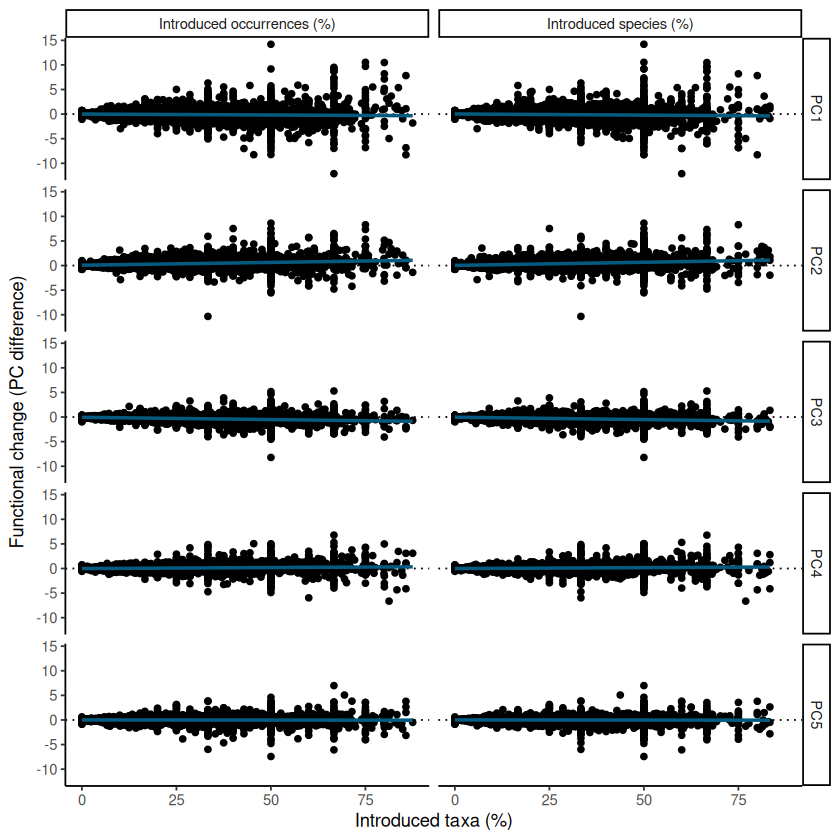

In [61]:
library(dplyr)
library(tidyr)
library(ggplot2)

plot_data <- summary_stats %>%
  select(
    PC1_diff:PC5_diff,
    perc_introduced_occurrences,
    perc_introduced_species
  ) %>%
  pivot_longer(
    cols = c(perc_introduced_occurrences, perc_introduced_species),
    names_to = "predictor",
    values_to = "introduced_percent"
  ) %>%
  pivot_longer(
    cols = ends_with("_diff"),
    names_to = "PC",
    values_to = "PC_diff"
  ) %>%
  mutate(
    PC = sub("_diff", "", PC),
    predictor = recode(
      predictor,
      perc_introduced_occurrences = "Introduced occurrences (%)",
      perc_introduced_species = "Introduced species (%)"
    )
  )

ggplot(
  plot_data,
  aes(
    x = introduced_percent,
    y = PC_diff
  )
) +
  geom_hline(
    yintercept = 0,
    linetype = "dotted",
    color = "black"
  ) +
  geom_point() +
  geom_smooth(
    method = "lm",
    se = TRUE,
    color = "#045A7FFF"
  ) +
  facet_grid(
    PC ~ predictor
  ) +
  labs(
    x = "Introduced taxa (%)",
    y = "Functional change (PC difference)"
  ) +
  theme_classic()

ggsave(
  "~/Func_Neo_Phytes/Results/Figures/PC_diff_introduced_percentage.pdf",
  width = 10,
  height = 12
)

In [62]:
combined_data <- read.csv("/net/scratch/swolf/GBIF/gbif_res3_try6_CS_wcvp_summary_stats_inkl_pca_mean_group_region_log10_notrim_misstree.csv")  
head(combined_data)

,h3_res3,group,PC1,PC2,PC3,PC4,PC5,count,count_sp,X.X3117,⋯,X.X237,X.X614,X.X351,X.X6,X.X95,X.X138,X.X1080,X.X78,X.X4,region
,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
1,83001afffffffff,all,-10.340785,1.3463123,-1.7276493,-1.0482630,-2.1657556,10,4,21.336,⋯,-0.016,3.884,-0.020,-0.698,85.452,2.183,3.140,-0.547,0.3330000,11_PA
2,83001afffffffff,native,-10.340785,1.3463123,-1.7276493,-1.0482630,-2.1657556,10,4,21.336,⋯,-0.016,3.884,-0.020,-0.698,85.452,2.183,3.140,-0.547,0.3330000,11_PA
3,83001cfffffffff,all,-9.994814,-0.2430451,0.2367820,-2.9060144,-1.0022472,1,1,15.259,⋯,-0.119,3.810,0.001,-0.744,92.099,2.545,3.121,-0.563,0.3272027,
4,83001cfffffffff,native,-10.002619,-0.3291607,0.3134314,-2.9203937,-0.9736157,1,1,15.259,⋯,-0.119,3.810,0.001,-0.744,92.099,2.545,3.121,-0.563,0.3360682,
5,83001efffffffff,all,-10.704678,-0.8306347,-0.9563224,0.2603966,-1.3077282,4,3,16.946,⋯,0.122,4.005,0.003,-0.699,88.269,2.311,3.671,-1.933,0.4090000,11_PA
6,83001efffffffff,native,-10.704678,-0.8306347,-0.9563224,0.2603966,-1.3077282,4,3,16.946,⋯,0.122,4.005,0.003,-0.699,88.269,2.311,3.671,-1.933,0.4090000,11_PA


In [66]:
# merge summary_stats with combined_data(subset h3_res3 and region) by h3_res3 
regions <- combined_data %>%
  select(h3_res3, region) %>%
  distinct()
summary_stats <- left_join(summary_stats, regions, by = "h3_res3")

`geom_smooth()` using formula = 'y ~ x'


`geom_smooth()` using formula = 'y ~ x'


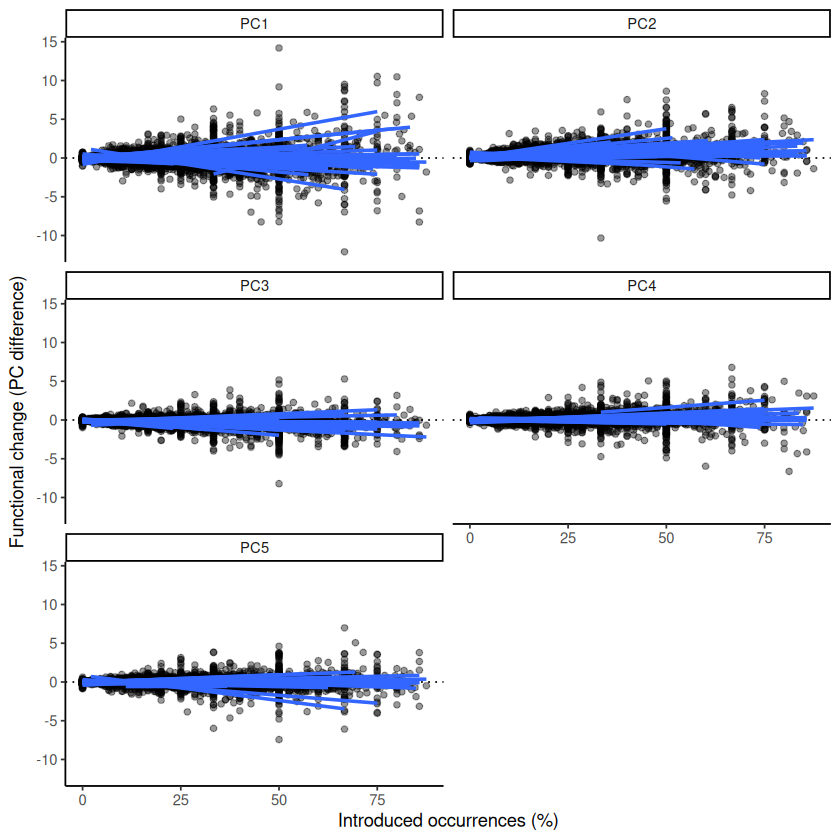

In [67]:
library(dplyr)
library(tidyr)
library(ggplot2)

plot_data <- summary_stats %>%
  select(
    region,
    perc_introduced_occurrences,
    PC1_diff:PC5_diff
  ) %>%
  pivot_longer(
    cols = PC1_diff:PC5_diff,
    names_to = "PC",
    values_to = "PC_diff"
  ) %>%
  mutate(
    PC = sub("_diff", "", PC)
  )

ggplot(
  plot_data,
  aes(
    x = perc_introduced_occurrences,
    y = PC_diff
  )
) +
  geom_hline(
    yintercept = 0,
    linetype = "dotted",
    color = "black"
  ) +
  geom_point(alpha = 0.4) +
  geom_smooth(
    aes(group = region),
    method = "lm",
    se = FALSE
  ) +
  facet_wrap(~ PC, ncol = 2) +
  labs(
    x = "Introduced occurrences (%)",
    y = "Functional change (PC difference)"
  ) +
  theme_classic()

ggsave(
  "~/Func_Neo_Phytes/Results/Figures/PC_diff_introduced_occurrences_by_region.pdf",
  width = 10,
  height = 10
)

In [69]:
library(dplyr)
library(tidyr)

correlation_results <- lapply(1:5, function(i) {

  pc_diff_col <- paste0("PC", i, "_diff")

  summary_stats %>%
    group_by(region) %>%
    summarise(
      n_occurrences = sum(
        is.finite(.data[[pc_diff_col]]) &
        is.finite(perc_introduced_occurrences)
      ),
      n_species = sum(
        is.finite(.data[[pc_diff_col]]) &
        is.finite(perc_introduced_species)
      ),

      rho_occurrences = if (n_occurrences >= 3) {
        cor(
          .data[[pc_diff_col]],
          perc_introduced_occurrences,
          method = "spearman",
          use = "complete.obs"
        )
      } else NA_real_,

      p_occurrences = if (n_occurrences >= 3) {
        cor.test(
          .data[[pc_diff_col]],
          perc_introduced_occurrences,
          method = "spearman",
          exact = FALSE
        )$p.value
      } else NA_real_,

      rho_species = if (n_species >= 3) {
        cor(
          .data[[pc_diff_col]],
          perc_introduced_species,
          method = "spearman",
          use = "complete.obs"
        )
      } else NA_real_,

      p_species = if (n_species >= 3) {
        cor.test(
          .data[[pc_diff_col]],
          perc_introduced_species,
          method = "spearman",
          exact = FALSE
        )$p.value
      } else NA_real_,

      .groups = "drop"
    ) %>%
    mutate(PC = paste0("PC", i)) %>%
    pivot_longer(
      cols = c(
        rho_occurrences, p_occurrences,
        rho_species, p_species
      ),
      names_to = c(".value", "predictor"),
      names_pattern = "(rho|p)_(occurrences|species)"
    ) %>%
    mutate(
      predictor = recode(
        predictor,
        occurrences = "Introduced occurrences (%)",
        species = "Introduced species (%)"
      )
    )
}) %>%
  bind_rows() %>%
  group_by(predictor) %>%
  mutate(
    p_adjusted = p.adjust(p, method = "BH")
  ) %>%
  ungroup() %>%
  mutate(
    across(c(rho, p, p_adjusted), ~ round(.x, 4))
  )

correlation_results

region,n_occurrences,n_species,PC,predictor,rho,p,p_adjusted
<chr>,<int>,<int>,<chr>,<chr>,<dbl>,<dbl>,<dbl>
,249,249,PC1,Introduced occurrences (%),0.0928,0.1441,0.2286
,249,249,PC1,Introduced species (%),0.0147,0.8171,0.8765
10_AA,16,16,PC1,Introduced occurrences (%),-0.5265,0.0362,0.0687
10_AA,16,16,PC1,Introduced species (%),-0.3382,0.2001,0.3050
10_AT,71,71,PC1,Introduced occurrences (%),-0.0314,0.7951,0.8561
10_AT,71,71,PC1,Introduced species (%),-0.1118,0.3533,0.4870
10_IM,3,3,PC1,Introduced occurrences (%),-1.0000,0.0000,0.0000
10_IM,3,3,PC1,Introduced species (%),-0.5000,0.6667,0.7623
10_NT,68,68,PC1,Introduced occurrences (%),-0.6690,0.0000,0.0000


Warning message in inner_join(., significant_combinations, by = "region"):
“Detected an unexpected many-to-many relationship between `x` and `y`.
ℹ Row 1 of `x` matches multiple rows in `y`.
ℹ Row 39 of `y` matches multiple rows in `x`.
ℹ If a many-to-many relationship is expected, set `relationship =
  "many-to-many"` to silence this warning.”
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


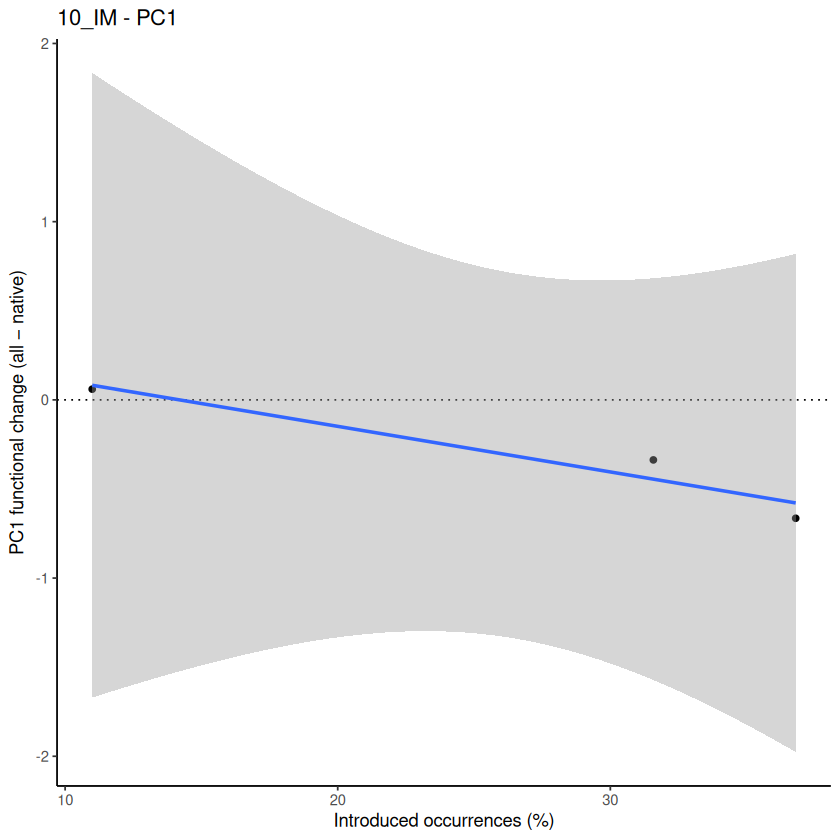

`geom_smooth()` using formula = 'y ~ x'


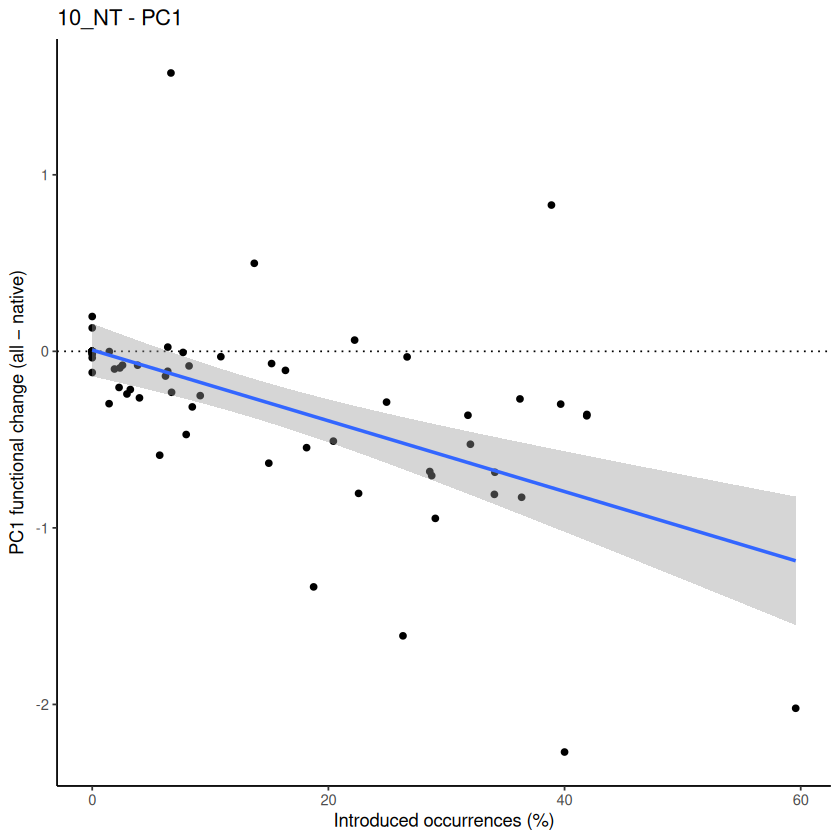

`geom_smooth()` using formula = 'y ~ x'


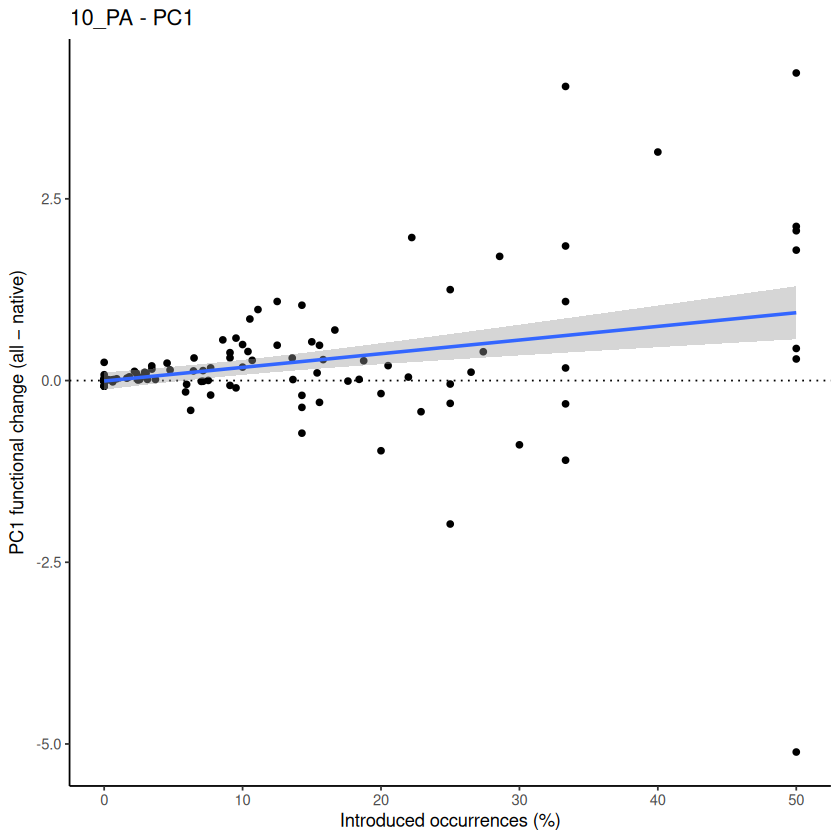

`geom_smooth()` using formula = 'y ~ x'


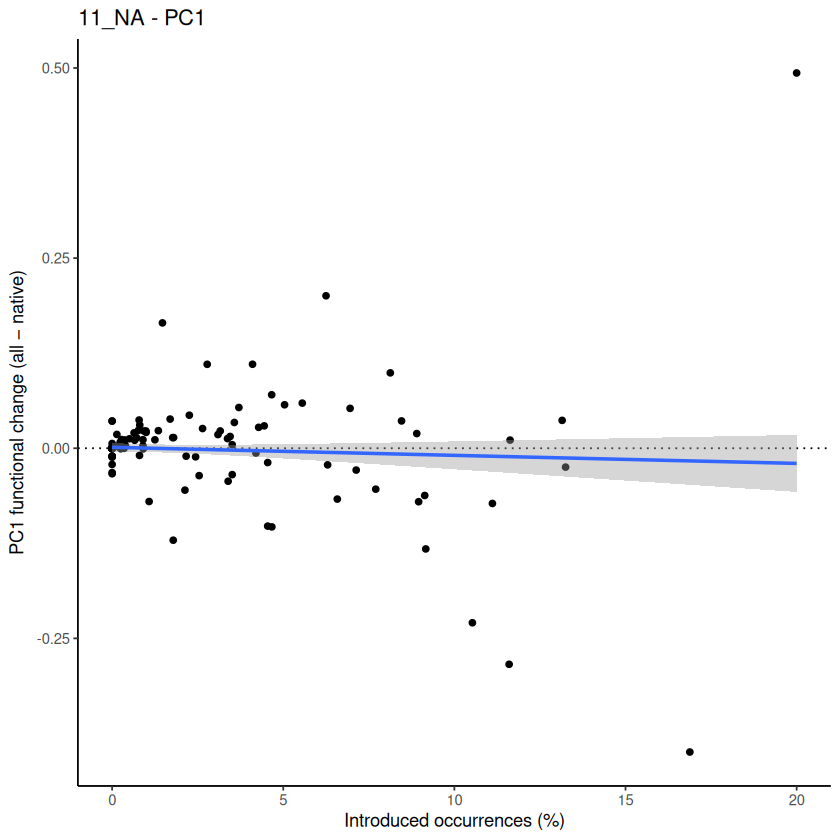

`geom_smooth()` using formula = 'y ~ x'


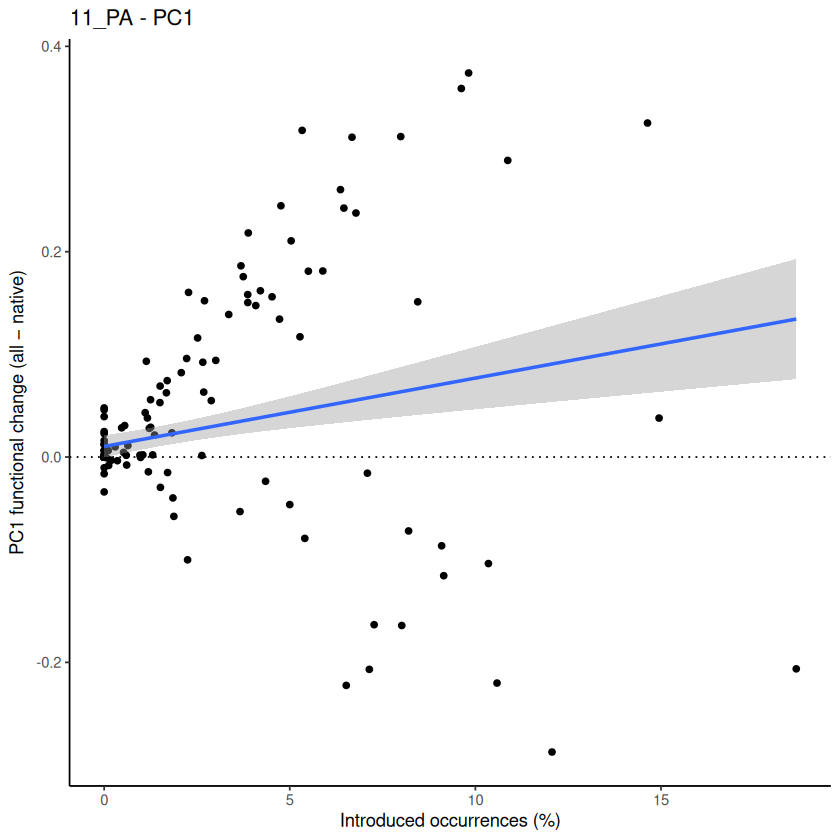

`geom_smooth()` using formula = 'y ~ x'


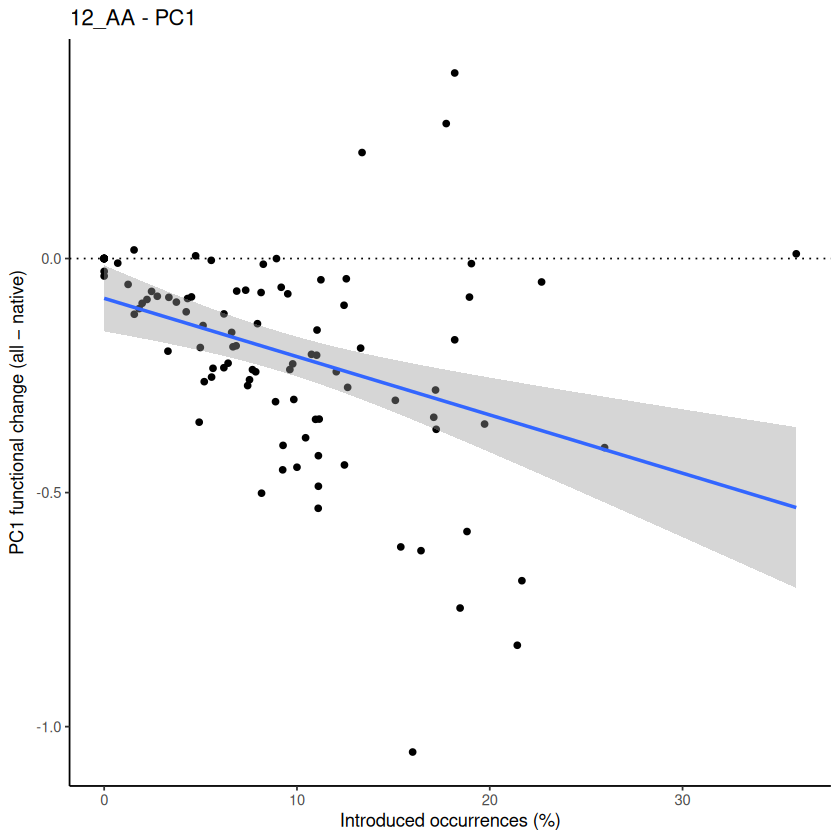

`geom_smooth()` using formula = 'y ~ x'


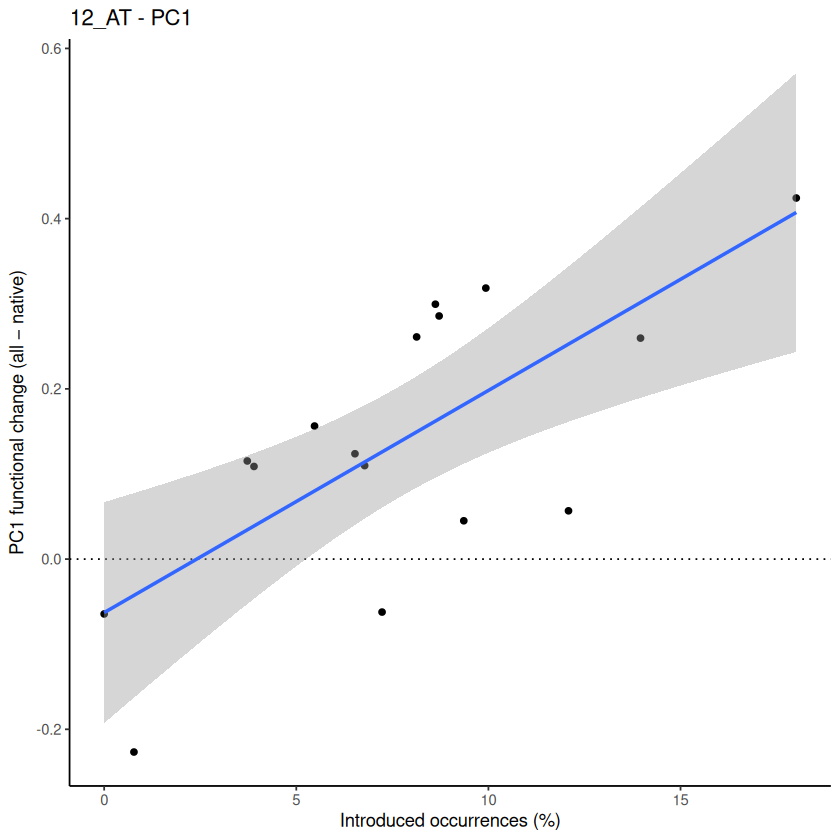

`geom_smooth()` using formula = 'y ~ x'


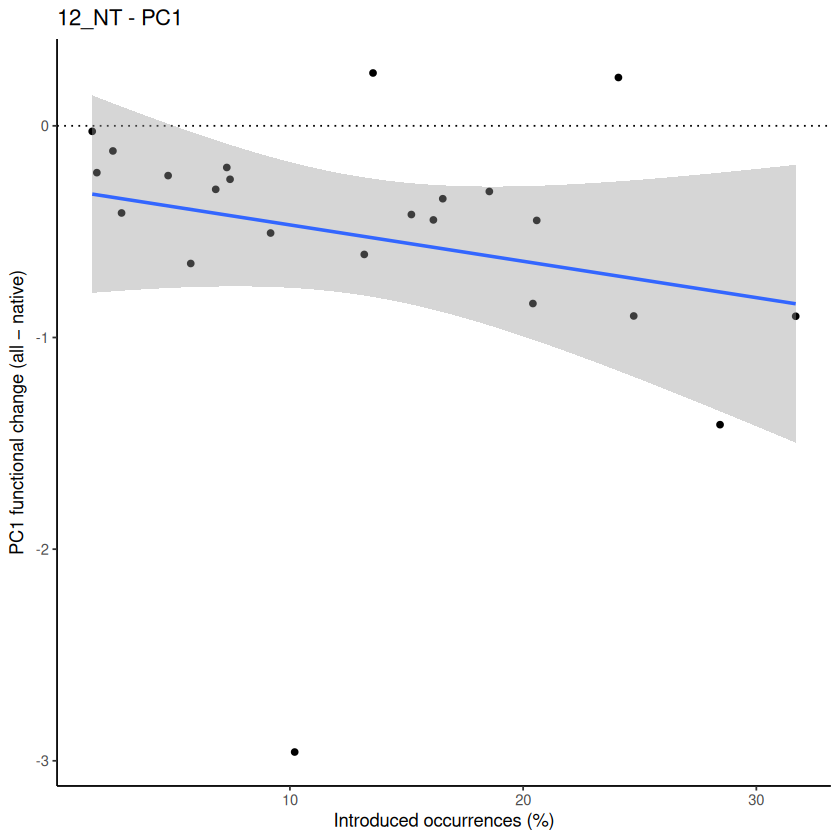

`geom_smooth()` using formula = 'y ~ x'


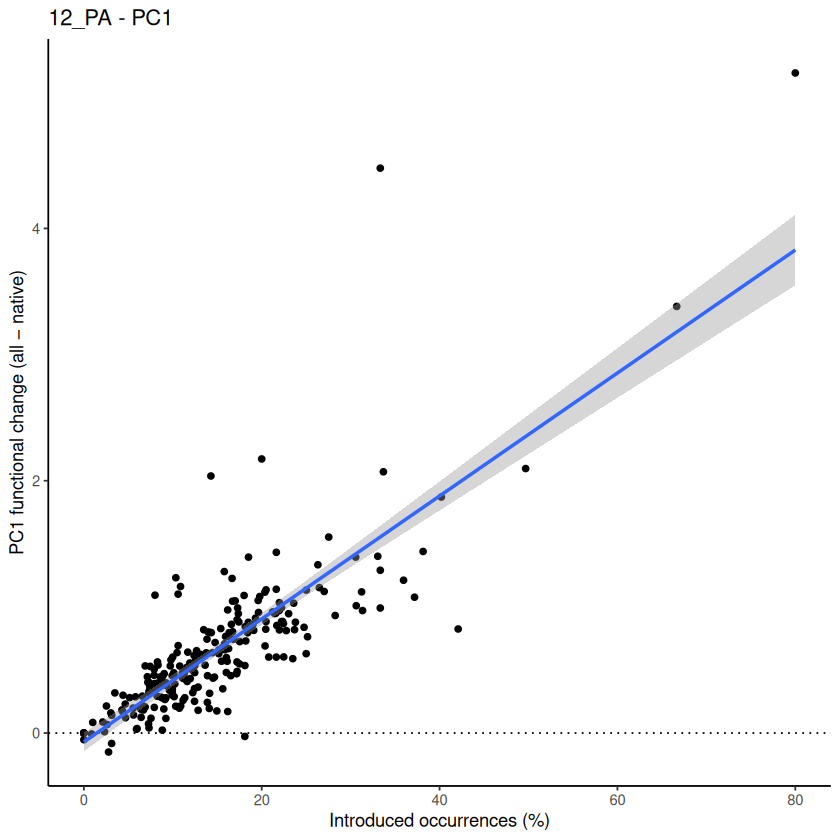

`geom_smooth()` using formula = 'y ~ x'


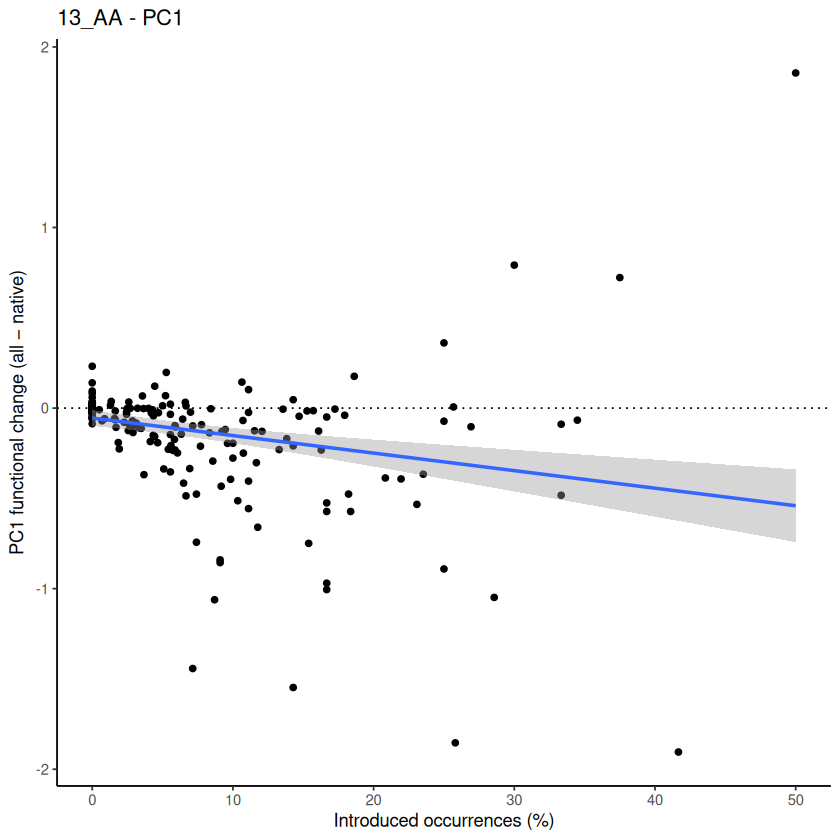

`geom_smooth()` using formula = 'y ~ x'


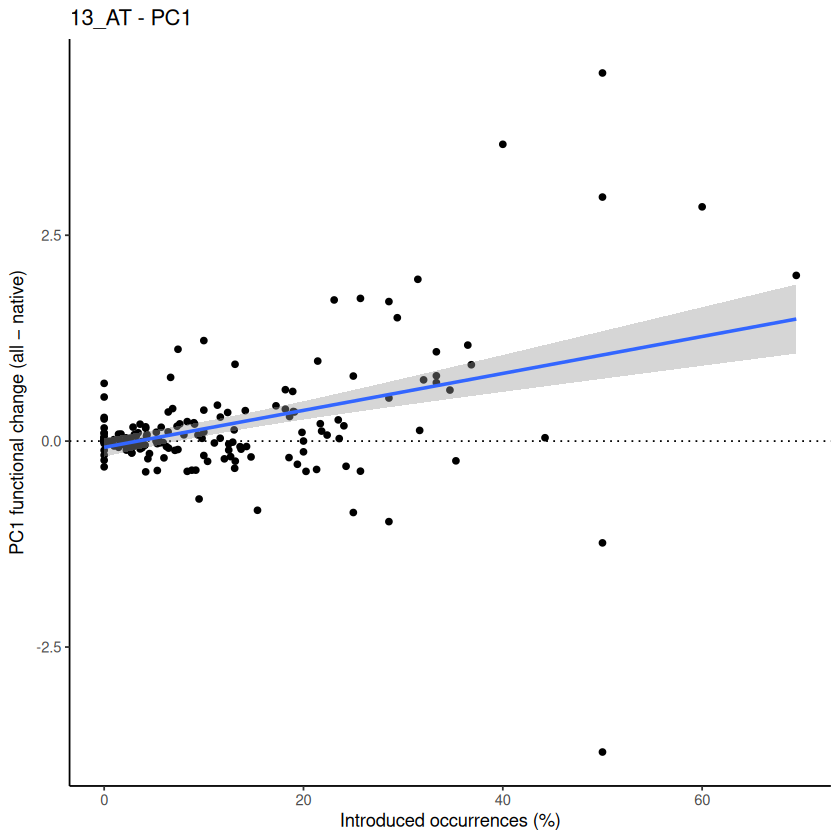

`geom_smooth()` using formula = 'y ~ x'


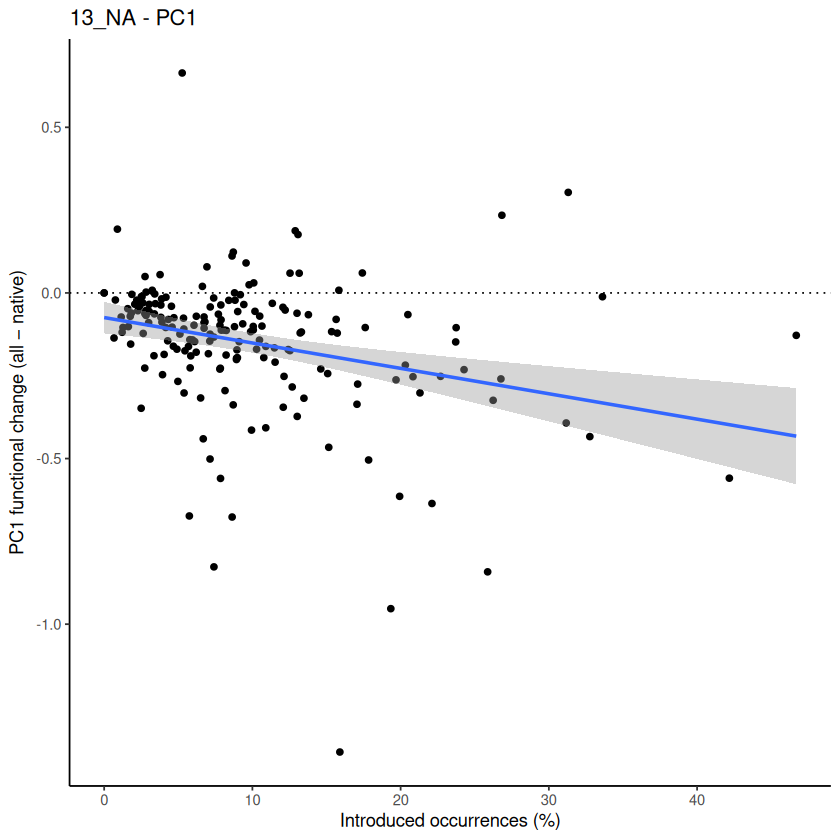

`geom_smooth()` using formula = 'y ~ x'


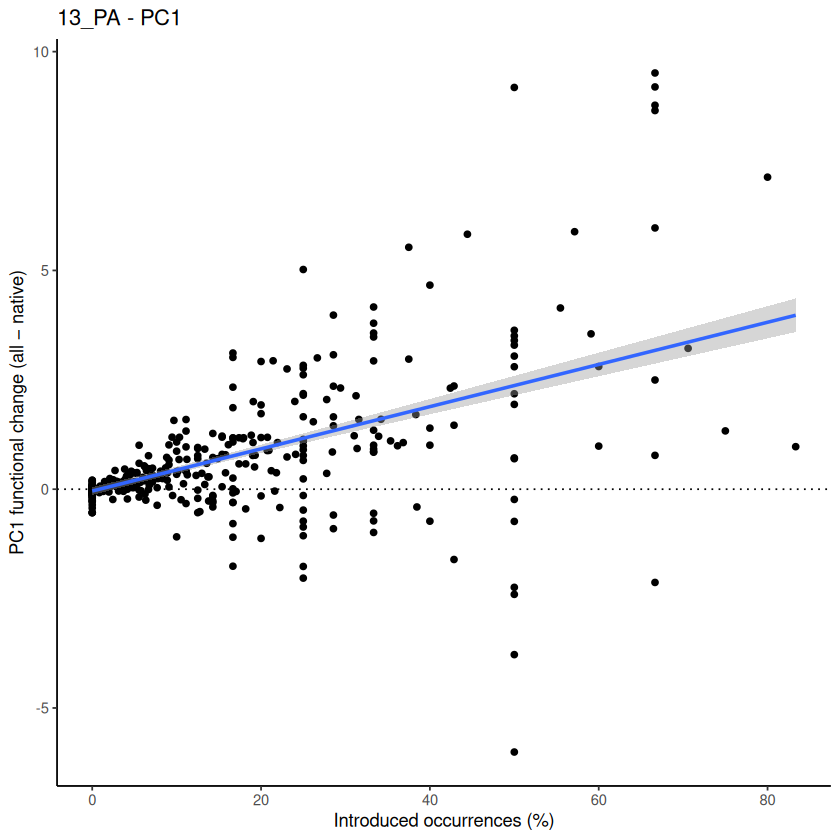

`geom_smooth()` using formula = 'y ~ x'


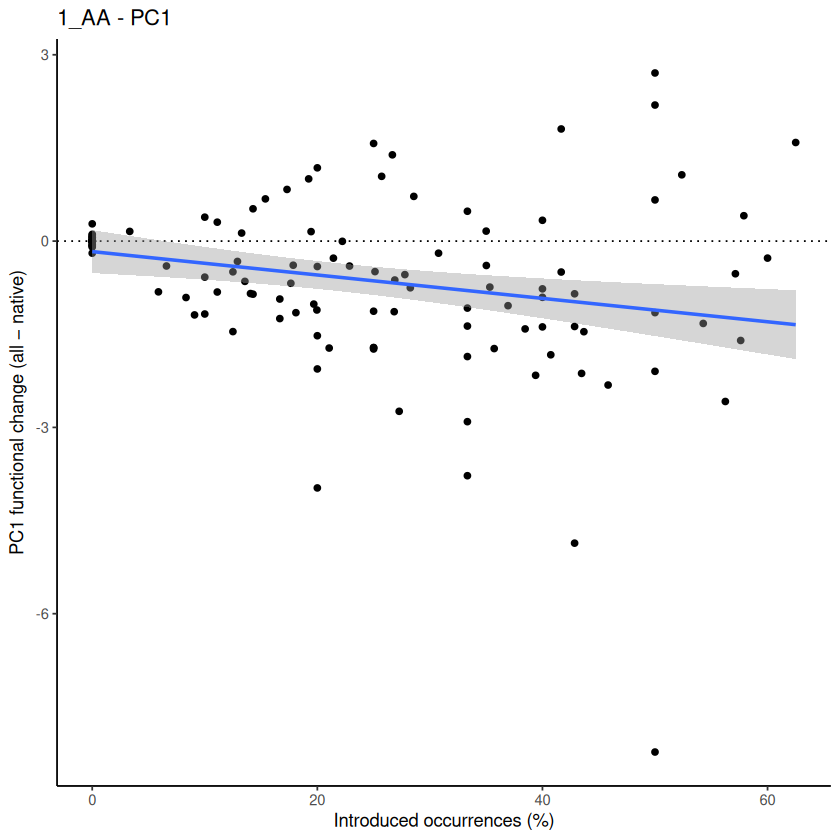

`geom_smooth()` using formula = 'y ~ x'


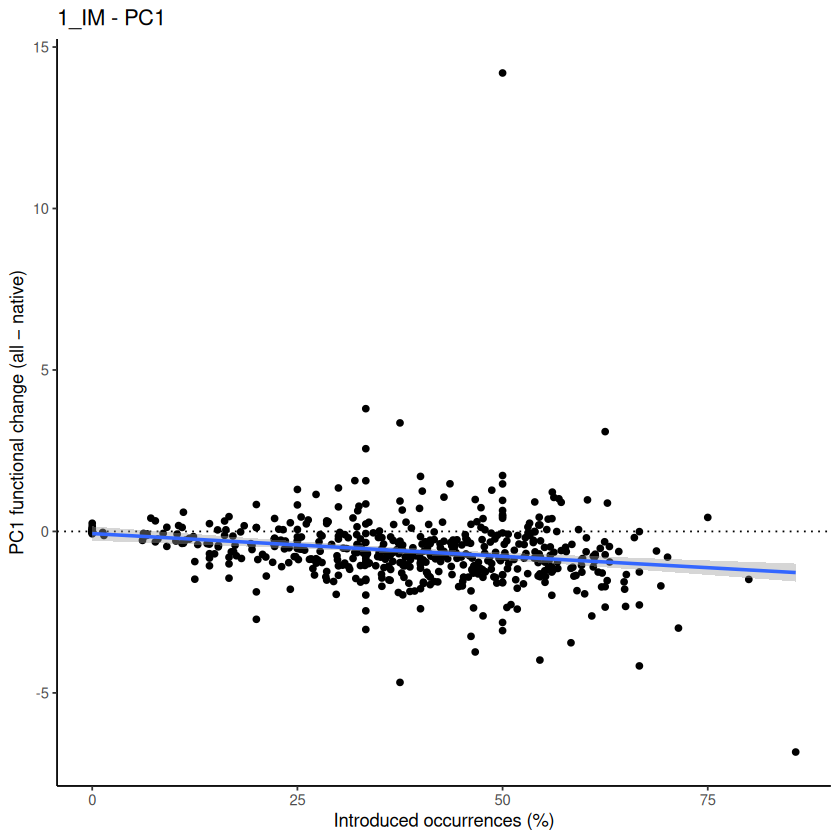

`geom_smooth()` using formula = 'y ~ x'


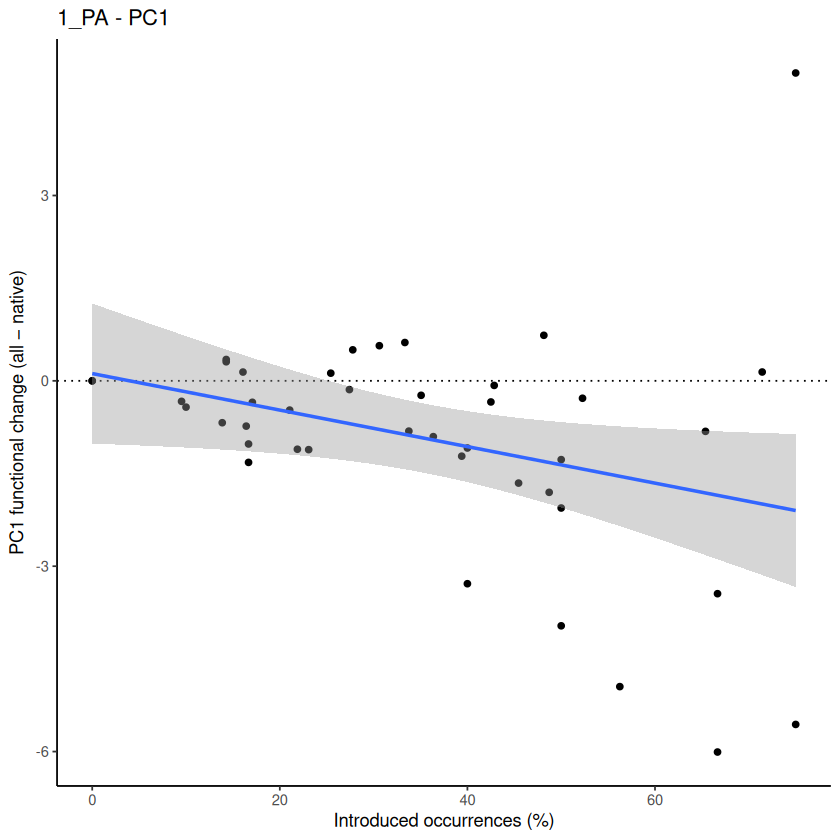

`geom_smooth()` using formula = 'y ~ x'


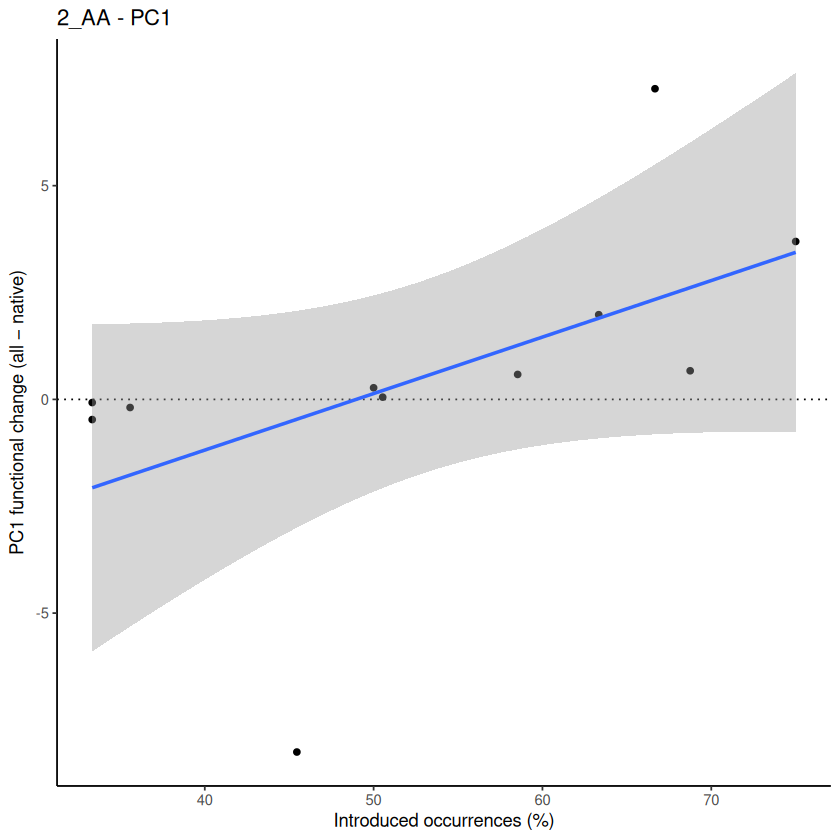

`geom_smooth()` using formula = 'y ~ x'


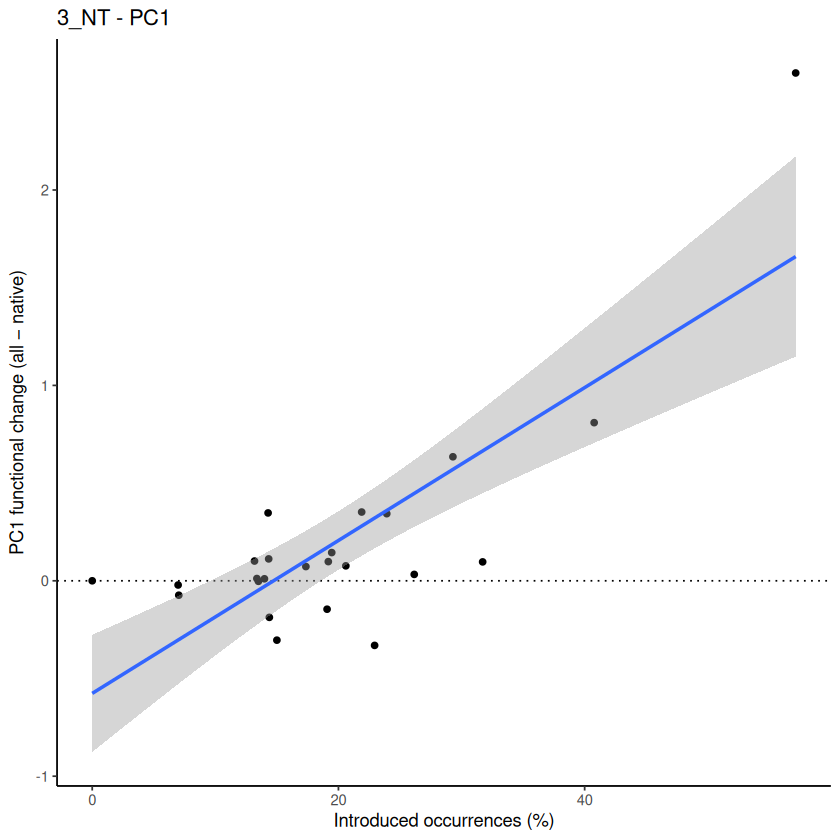

`geom_smooth()` using formula = 'y ~ x'


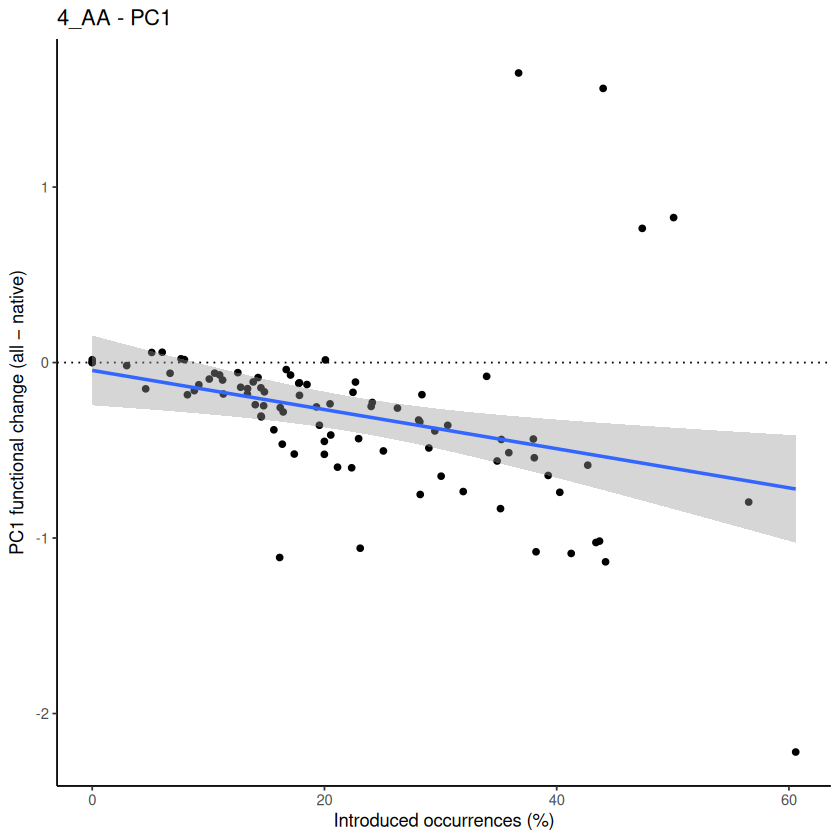

`geom_smooth()` using formula = 'y ~ x'


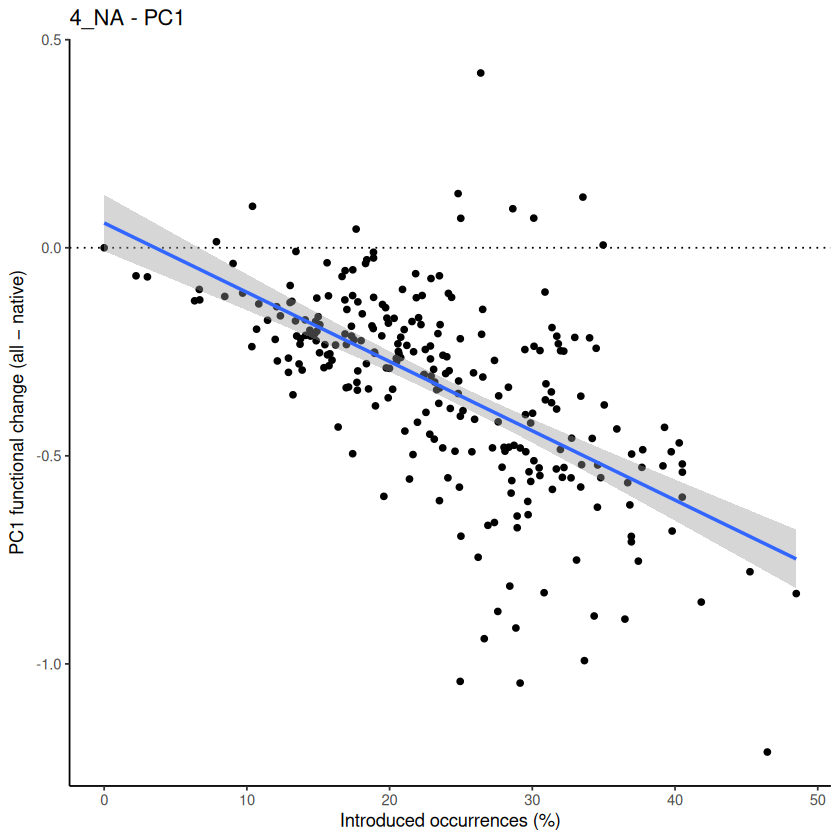

`geom_smooth()` using formula = 'y ~ x'


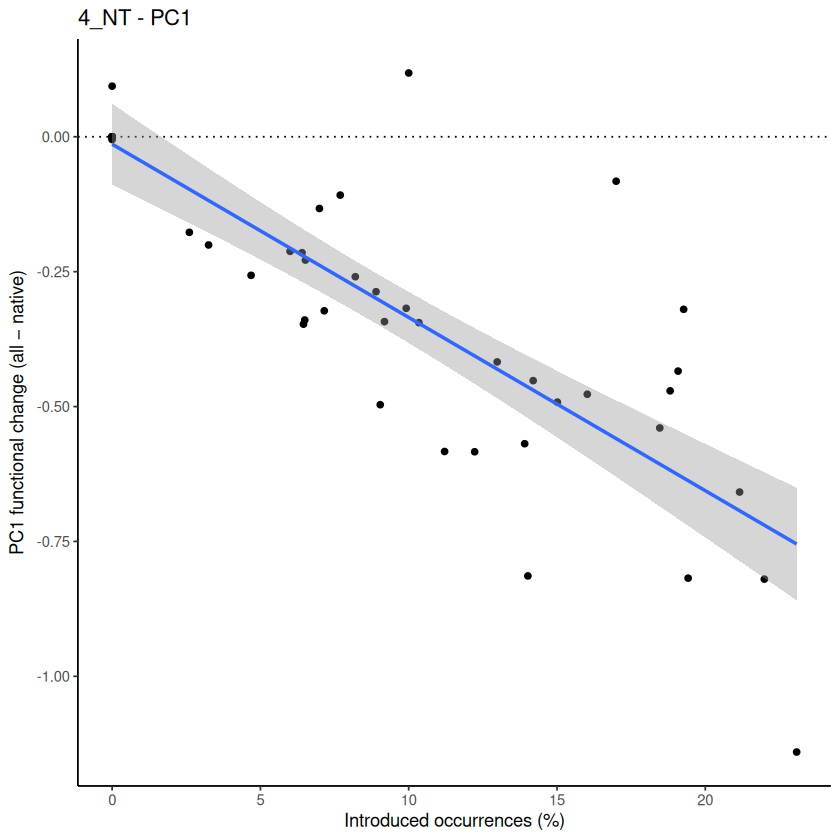

`geom_smooth()` using formula = 'y ~ x'


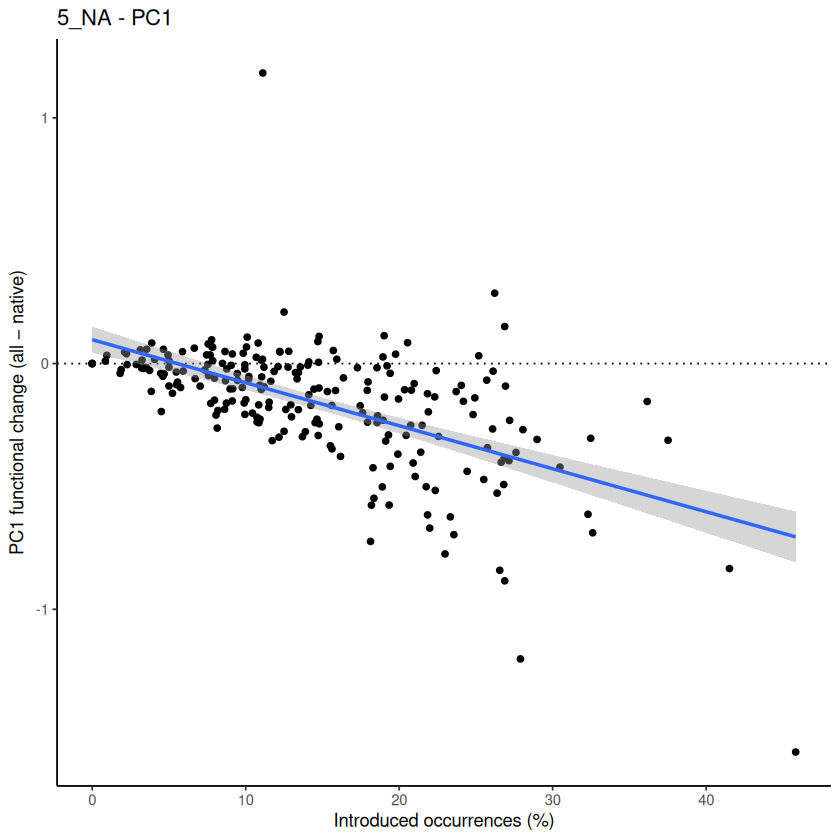

`geom_smooth()` using formula = 'y ~ x'


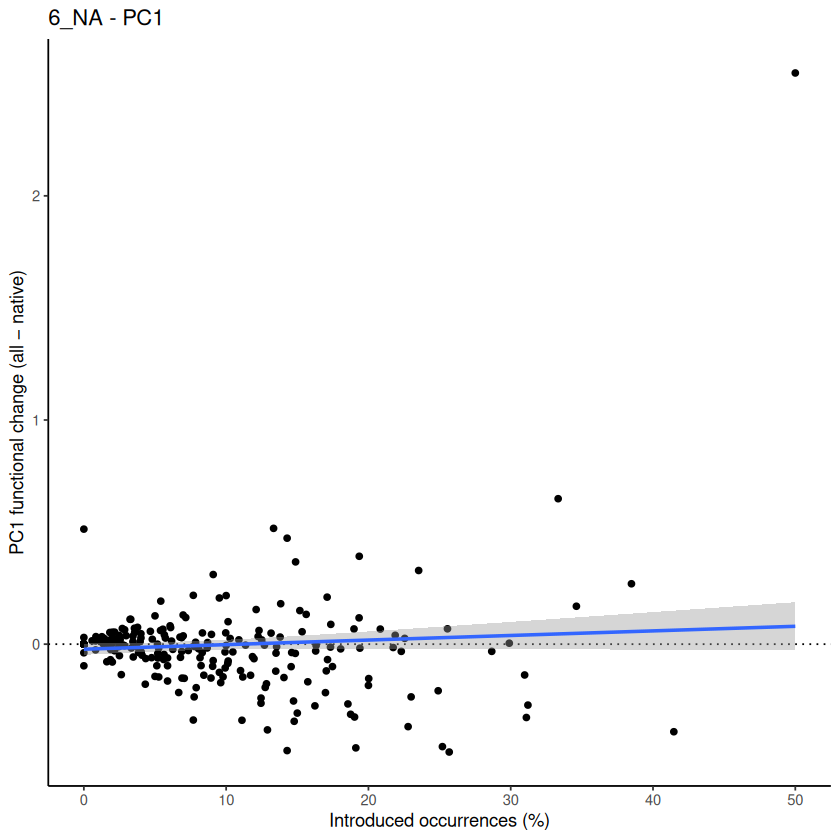

`geom_smooth()` using formula = 'y ~ x'


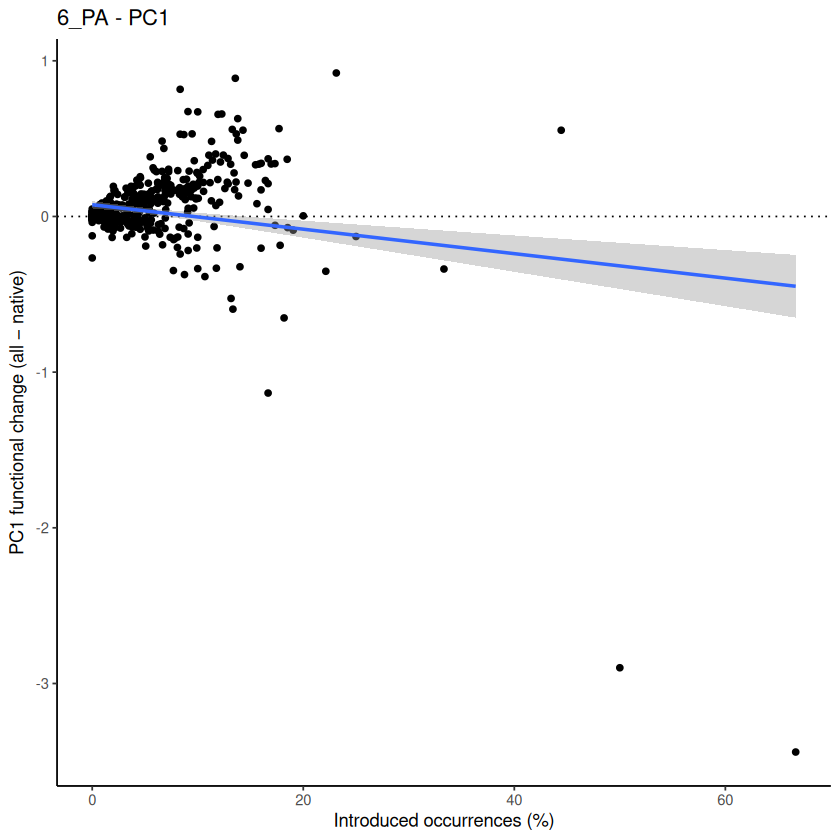

`geom_smooth()` using formula = 'y ~ x'


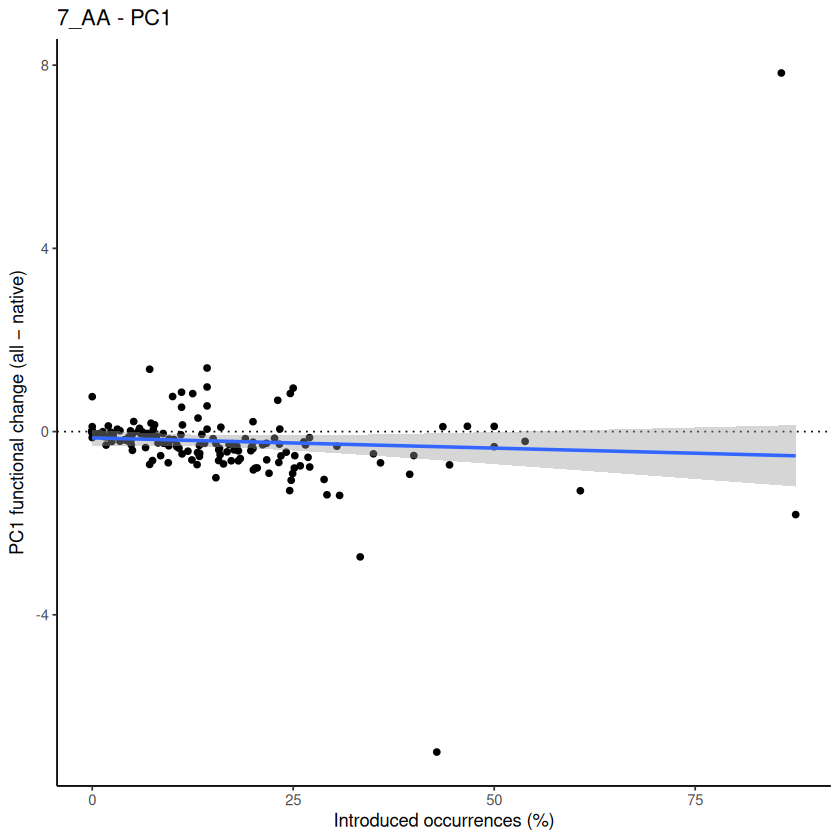

`geom_smooth()` using formula = 'y ~ x'


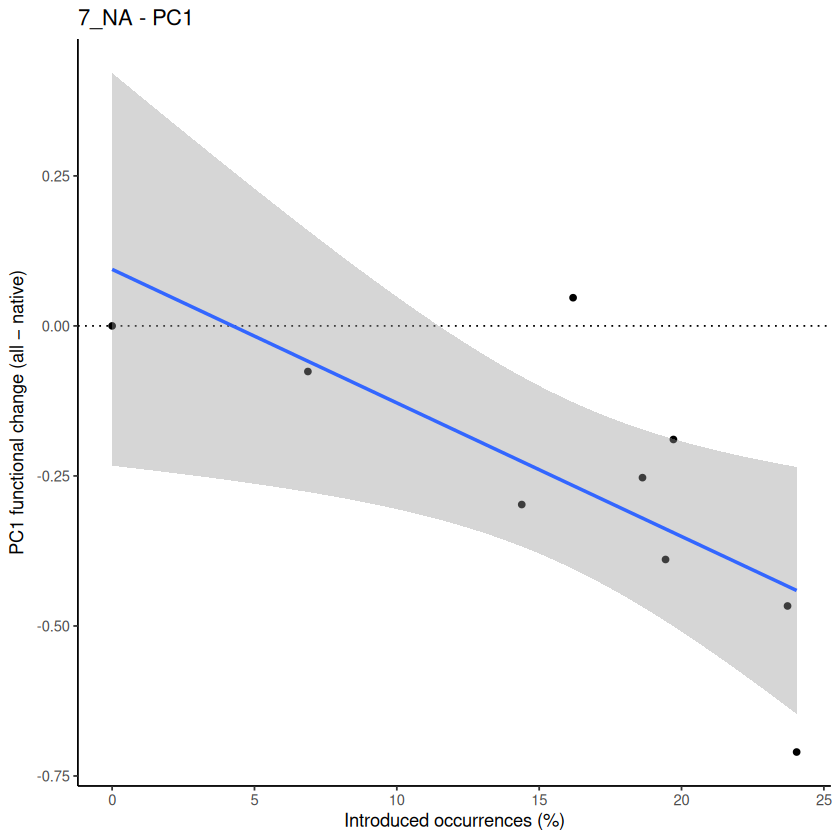

`geom_smooth()` using formula = 'y ~ x'


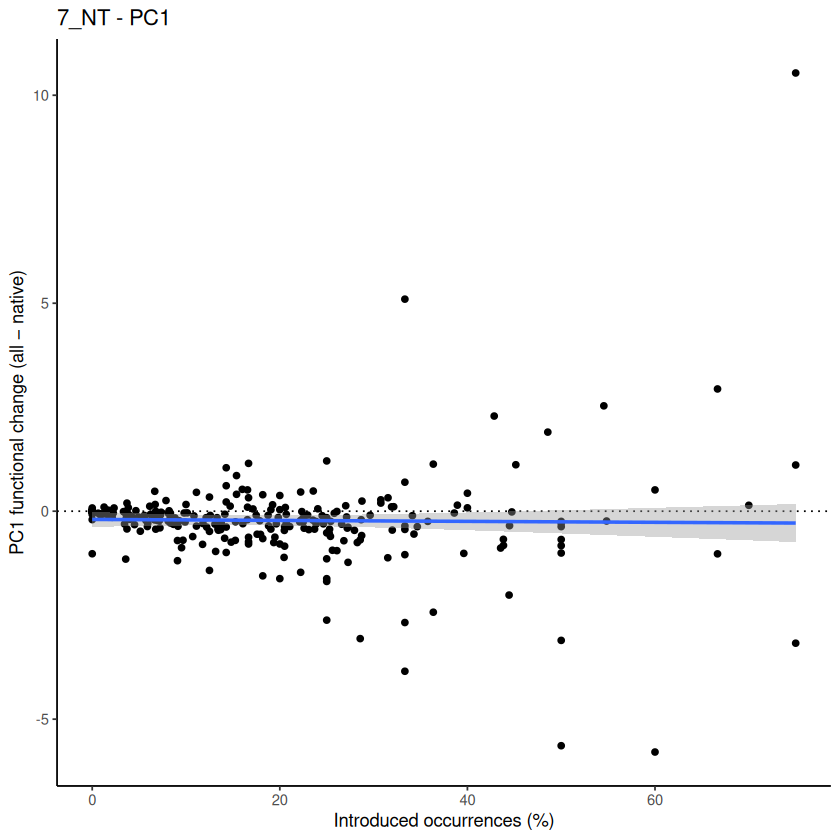

`geom_smooth()` using formula = 'y ~ x'


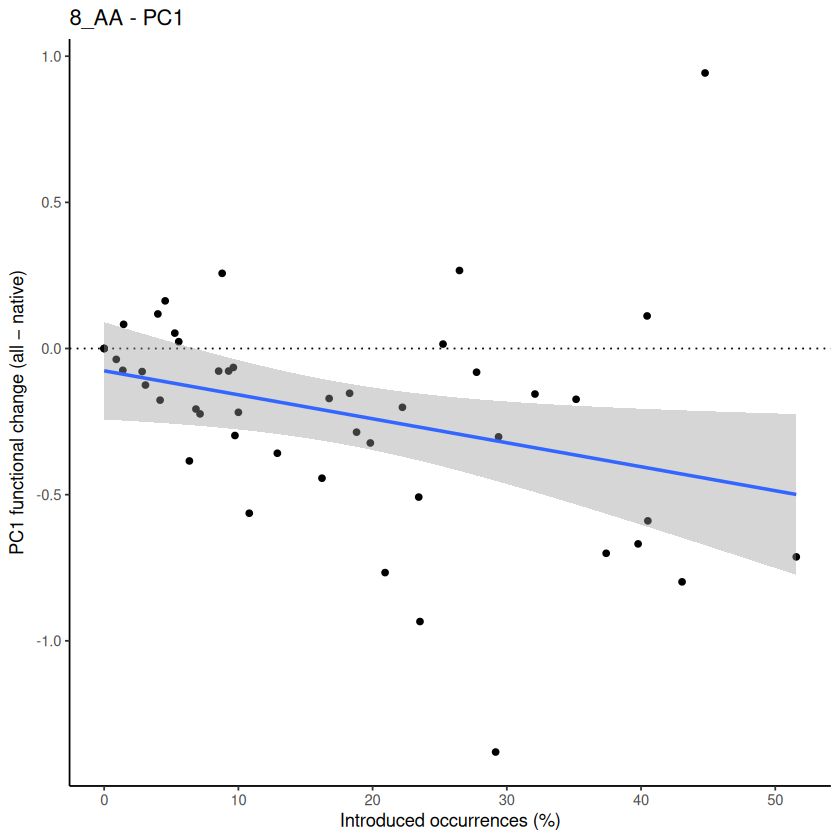

`geom_smooth()` using formula = 'y ~ x'


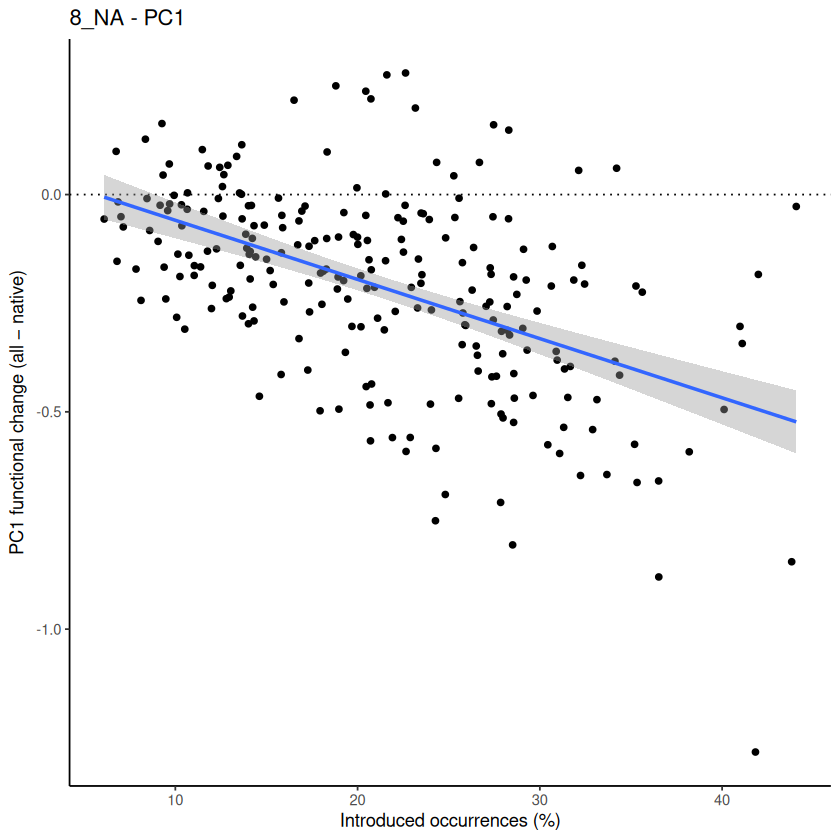

`geom_smooth()` using formula = 'y ~ x'


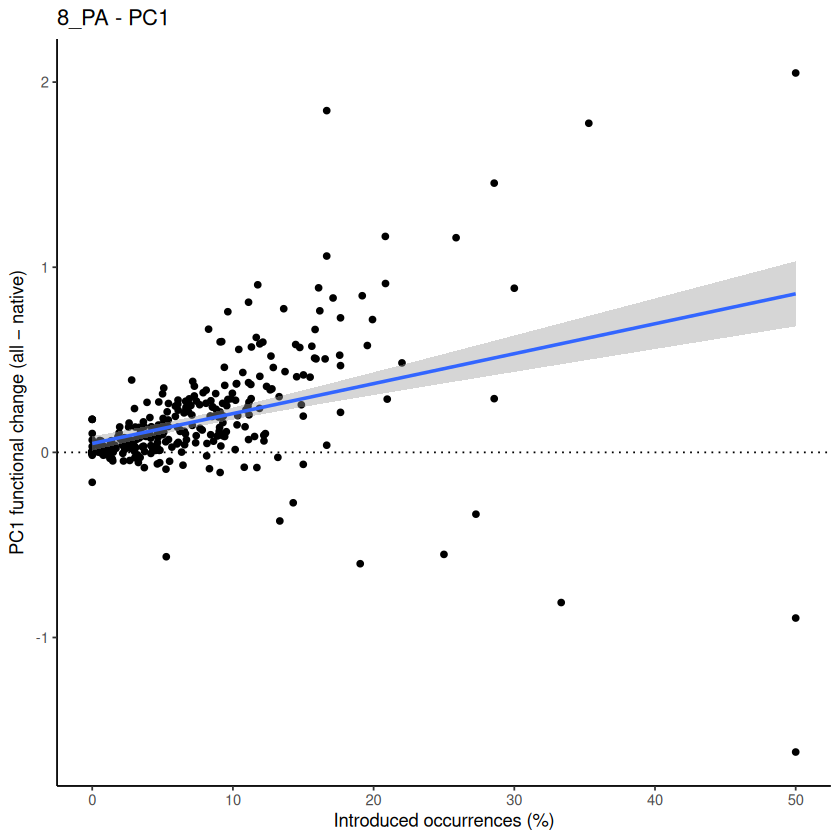

`geom_smooth()` using formula = 'y ~ x'


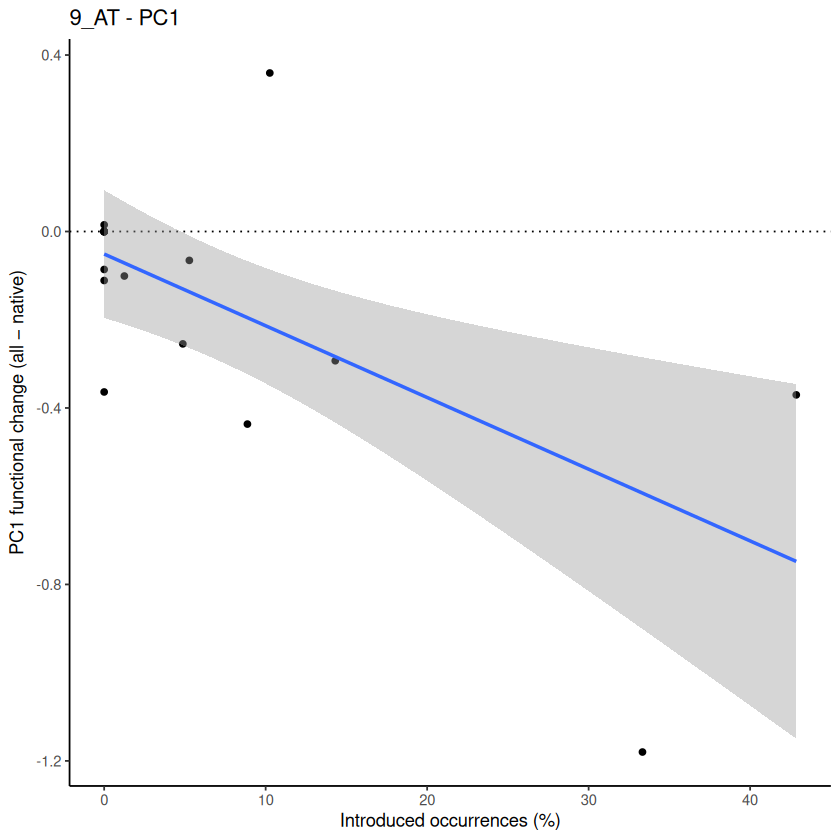

`geom_smooth()` using formula = 'y ~ x'


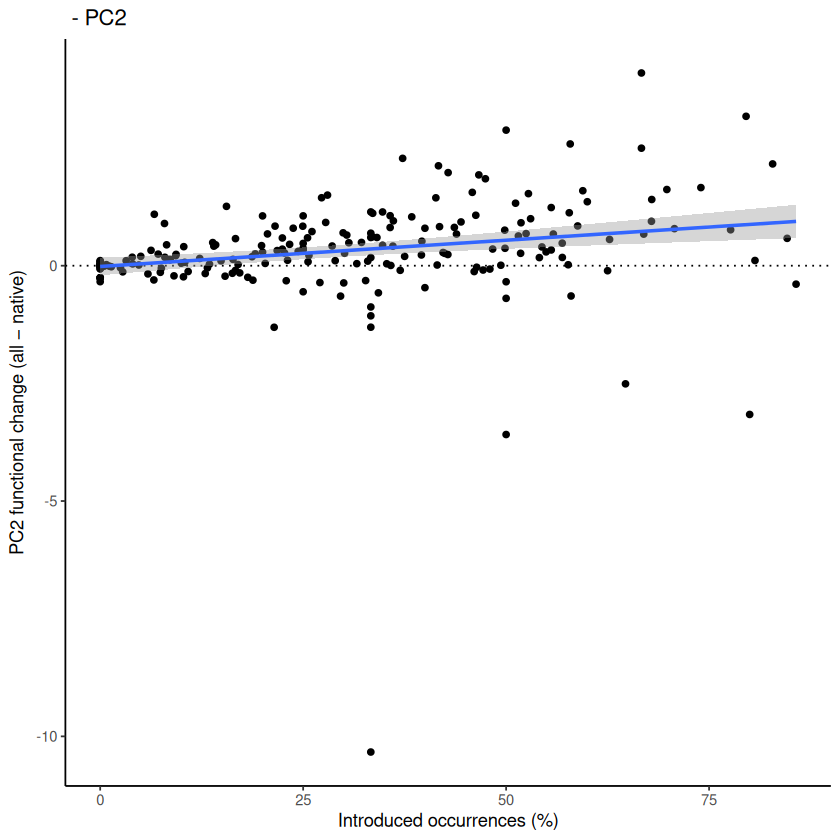

`geom_smooth()` using formula = 'y ~ x'


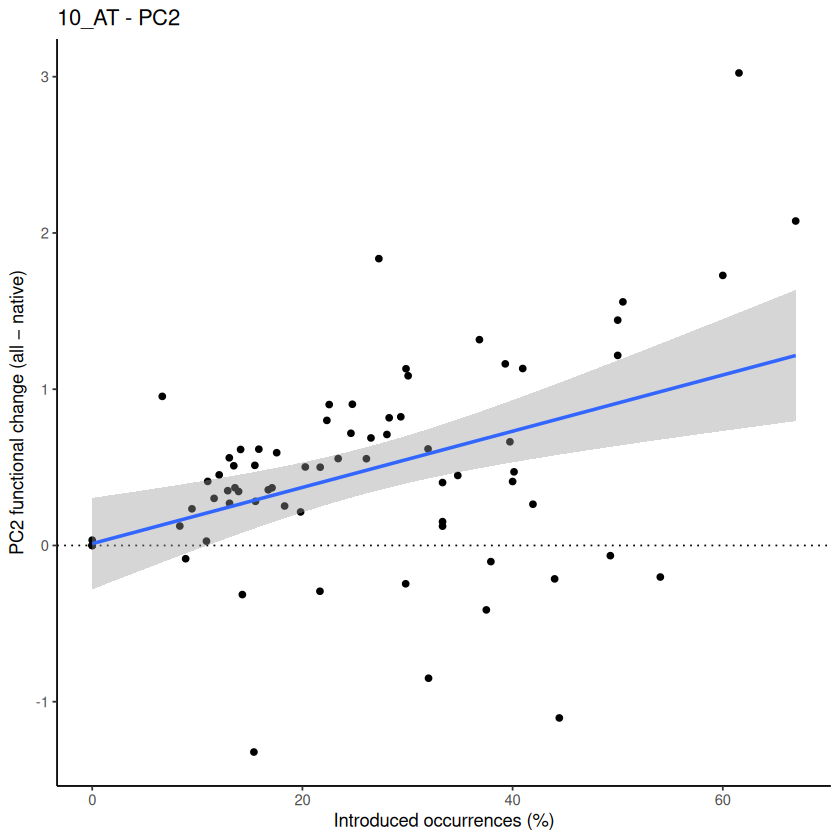

`geom_smooth()` using formula = 'y ~ x'


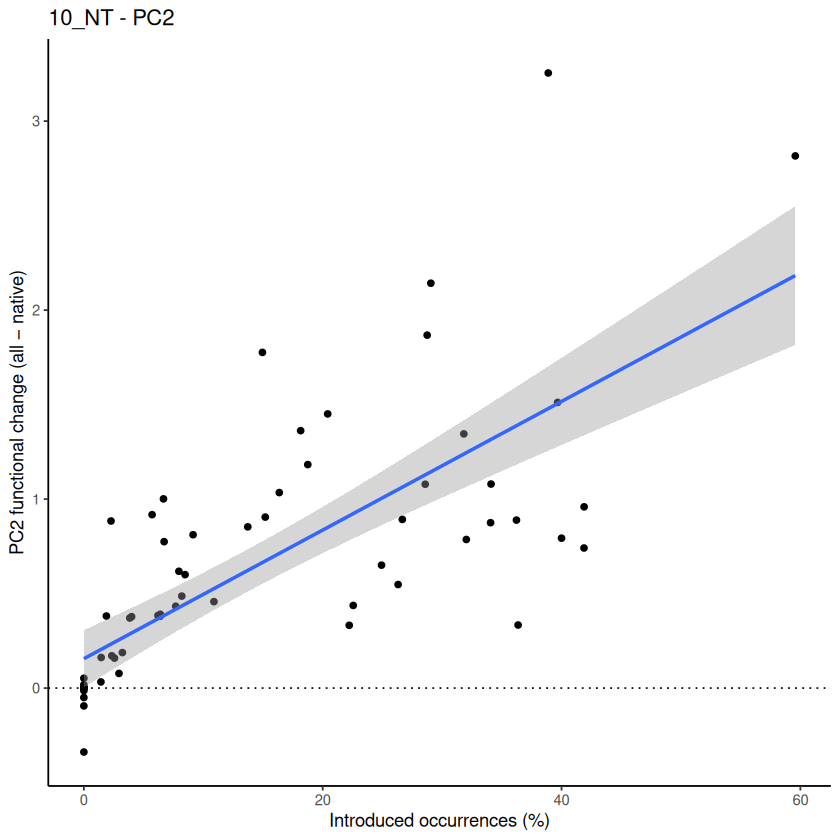

`geom_smooth()` using formula = 'y ~ x'


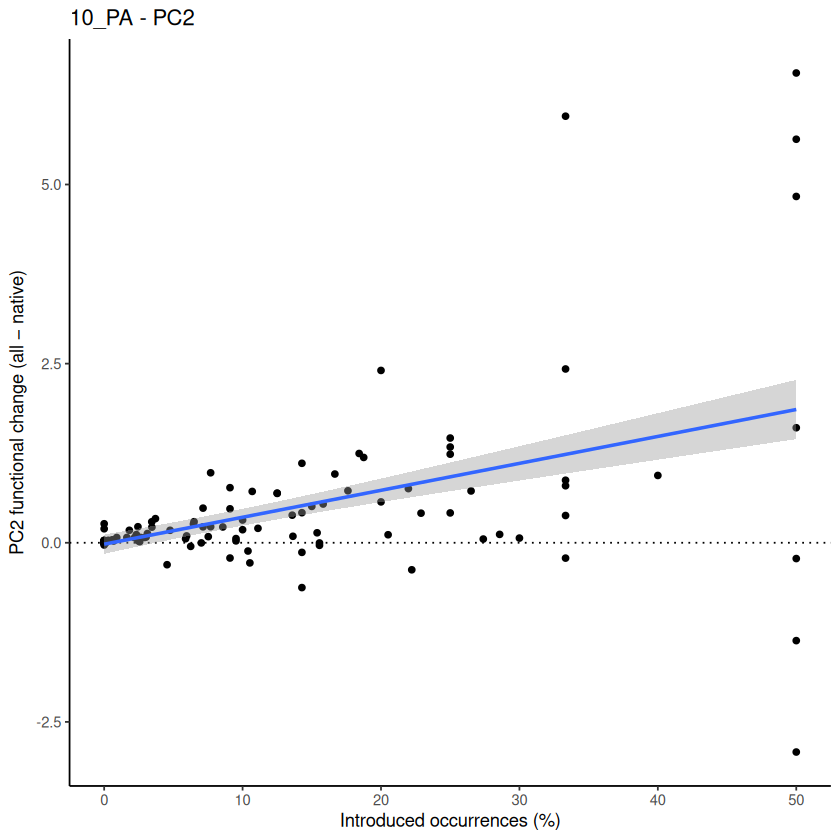

`geom_smooth()` using formula = 'y ~ x'


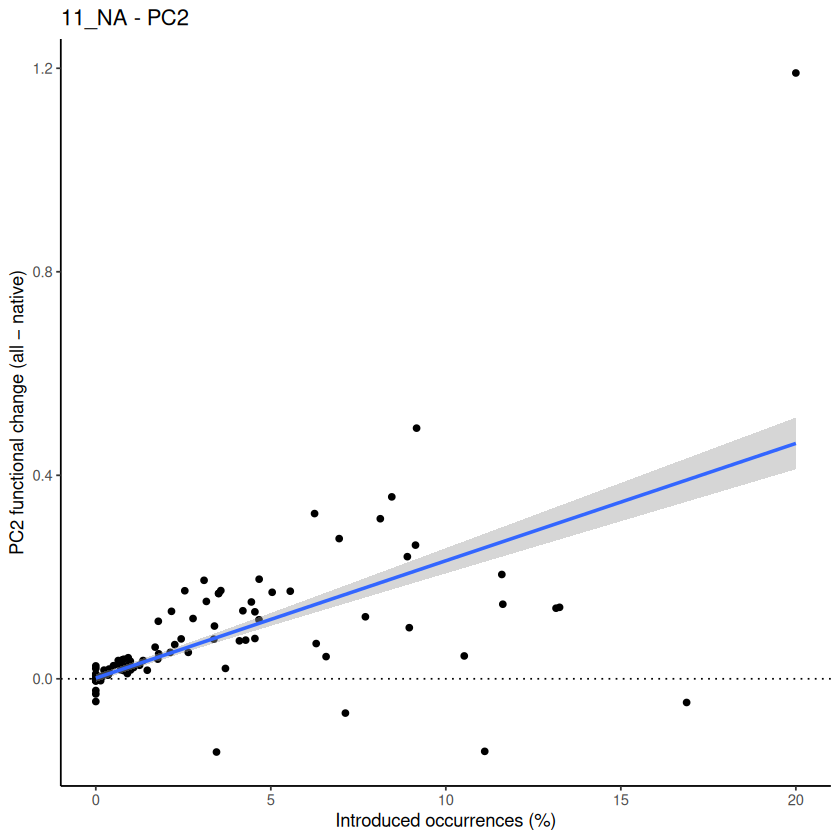

`geom_smooth()` using formula = 'y ~ x'


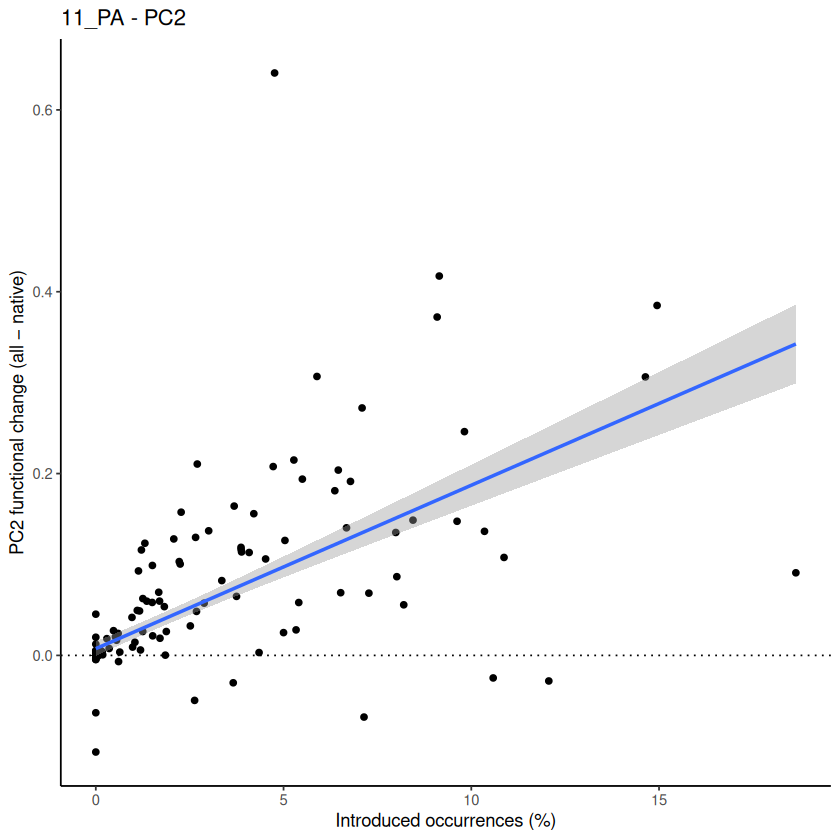

`geom_smooth()` using formula = 'y ~ x'


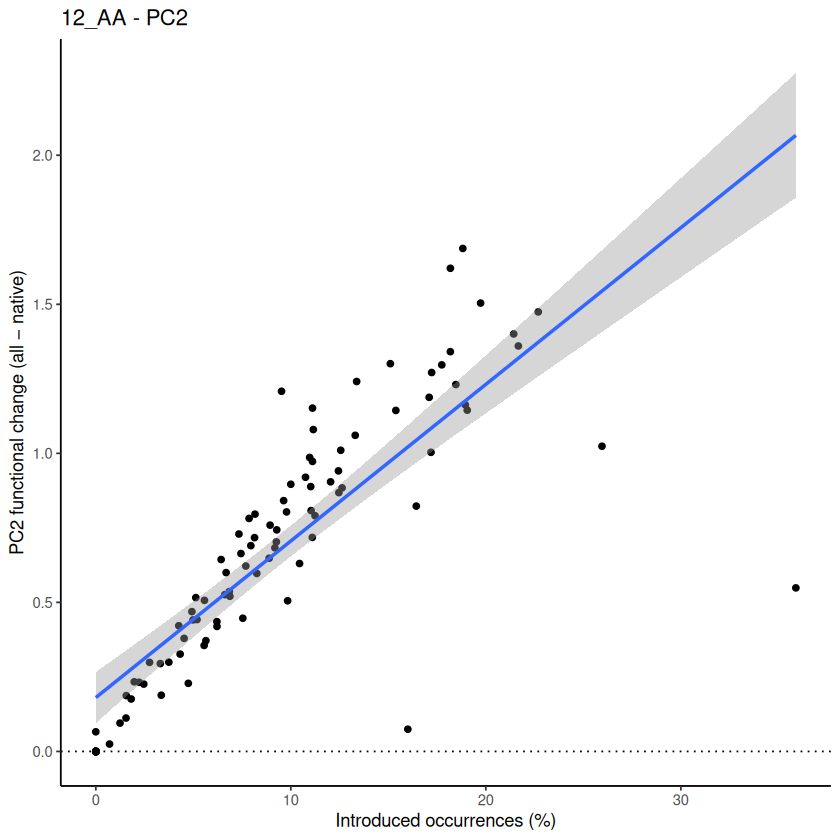

`geom_smooth()` using formula = 'y ~ x'


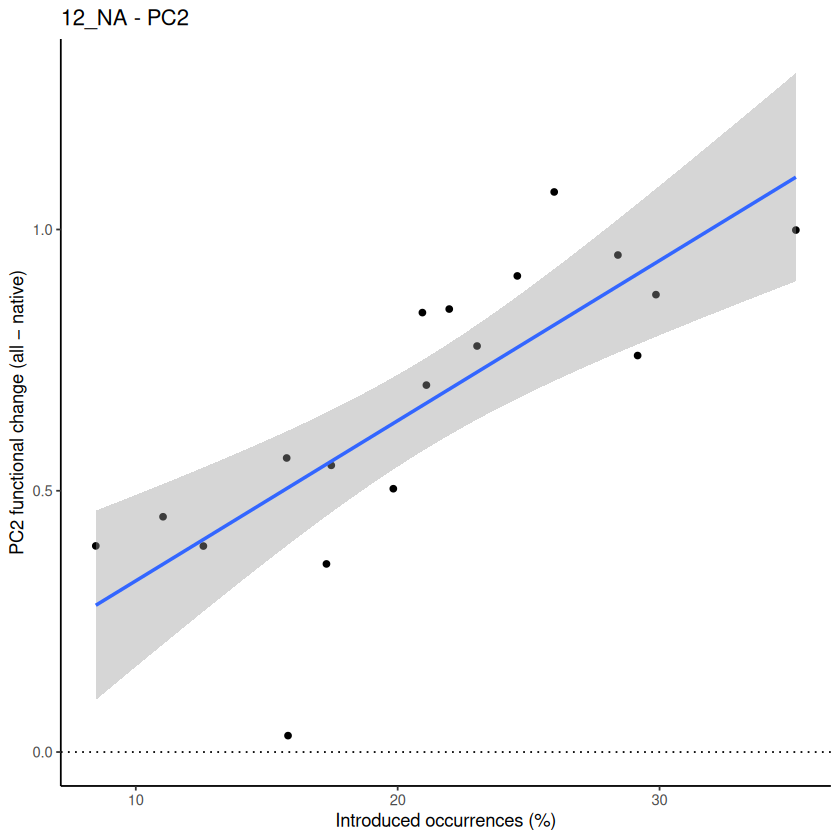

`geom_smooth()` using formula = 'y ~ x'


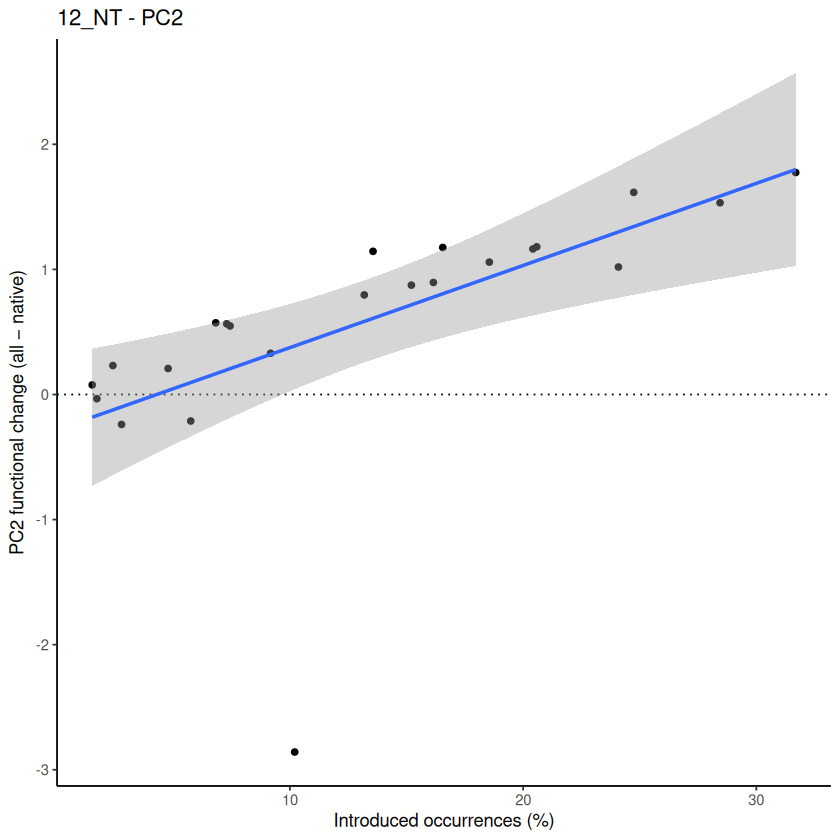

`geom_smooth()` using formula = 'y ~ x'


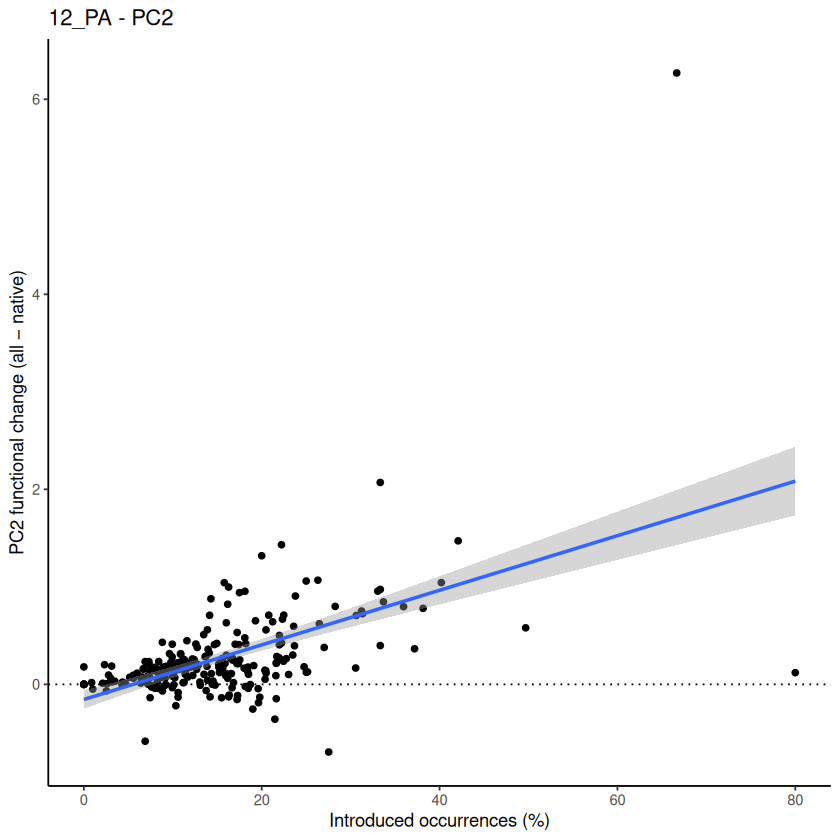

`geom_smooth()` using formula = 'y ~ x'


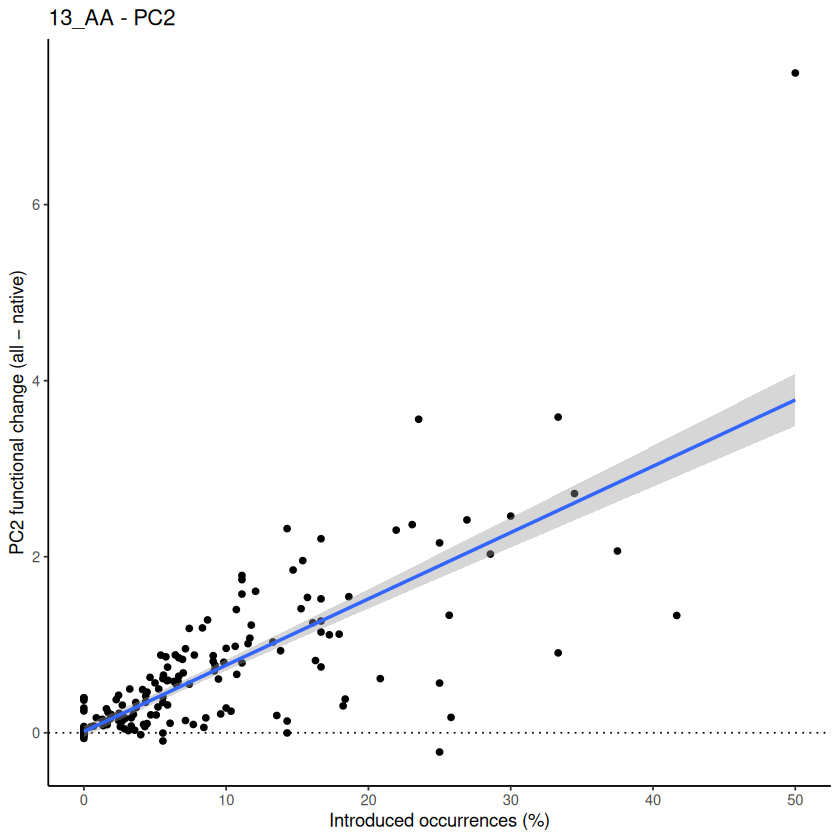

`geom_smooth()` using formula = 'y ~ x'


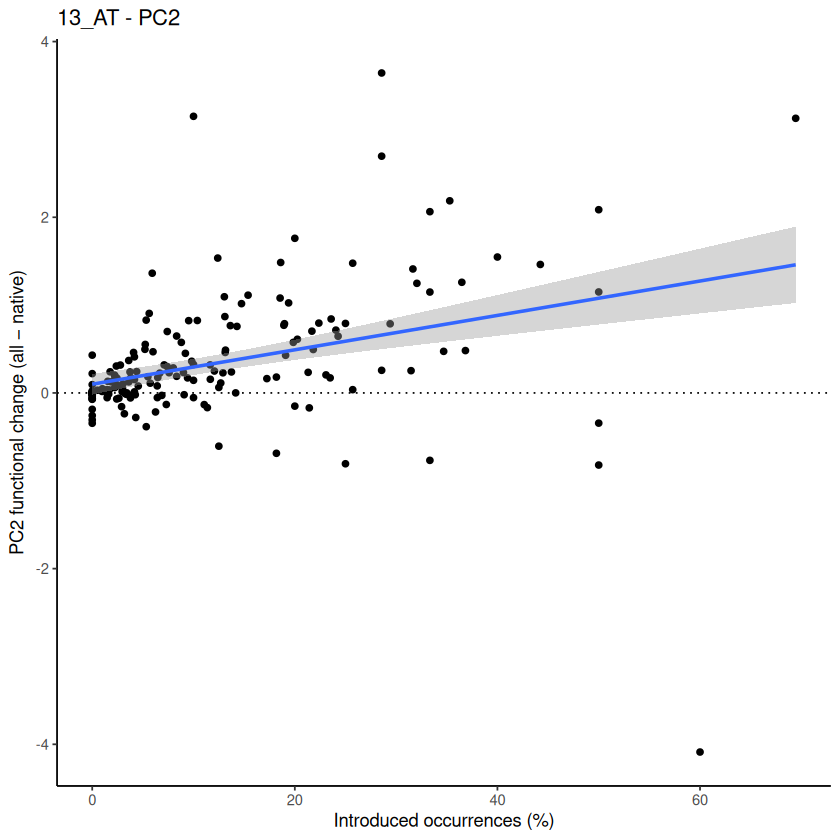

`geom_smooth()` using formula = 'y ~ x'


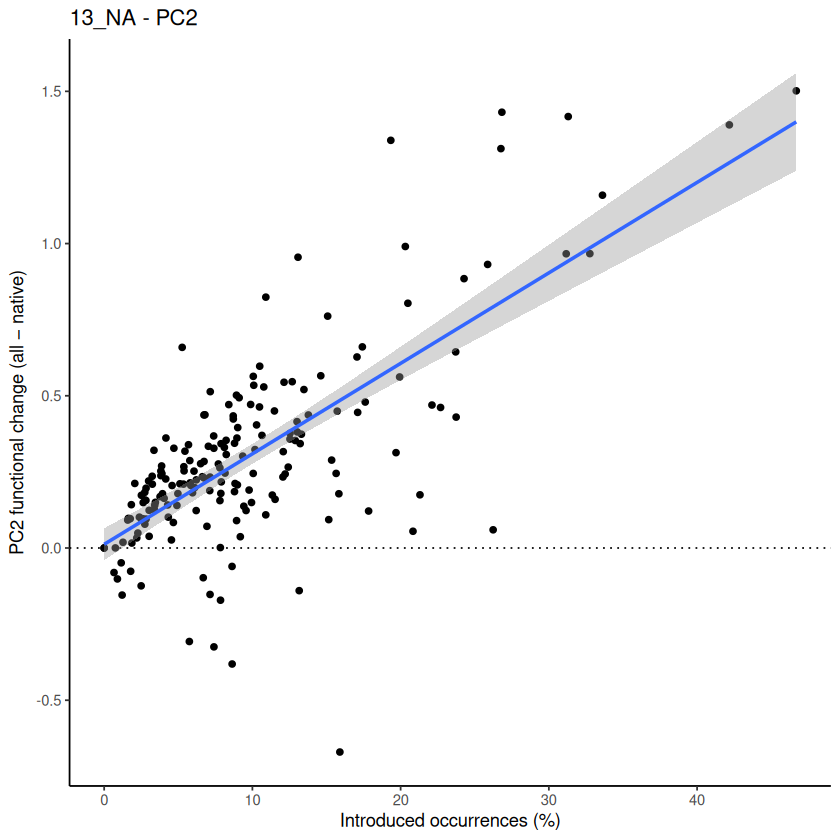

`geom_smooth()` using formula = 'y ~ x'


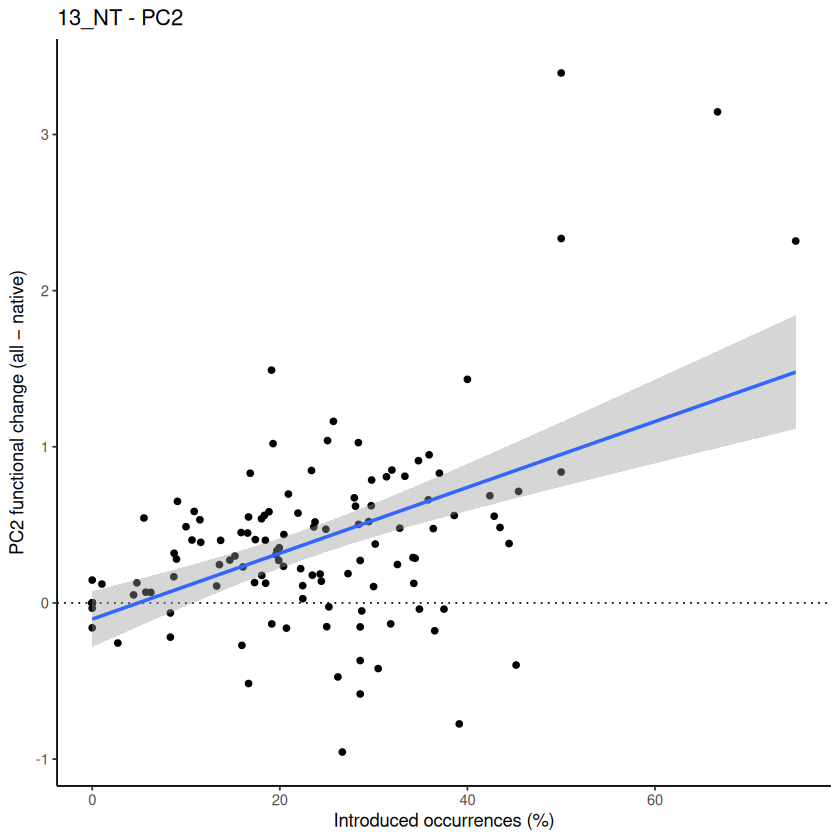

`geom_smooth()` using formula = 'y ~ x'


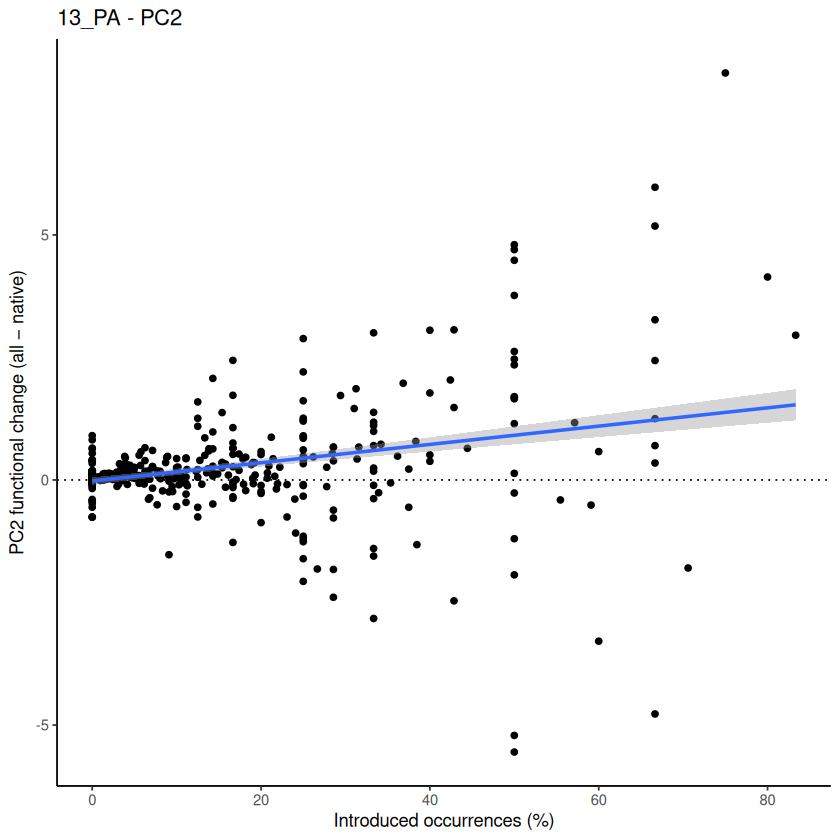

`geom_smooth()` using formula = 'y ~ x'


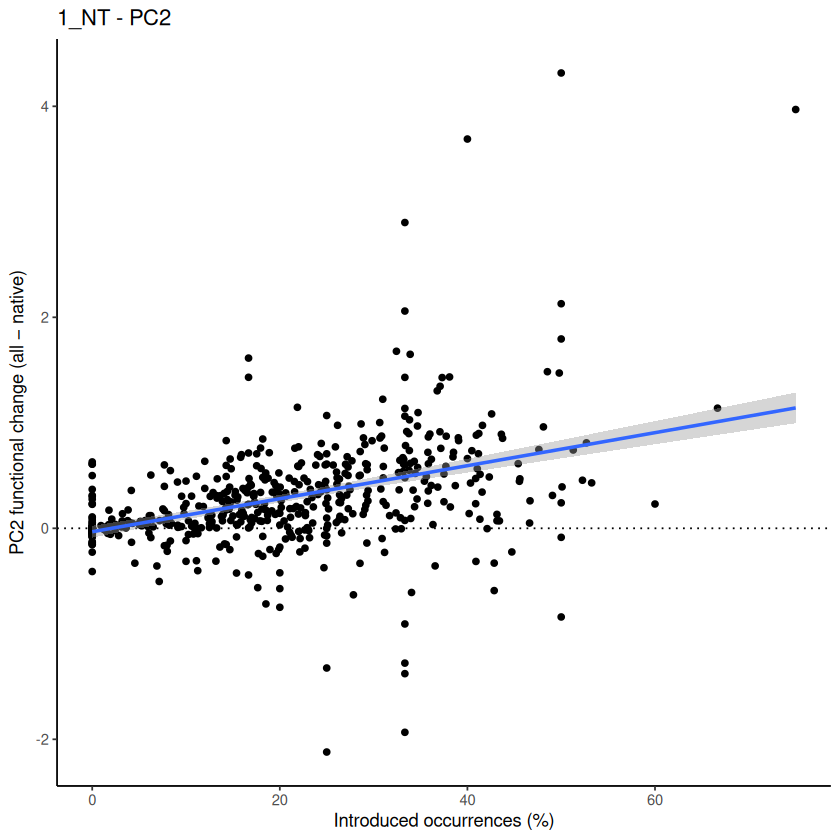

`geom_smooth()` using formula = 'y ~ x'


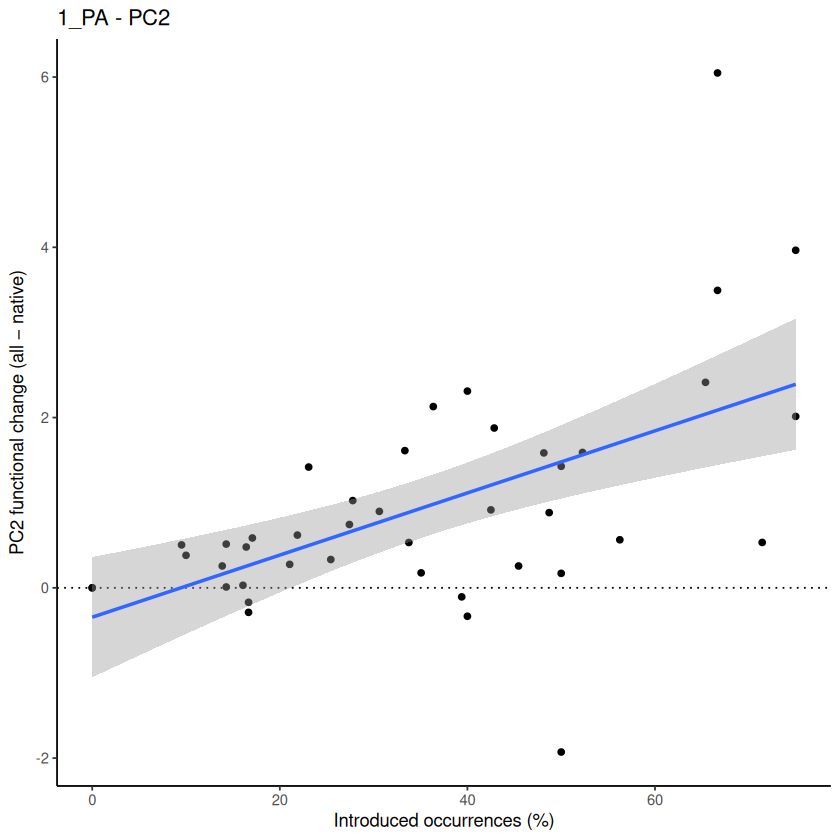

`geom_smooth()` using formula = 'y ~ x'


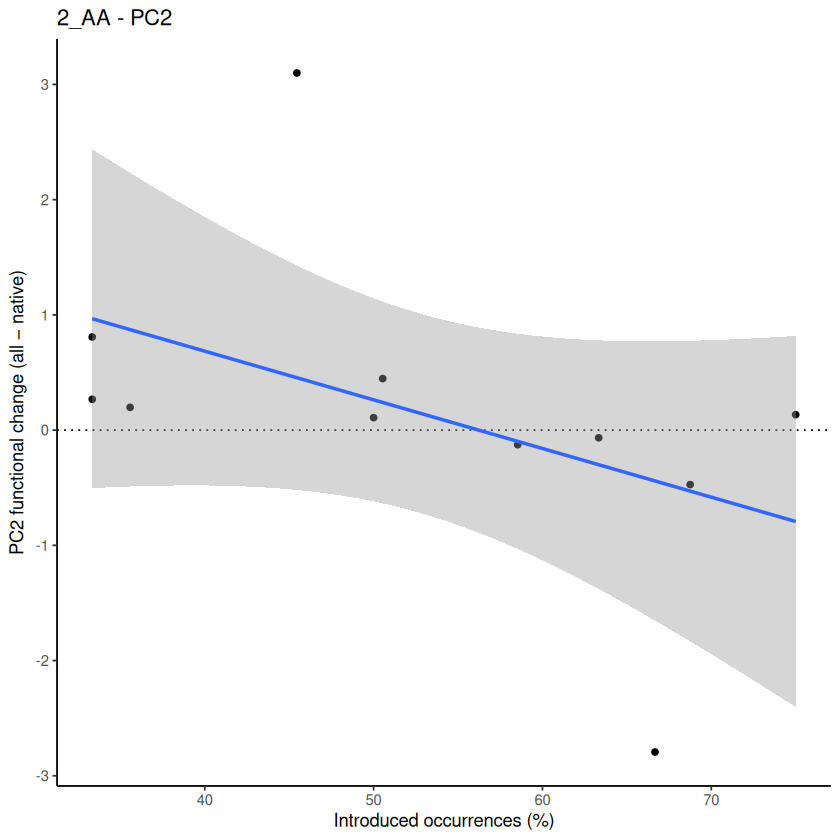

`geom_smooth()` using formula = 'y ~ x'


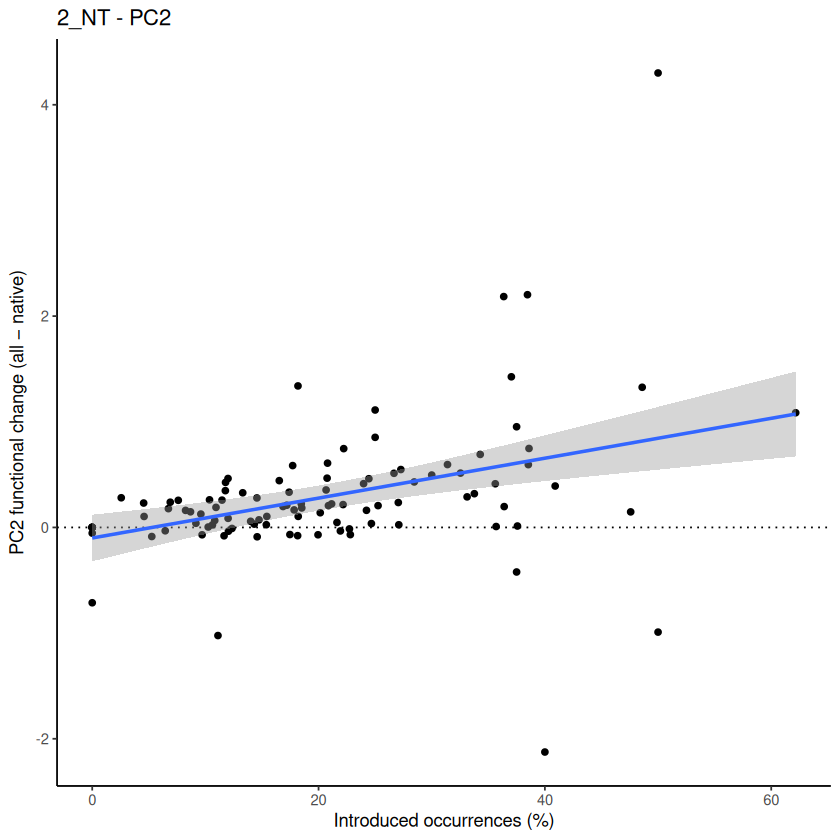

`geom_smooth()` using formula = 'y ~ x'


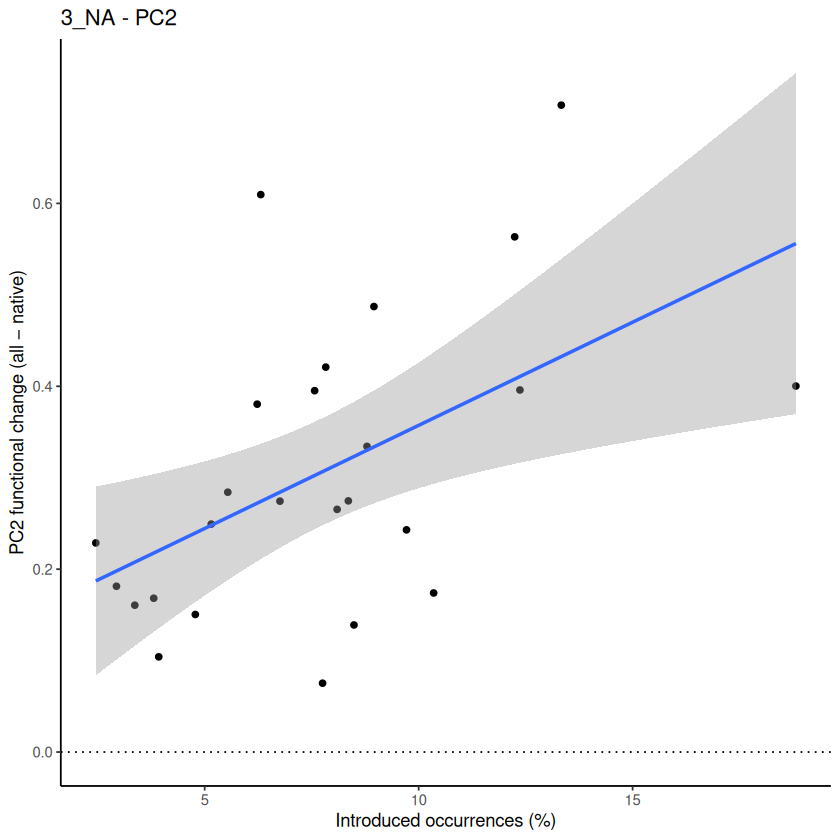

`geom_smooth()` using formula = 'y ~ x'


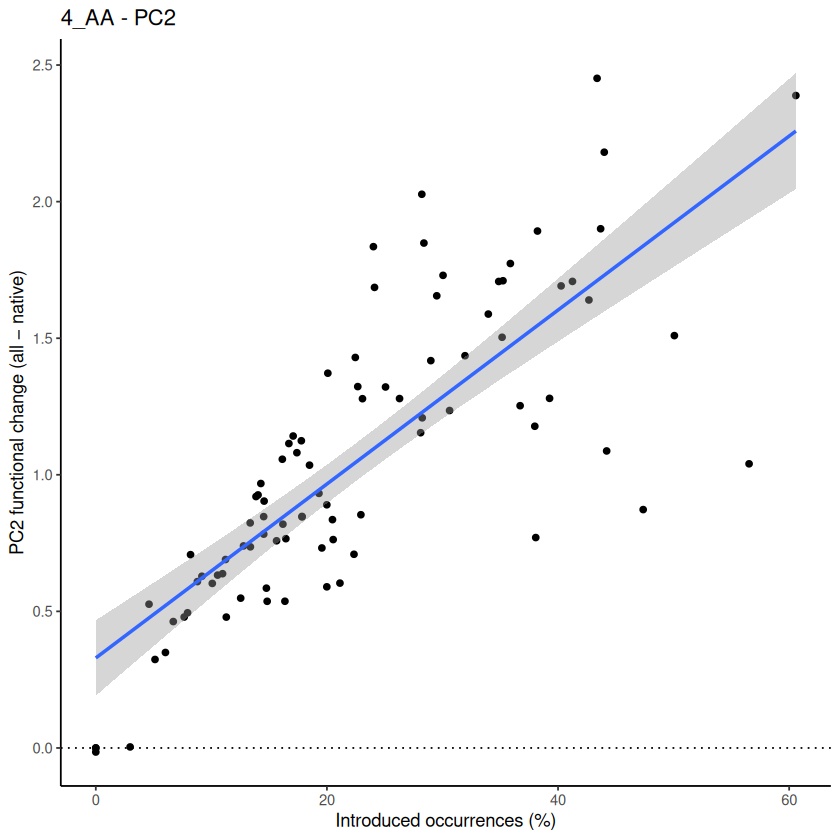

`geom_smooth()` using formula = 'y ~ x'


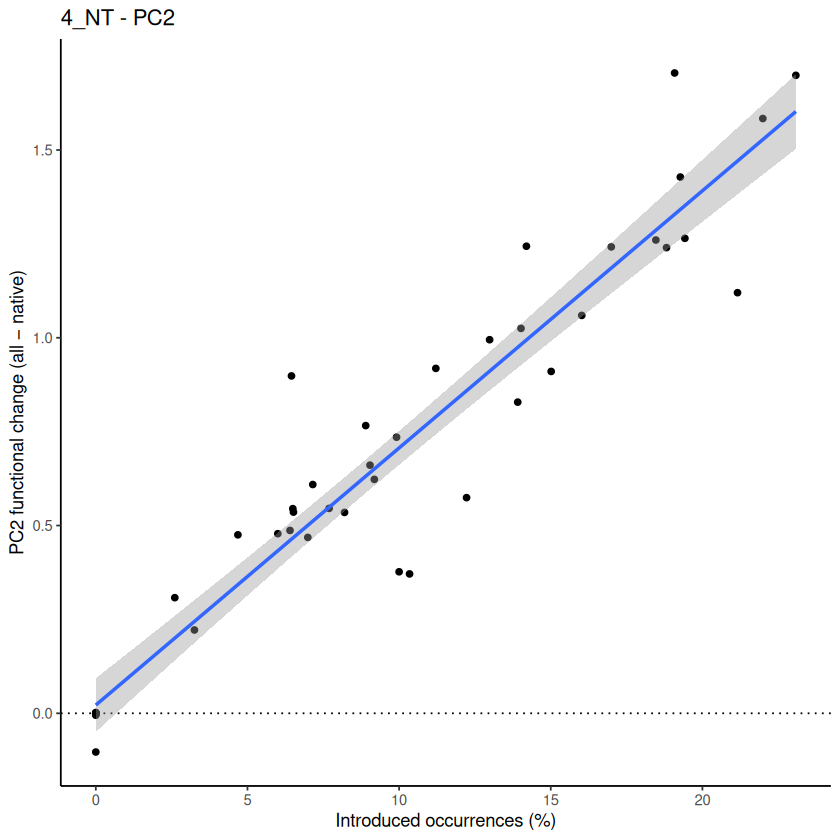

`geom_smooth()` using formula = 'y ~ x'


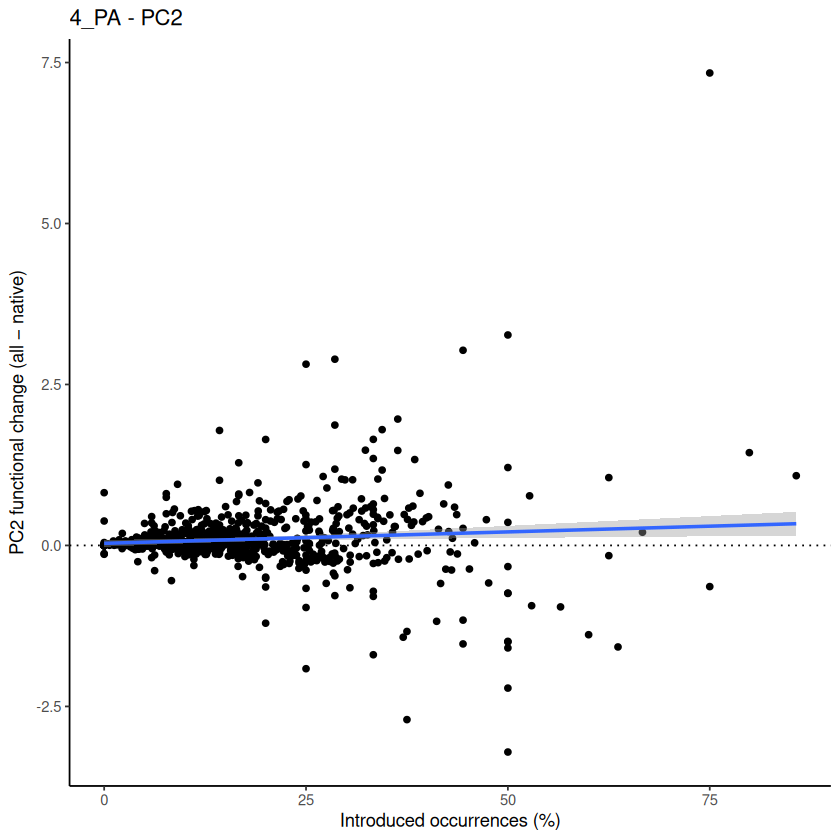

`geom_smooth()` using formula = 'y ~ x'


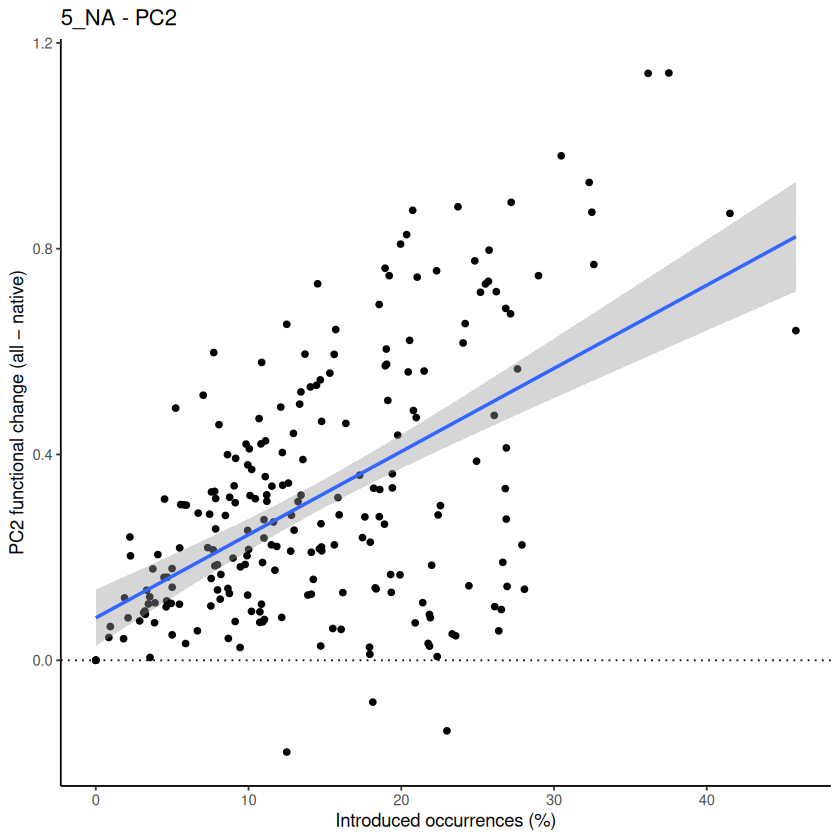

`geom_smooth()` using formula = 'y ~ x'


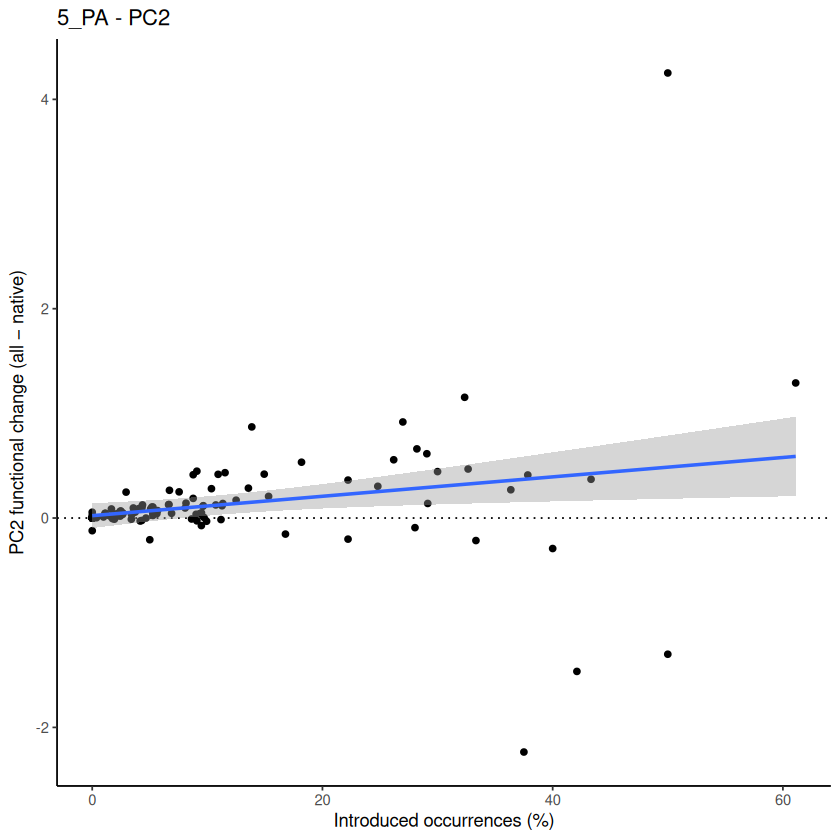

`geom_smooth()` using formula = 'y ~ x'


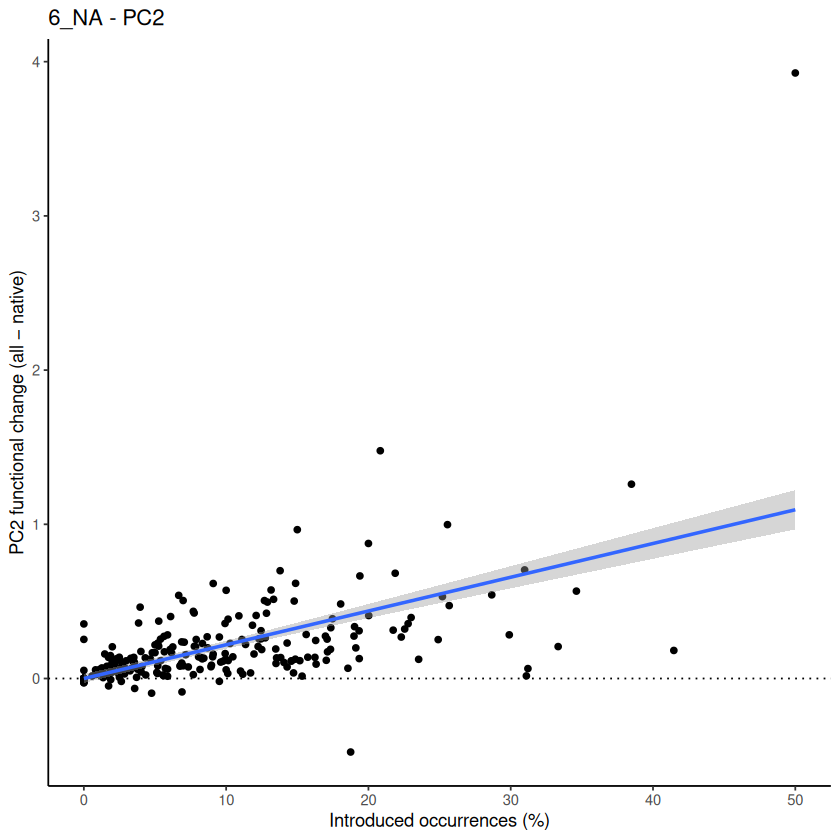

`geom_smooth()` using formula = 'y ~ x'


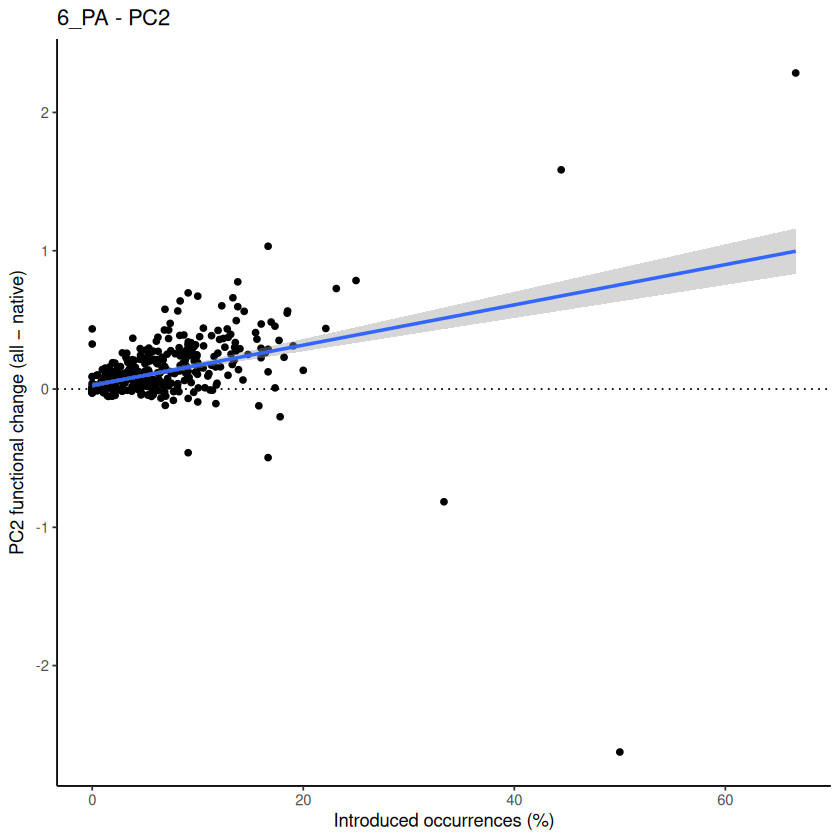

`geom_smooth()` using formula = 'y ~ x'


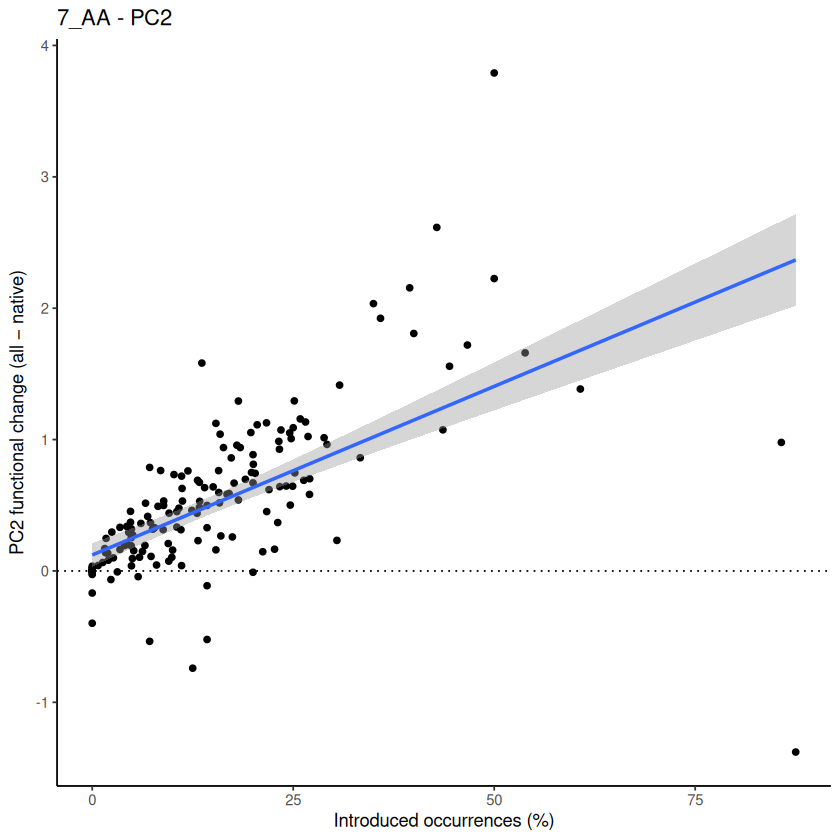

`geom_smooth()` using formula = 'y ~ x'


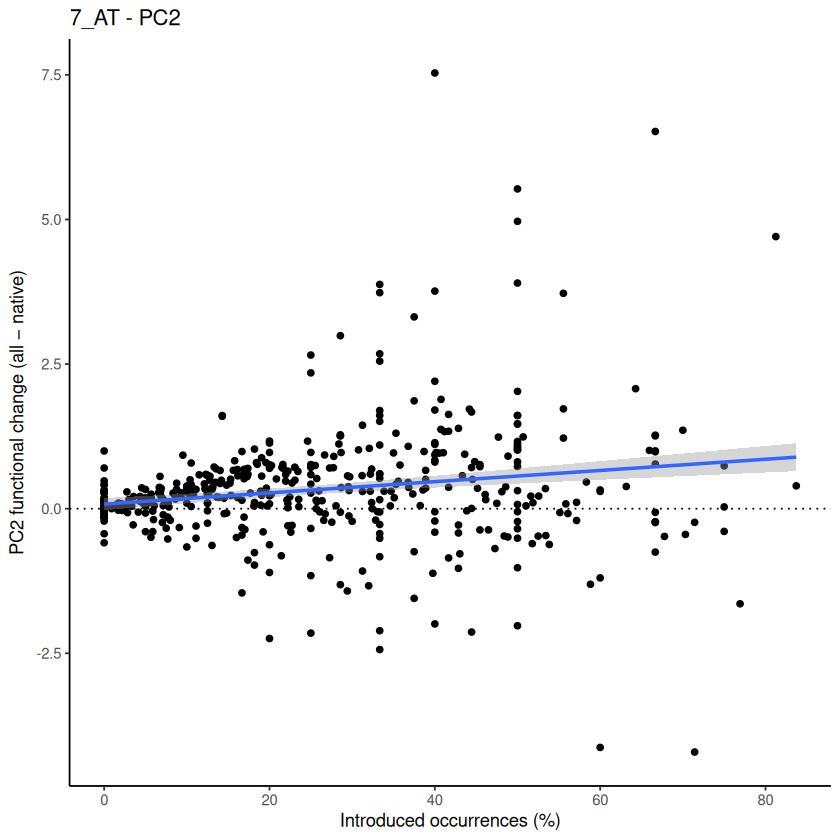

`geom_smooth()` using formula = 'y ~ x'


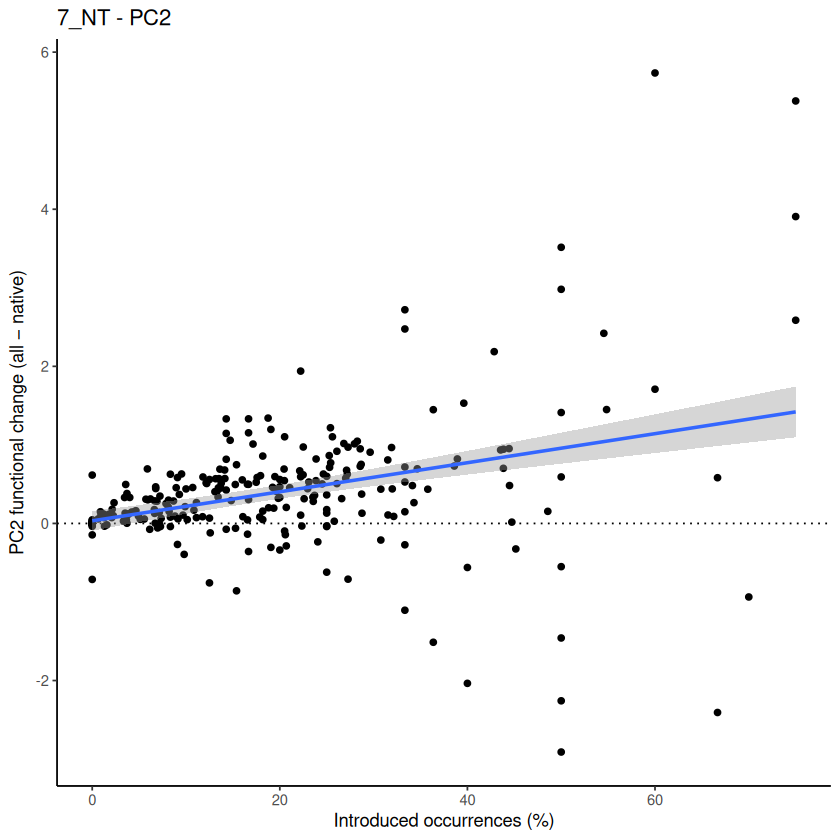

`geom_smooth()` using formula = 'y ~ x'


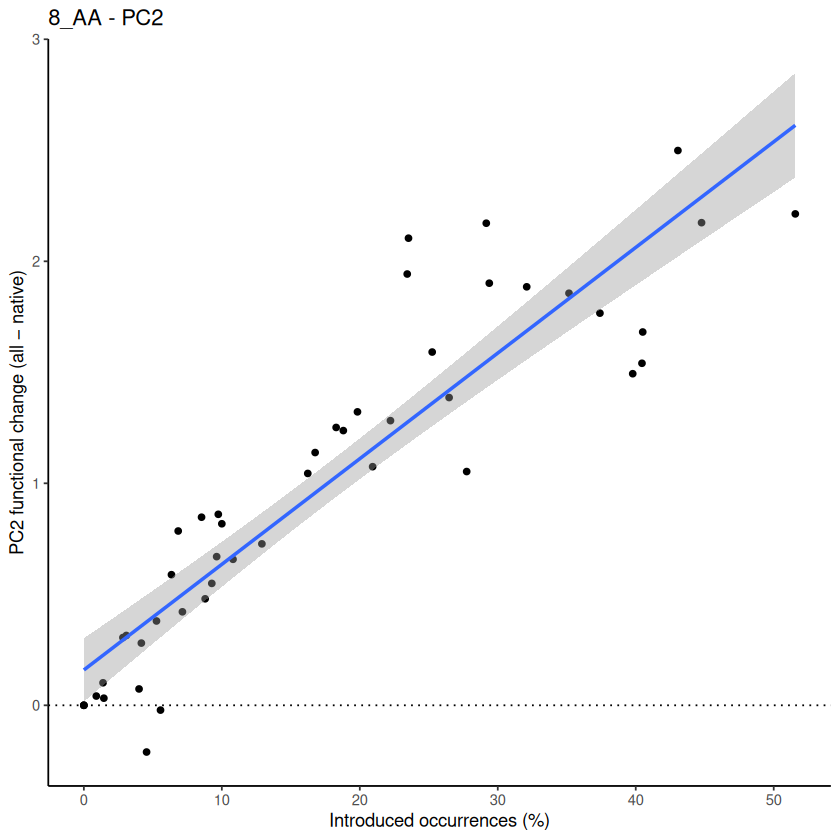

`geom_smooth()` using formula = 'y ~ x'


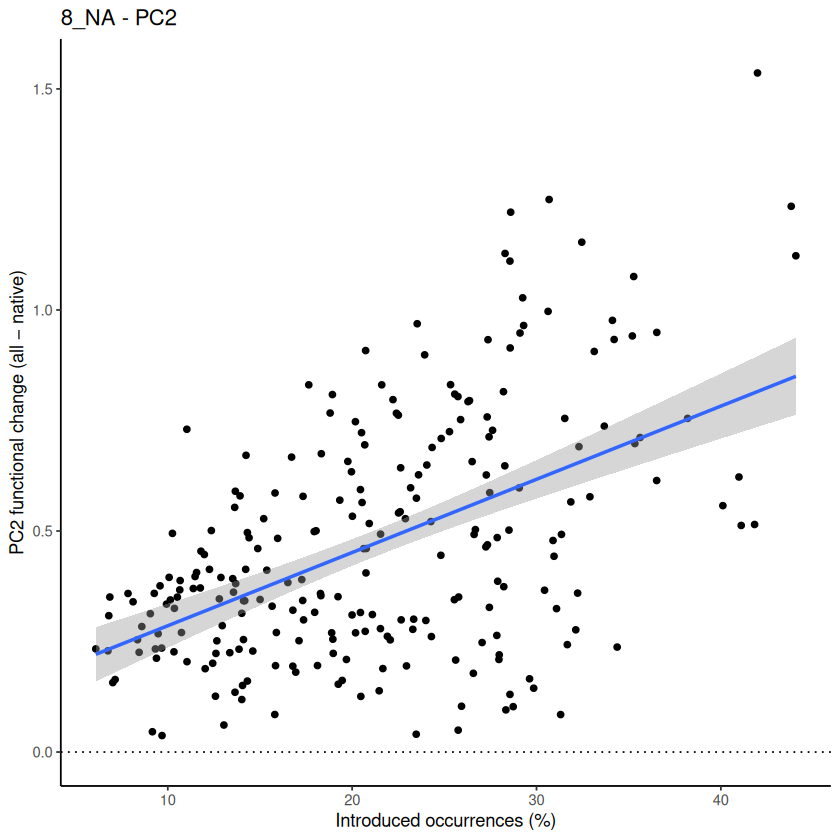

`geom_smooth()` using formula = 'y ~ x'


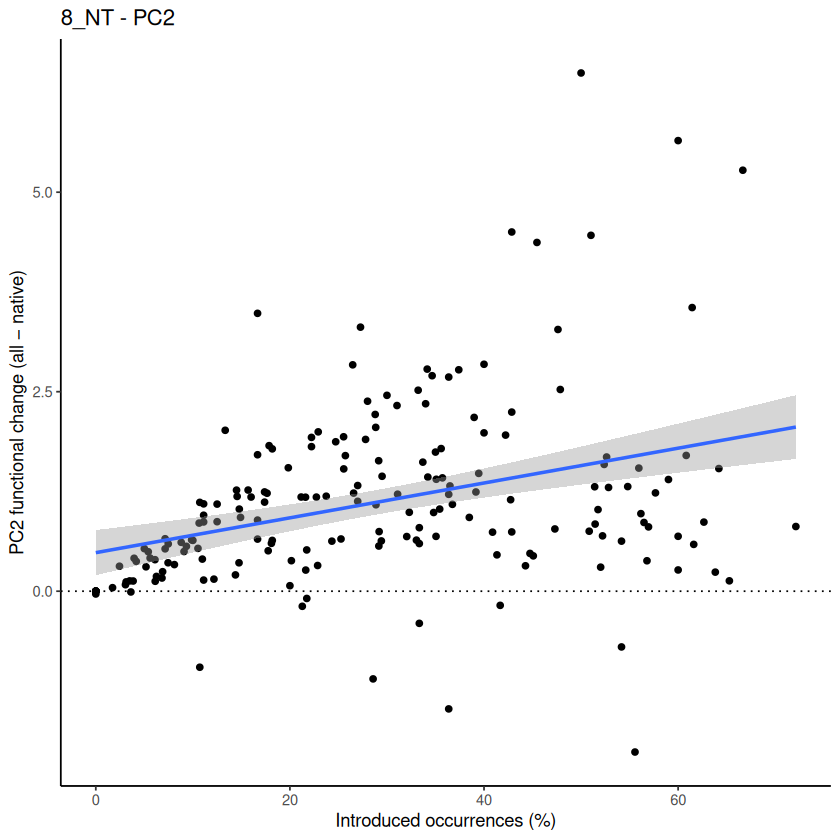

`geom_smooth()` using formula = 'y ~ x'


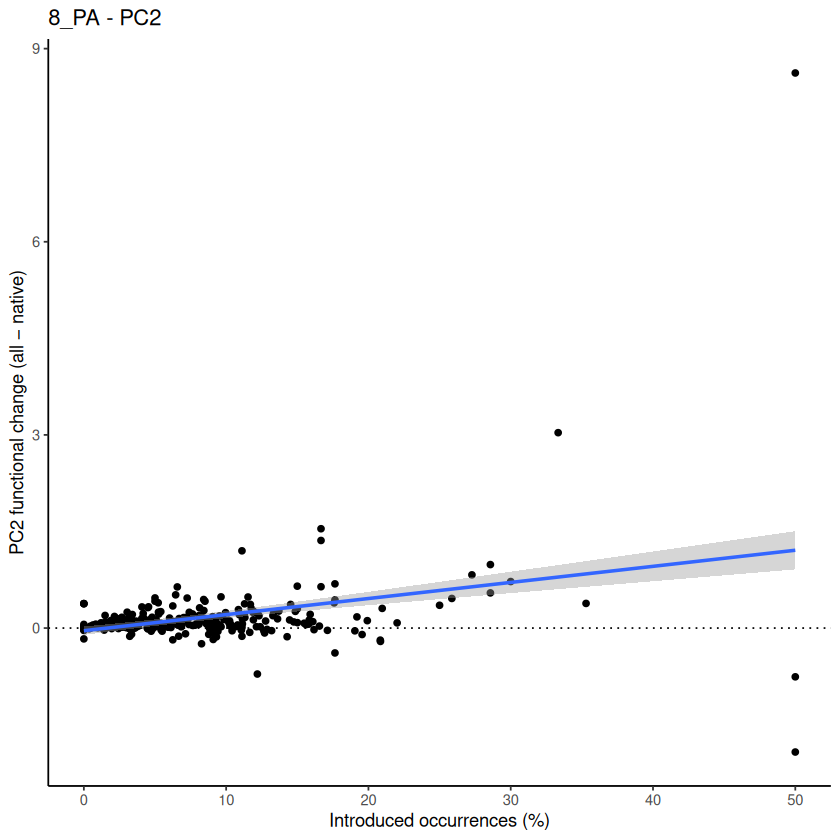

`geom_smooth()` using formula = 'y ~ x'


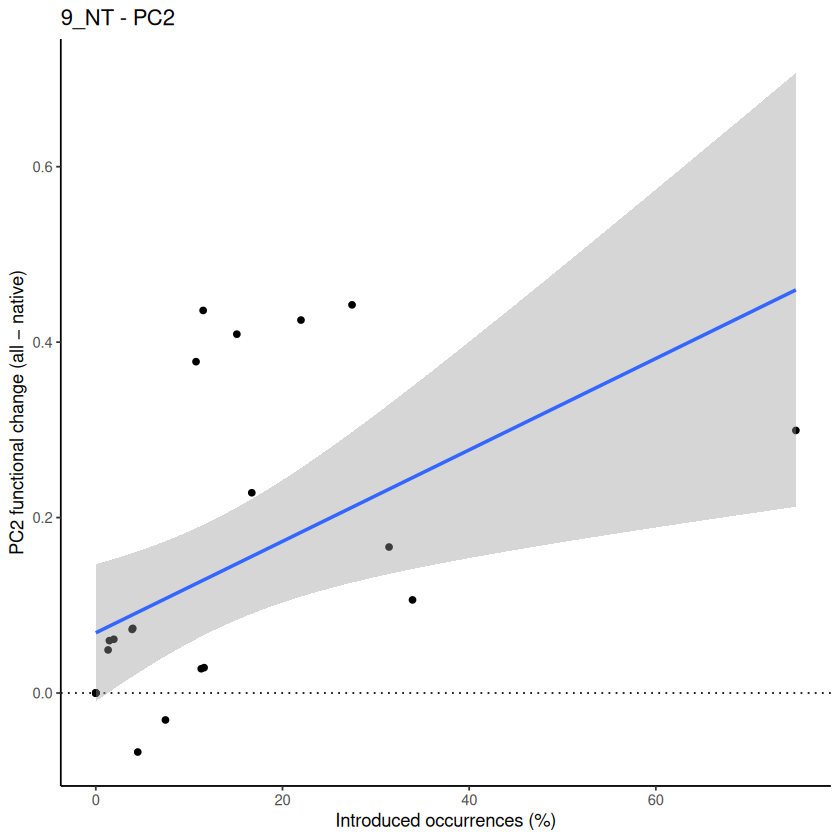

`geom_smooth()` using formula = 'y ~ x'


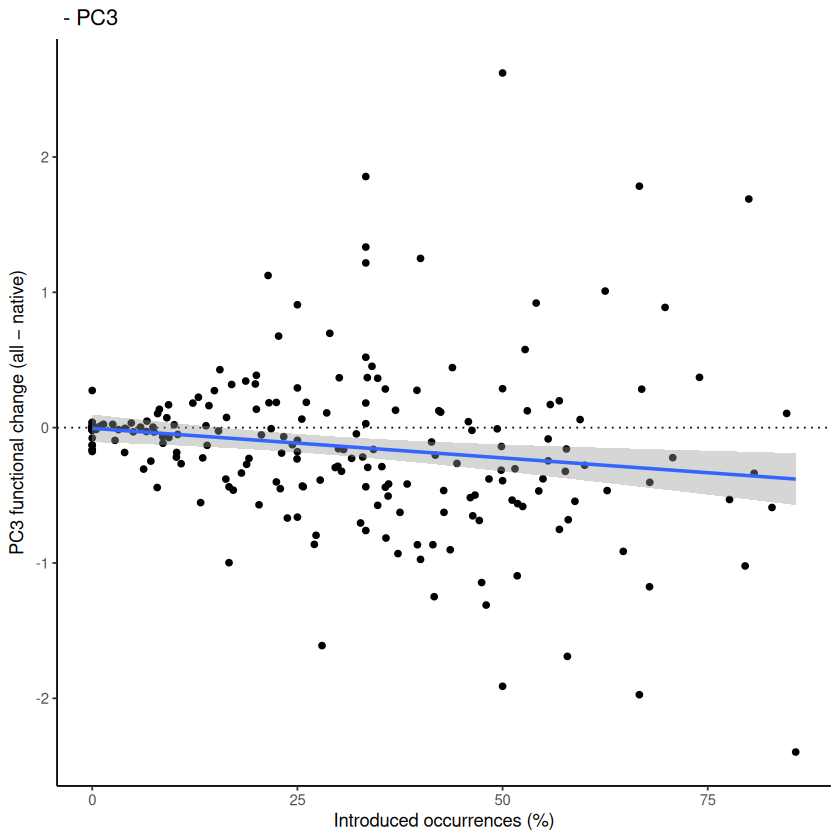

`geom_smooth()` using formula = 'y ~ x'


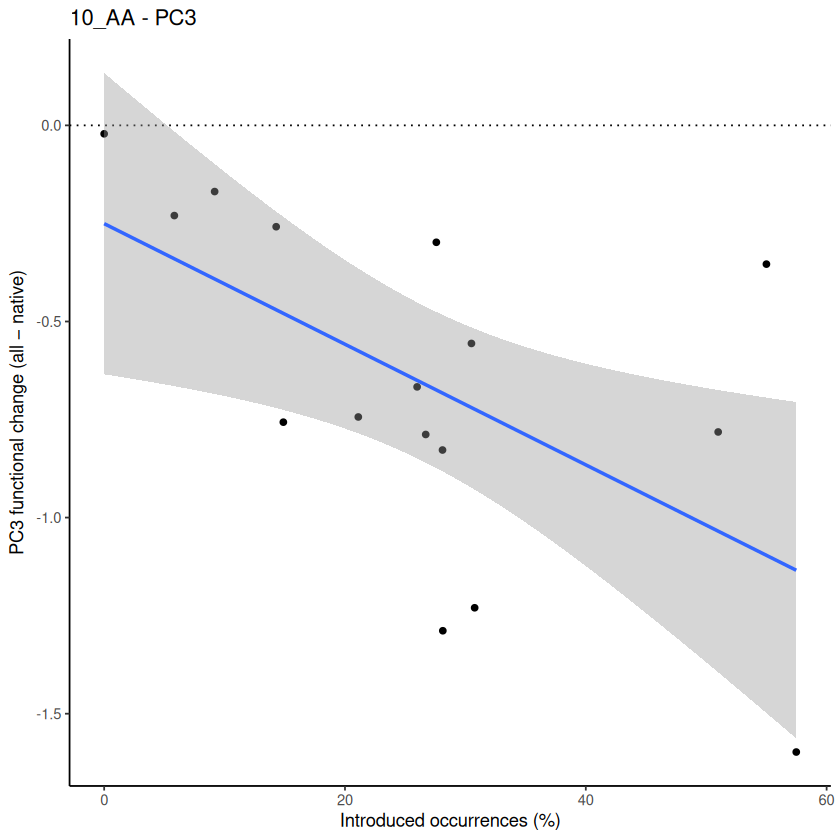

`geom_smooth()` using formula = 'y ~ x'


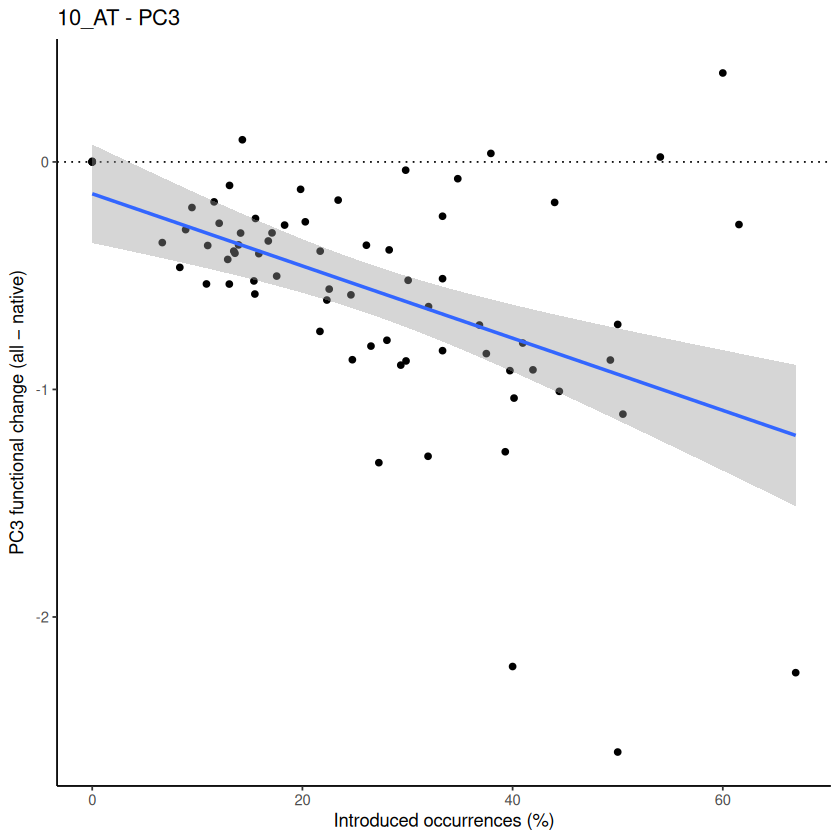

`geom_smooth()` using formula = 'y ~ x'


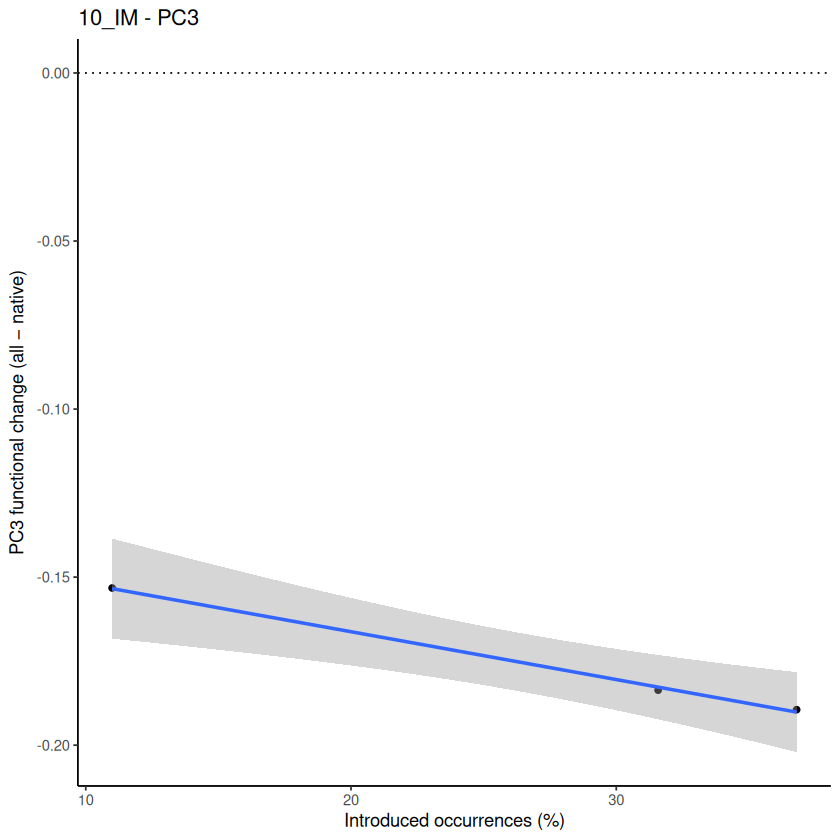

`geom_smooth()` using formula = 'y ~ x'


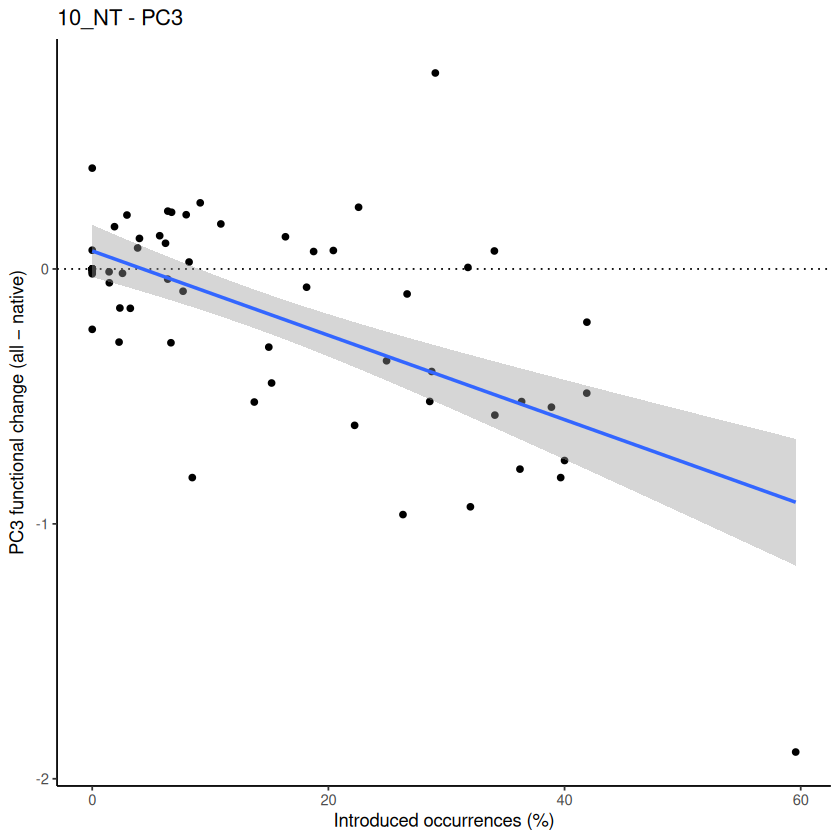

`geom_smooth()` using formula = 'y ~ x'


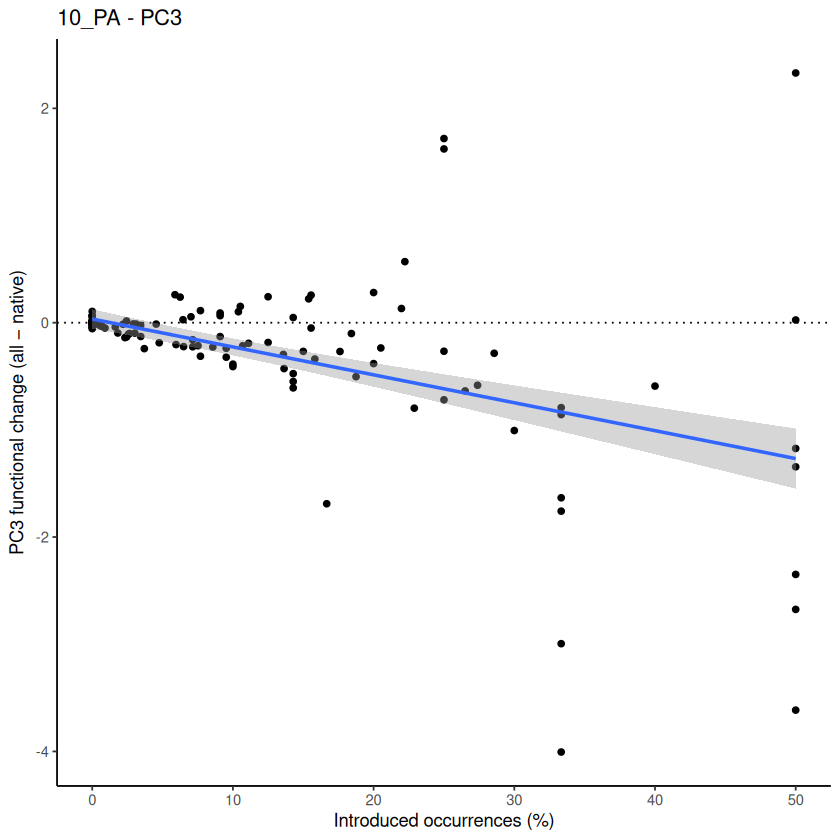

`geom_smooth()` using formula = 'y ~ x'


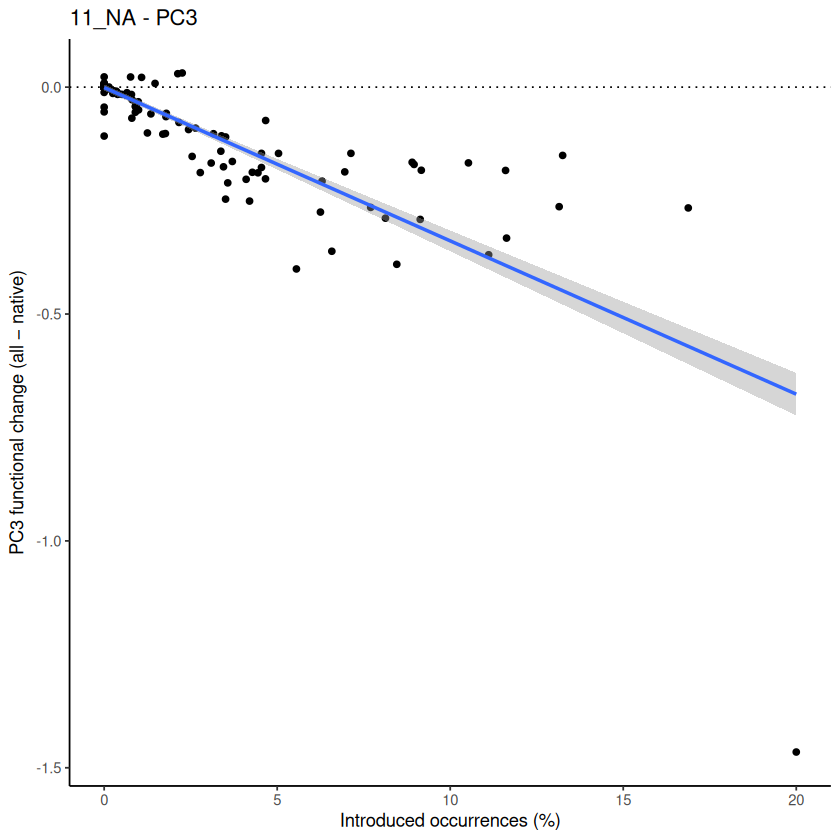

`geom_smooth()` using formula = 'y ~ x'


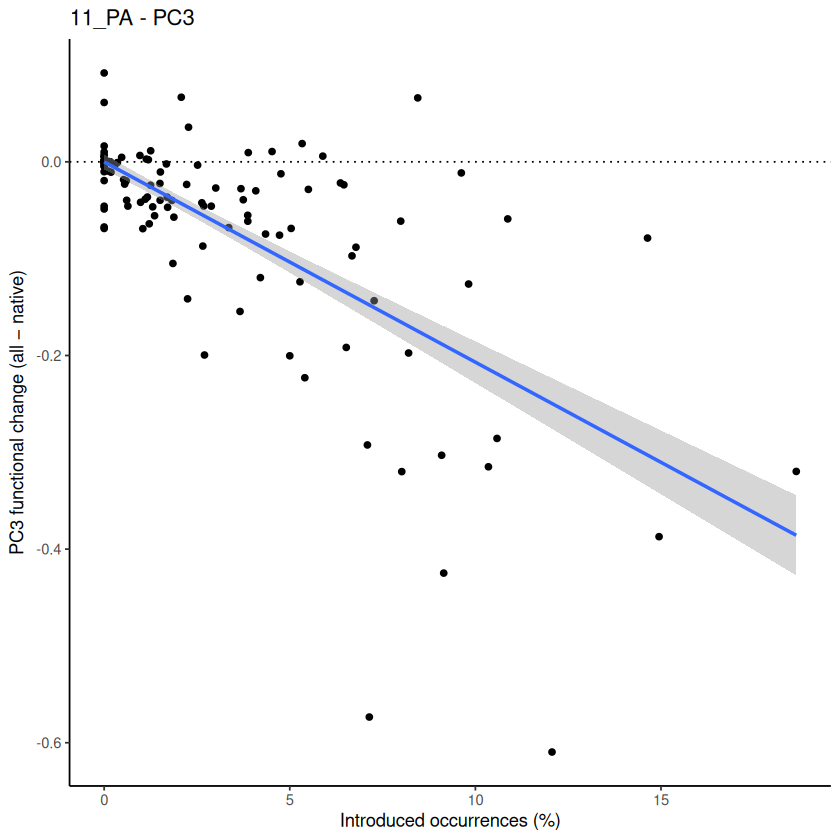

`geom_smooth()` using formula = 'y ~ x'


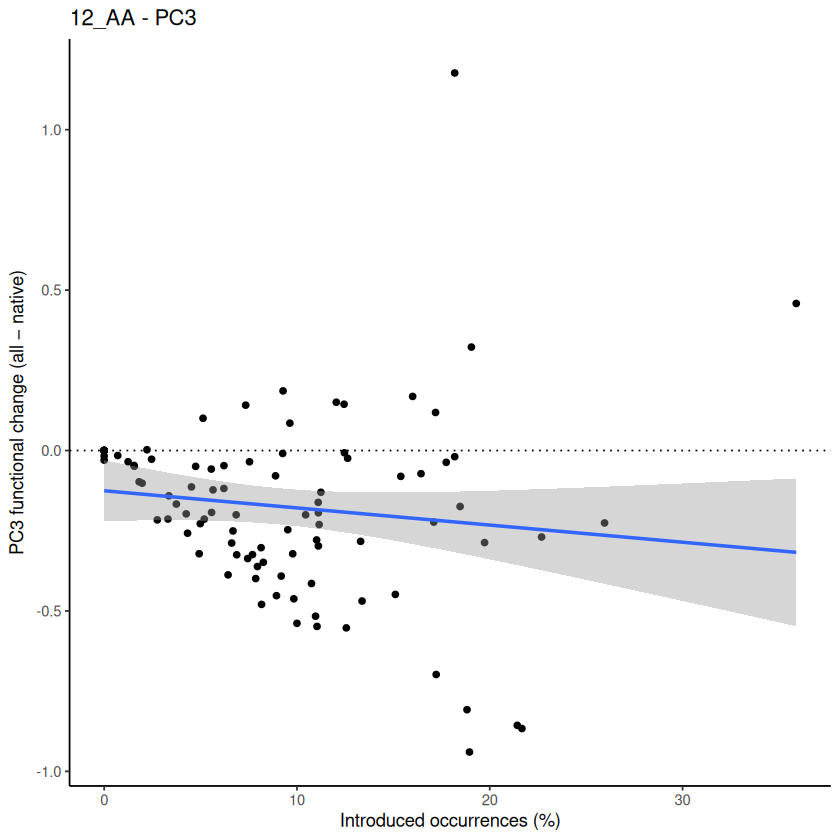

`geom_smooth()` using formula = 'y ~ x'


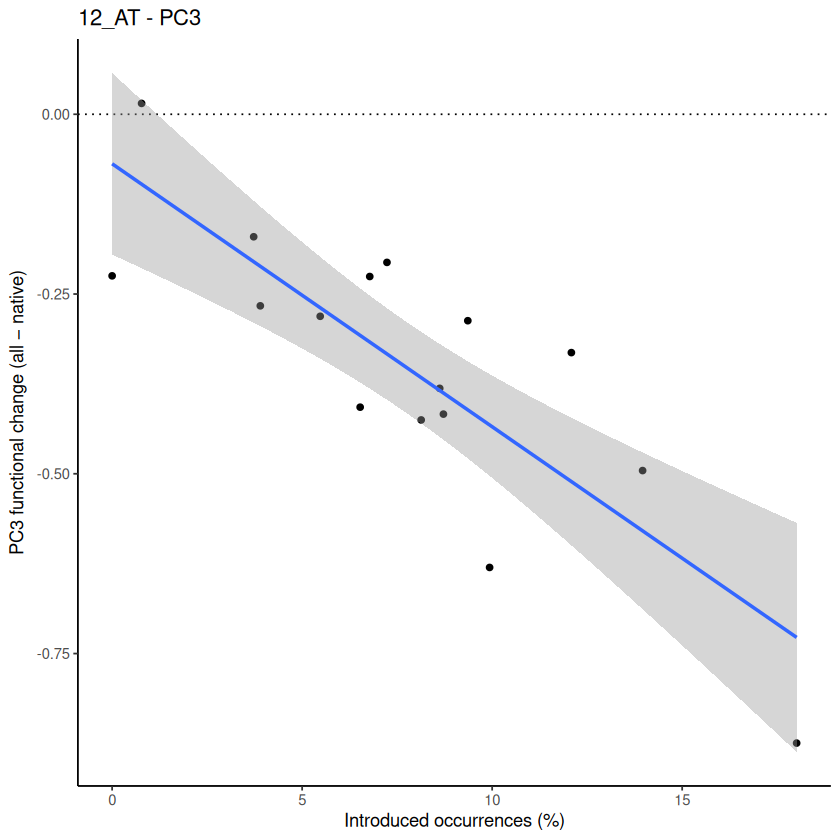

`geom_smooth()` using formula = 'y ~ x'


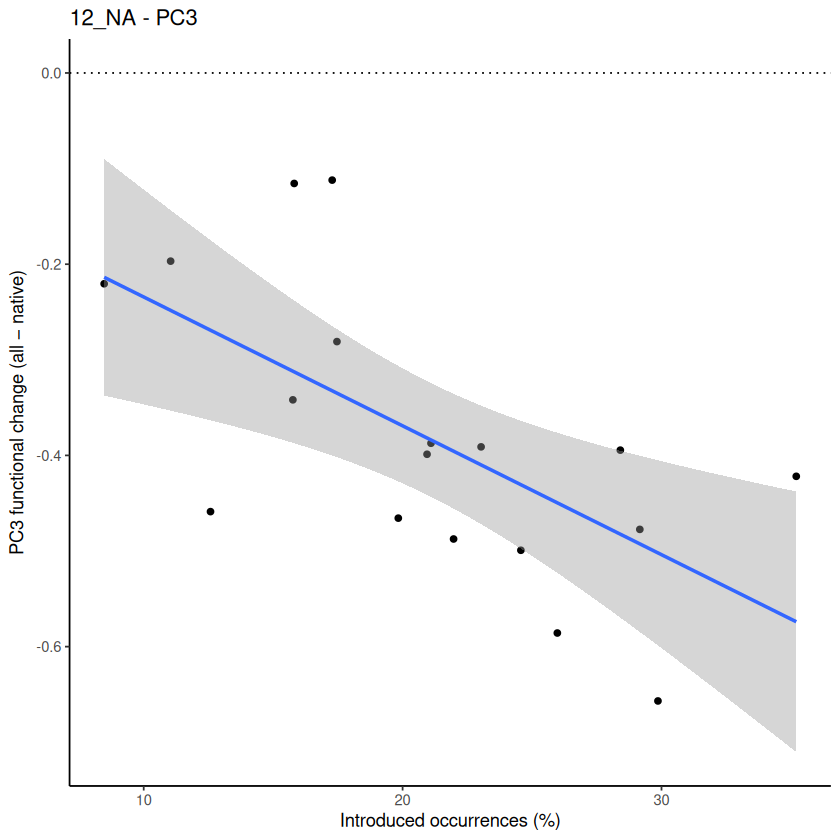

`geom_smooth()` using formula = 'y ~ x'


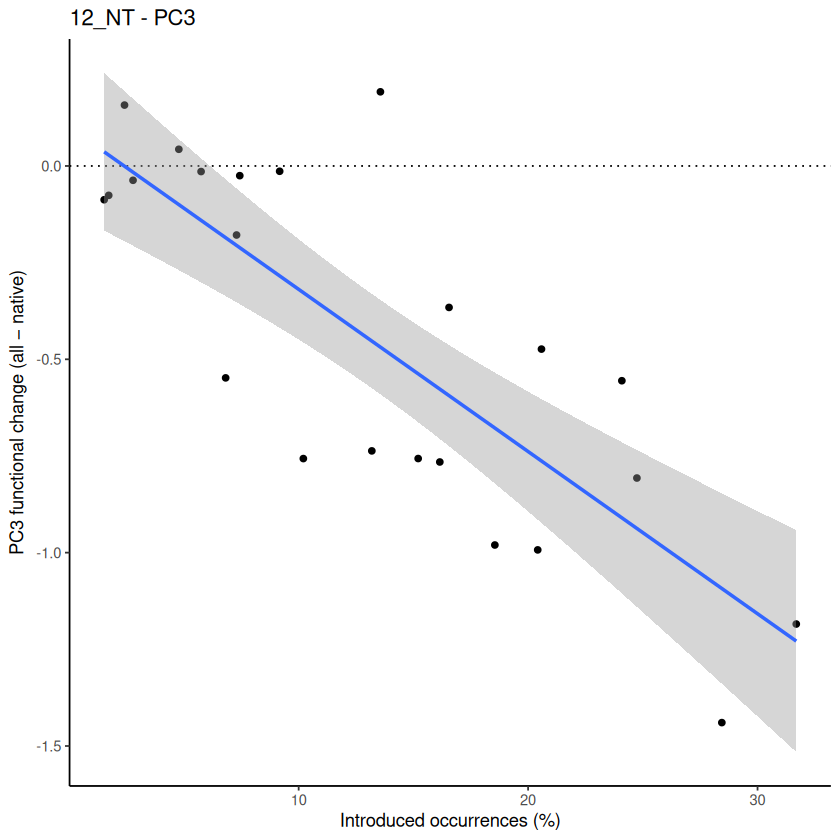

`geom_smooth()` using formula = 'y ~ x'


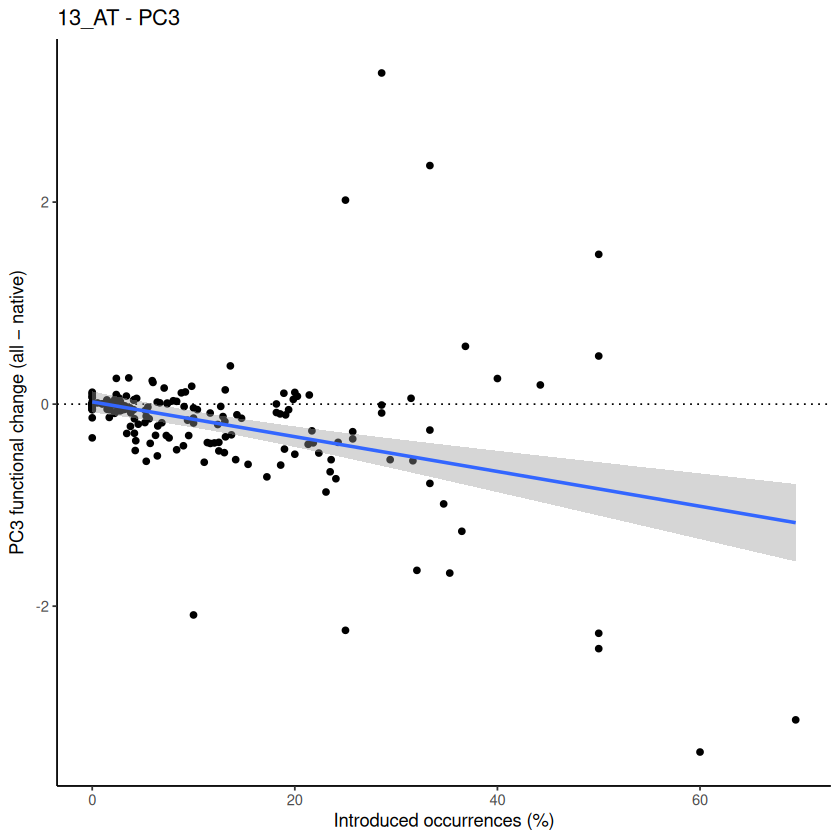

`geom_smooth()` using formula = 'y ~ x'


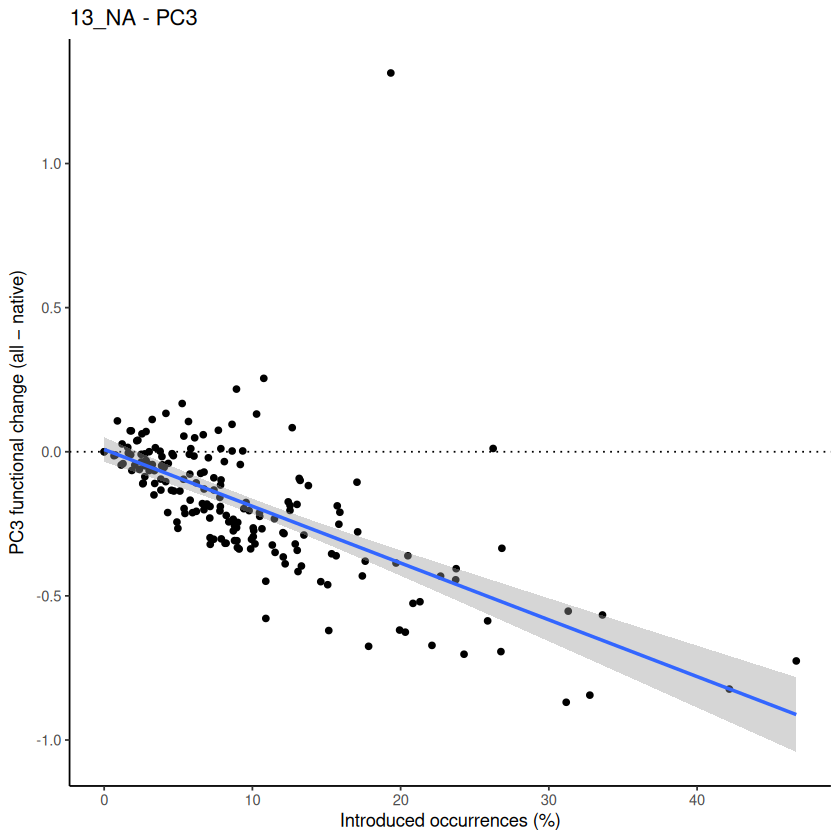

`geom_smooth()` using formula = 'y ~ x'


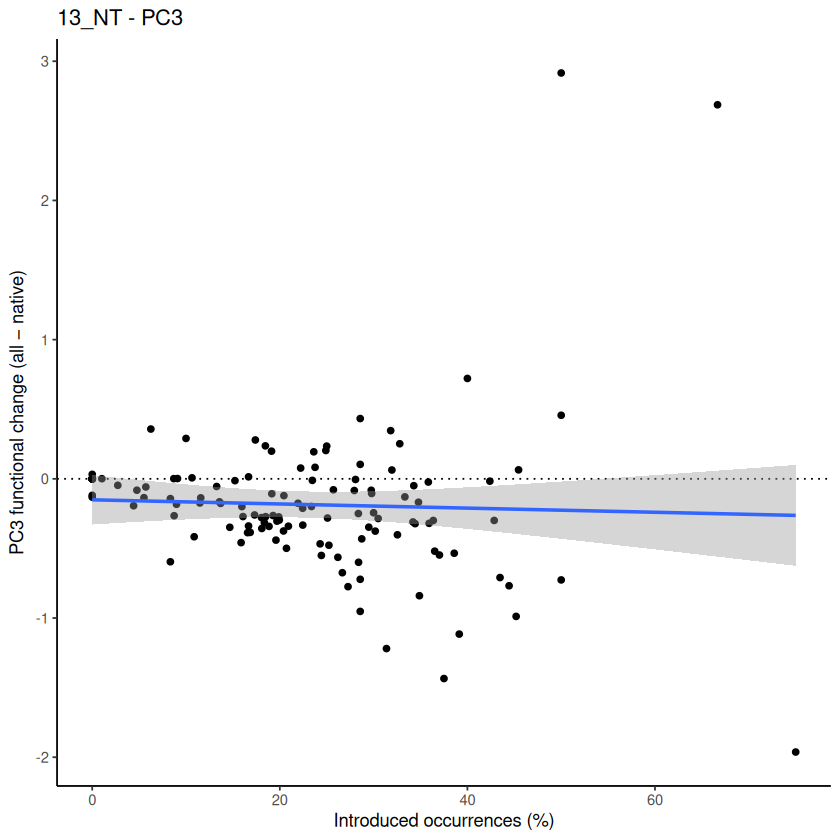

`geom_smooth()` using formula = 'y ~ x'


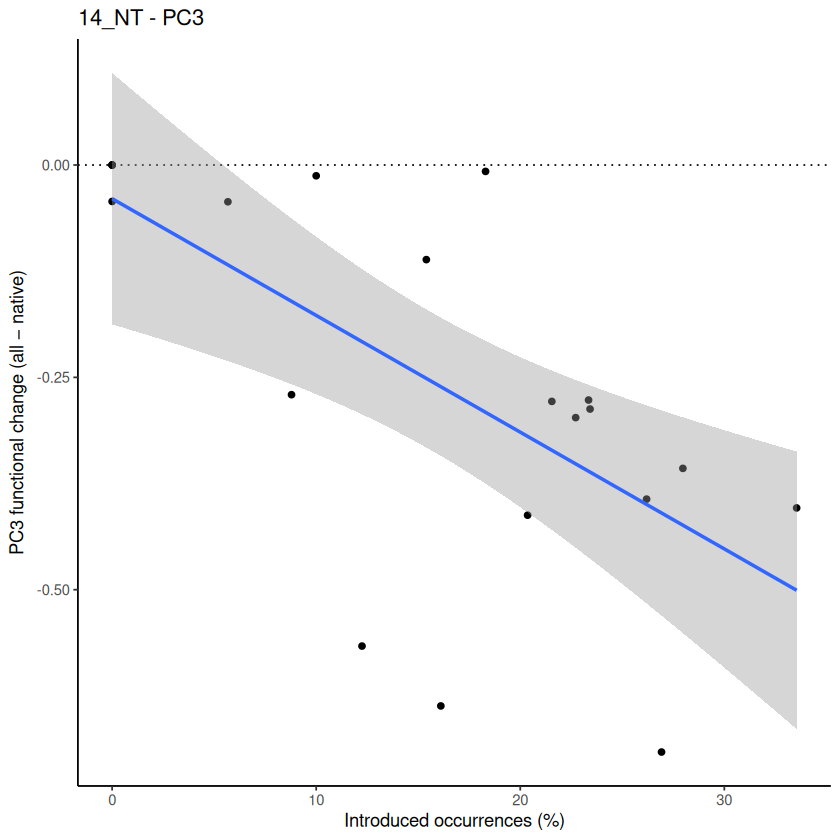

`geom_smooth()` using formula = 'y ~ x'


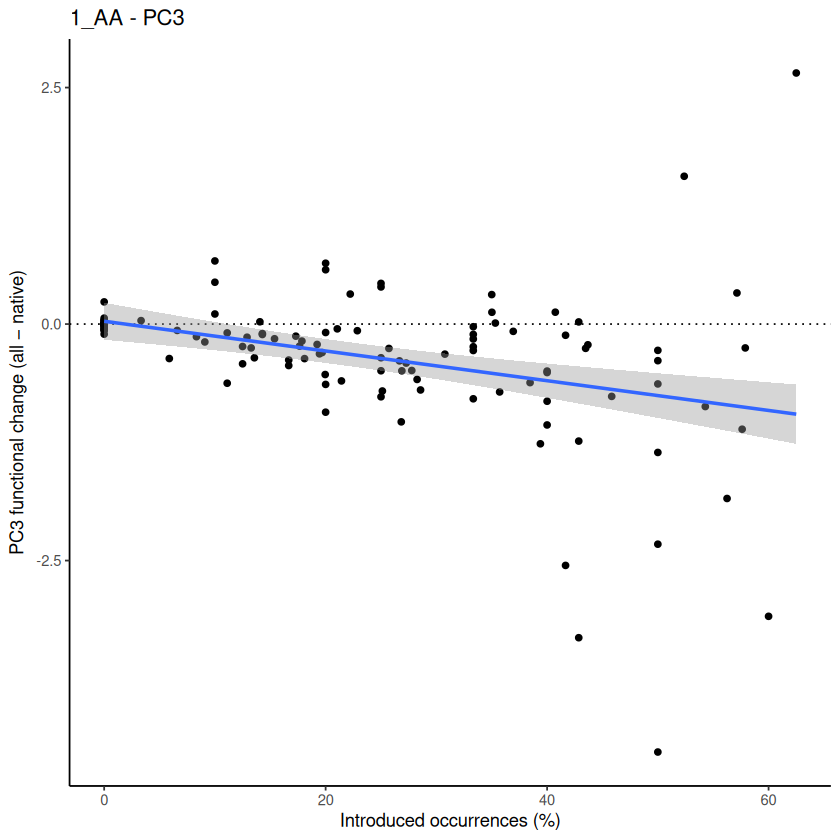

`geom_smooth()` using formula = 'y ~ x'


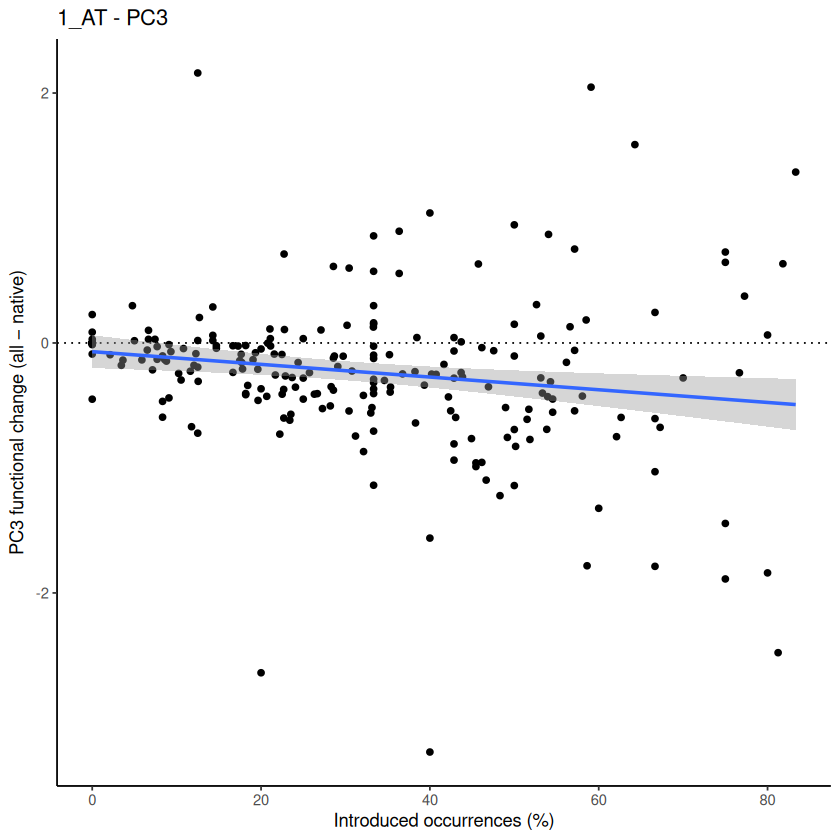

`geom_smooth()` using formula = 'y ~ x'


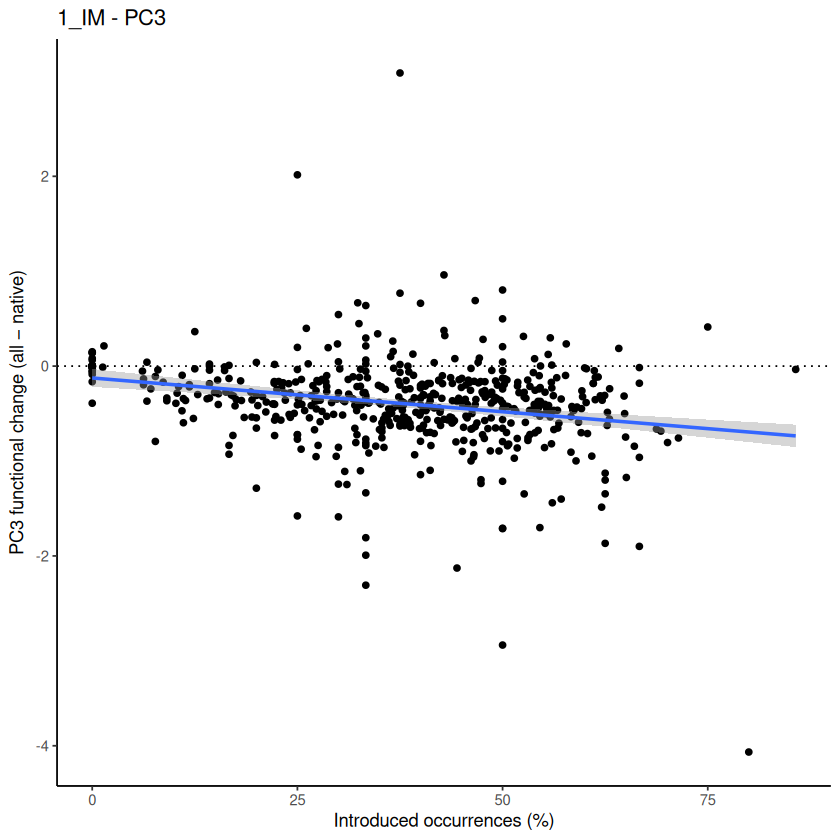

`geom_smooth()` using formula = 'y ~ x'


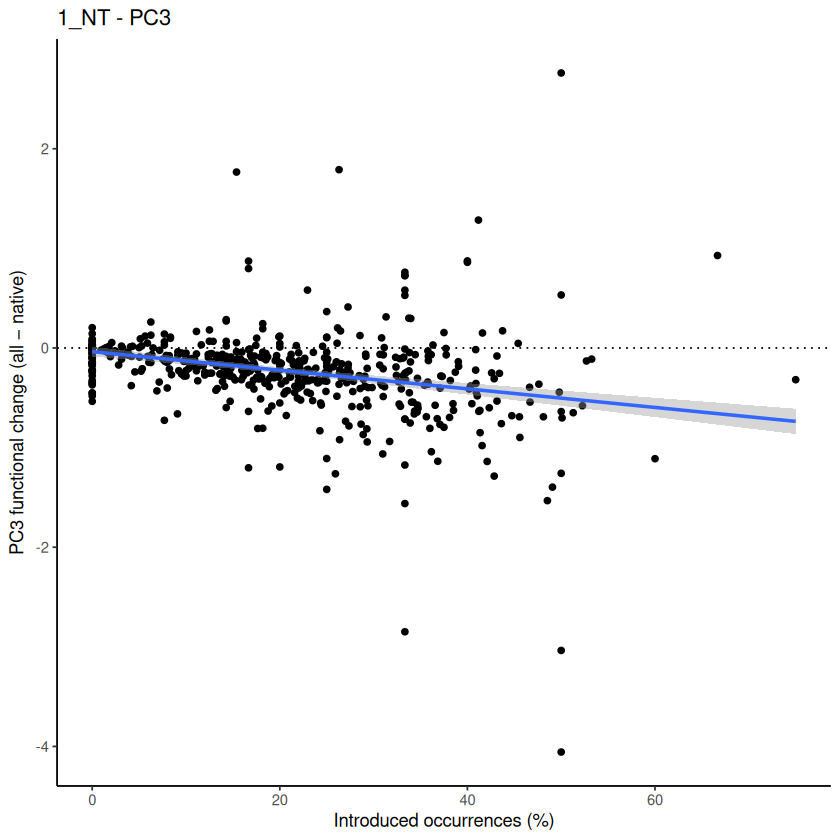

`geom_smooth()` using formula = 'y ~ x'


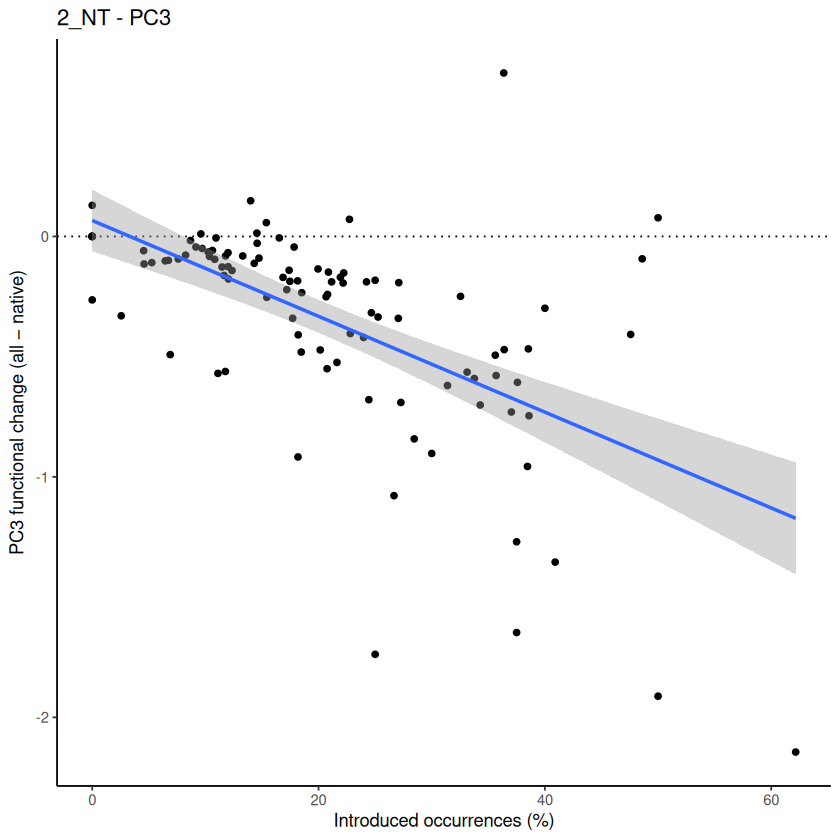

`geom_smooth()` using formula = 'y ~ x'


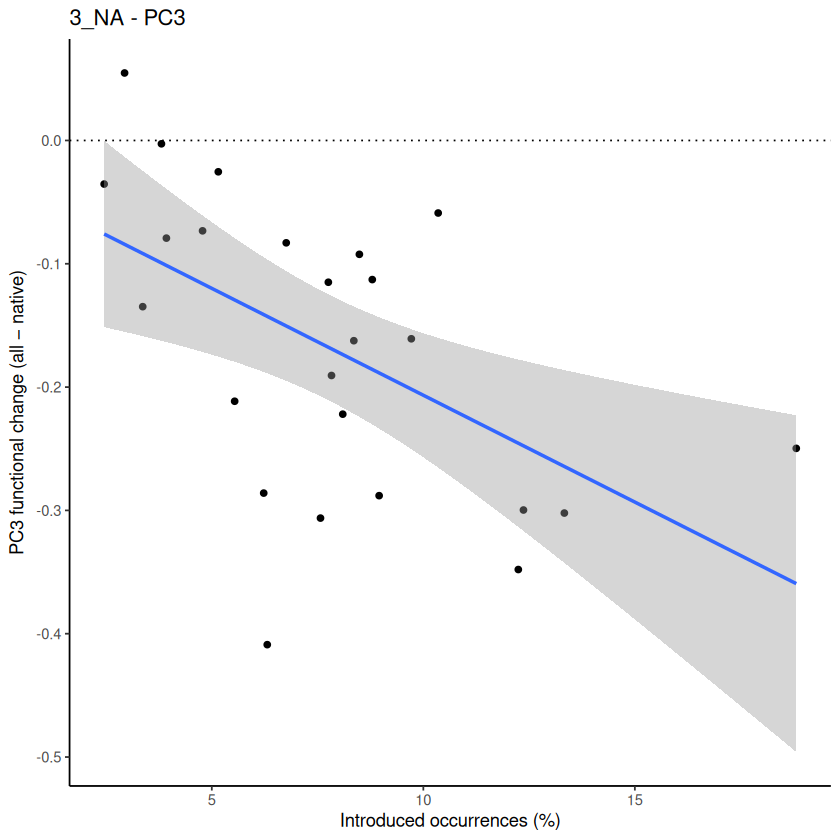

`geom_smooth()` using formula = 'y ~ x'


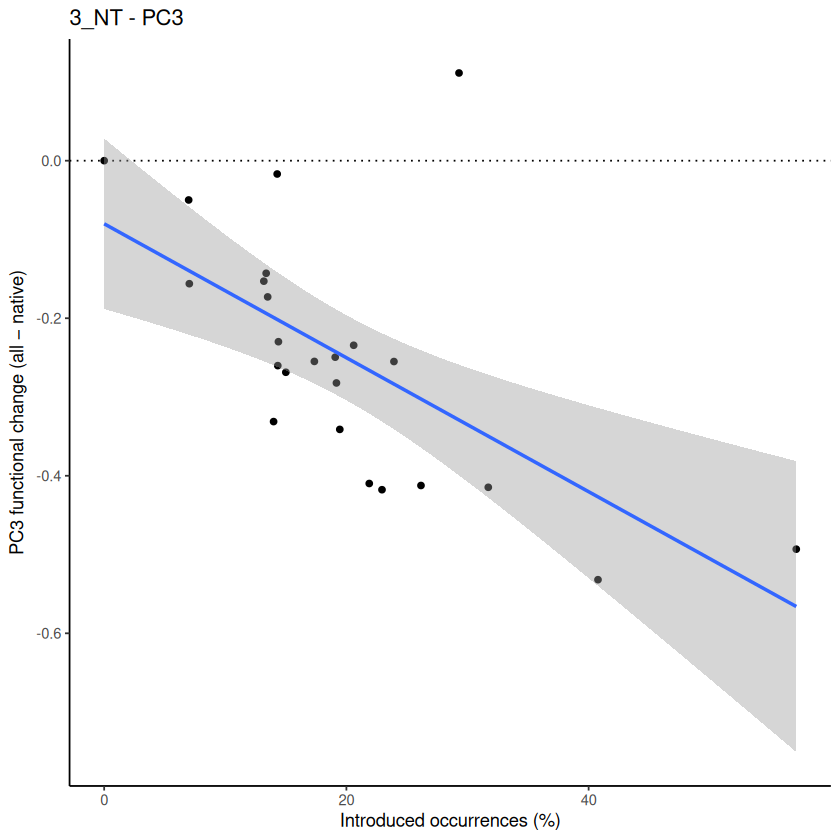

`geom_smooth()` using formula = 'y ~ x'


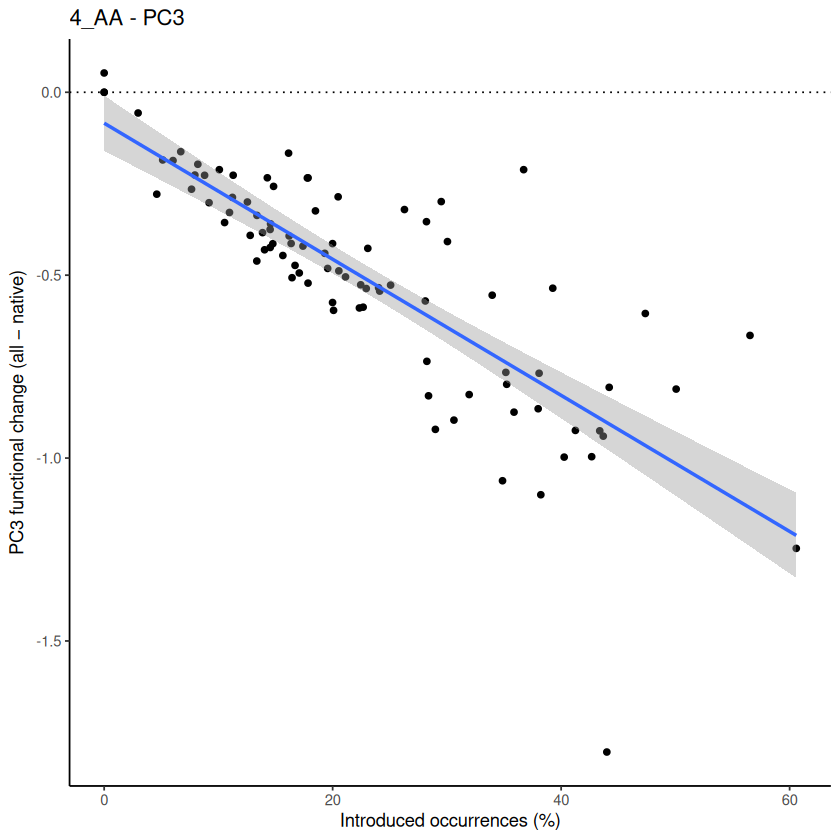

`geom_smooth()` using formula = 'y ~ x'


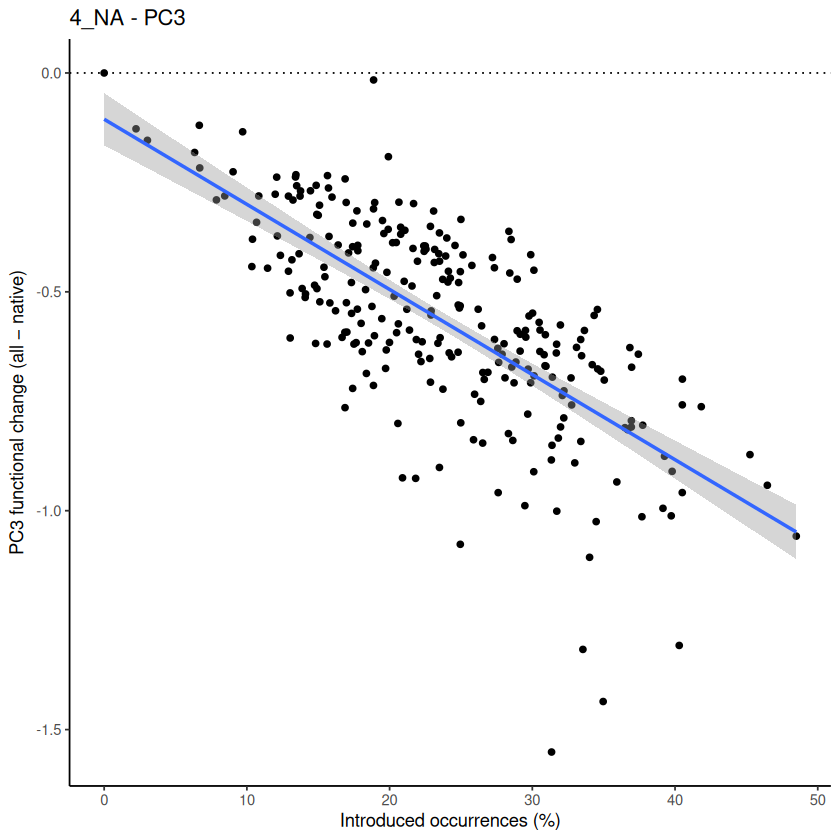

`geom_smooth()` using formula = 'y ~ x'


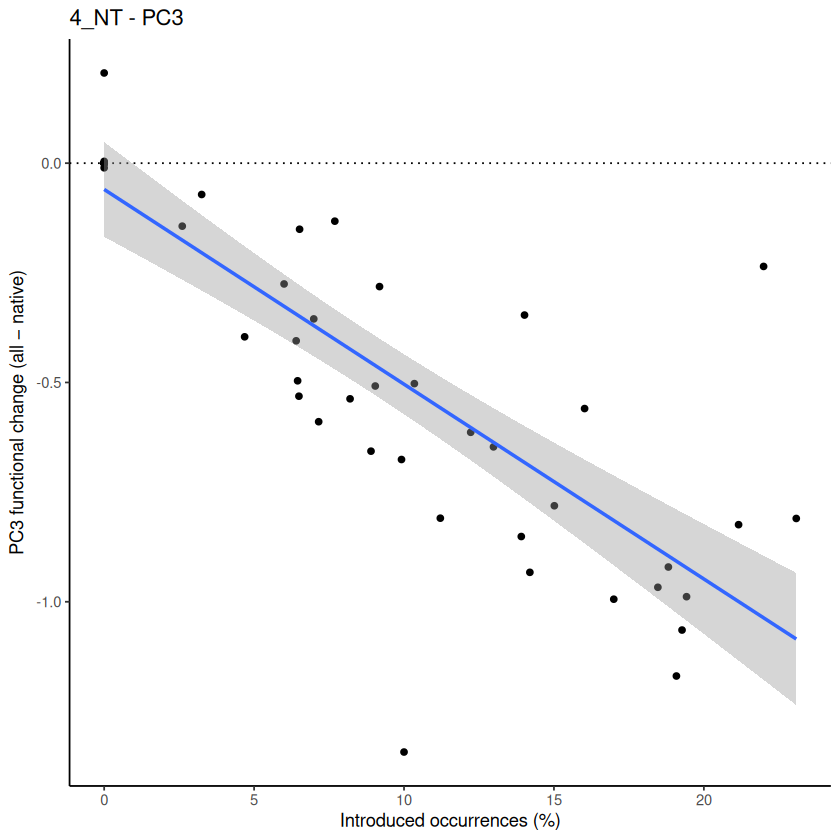

`geom_smooth()` using formula = 'y ~ x'


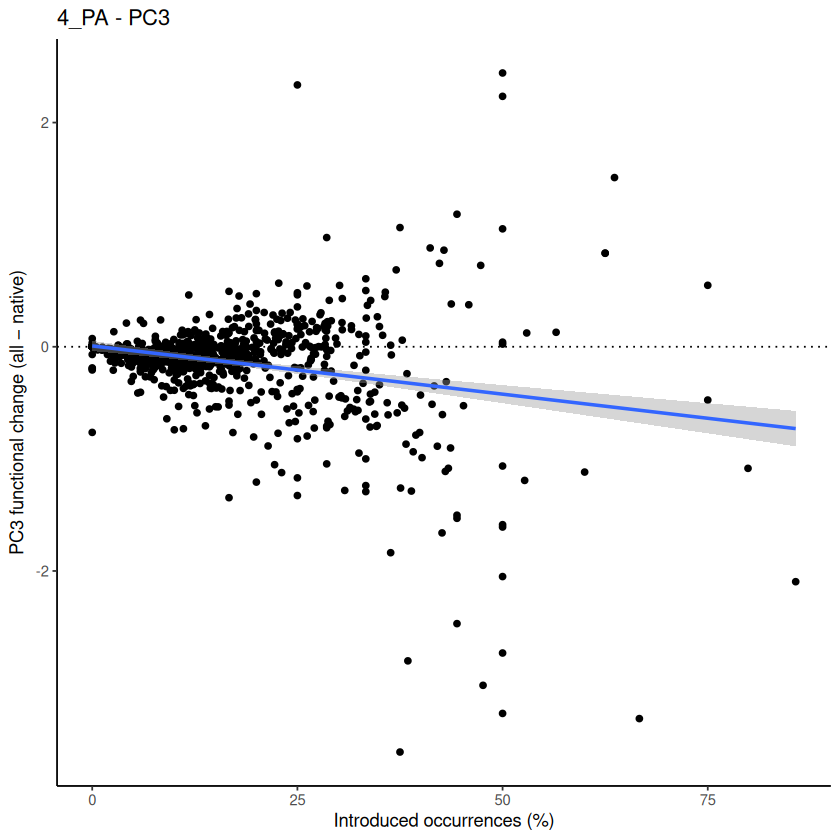

`geom_smooth()` using formula = 'y ~ x'


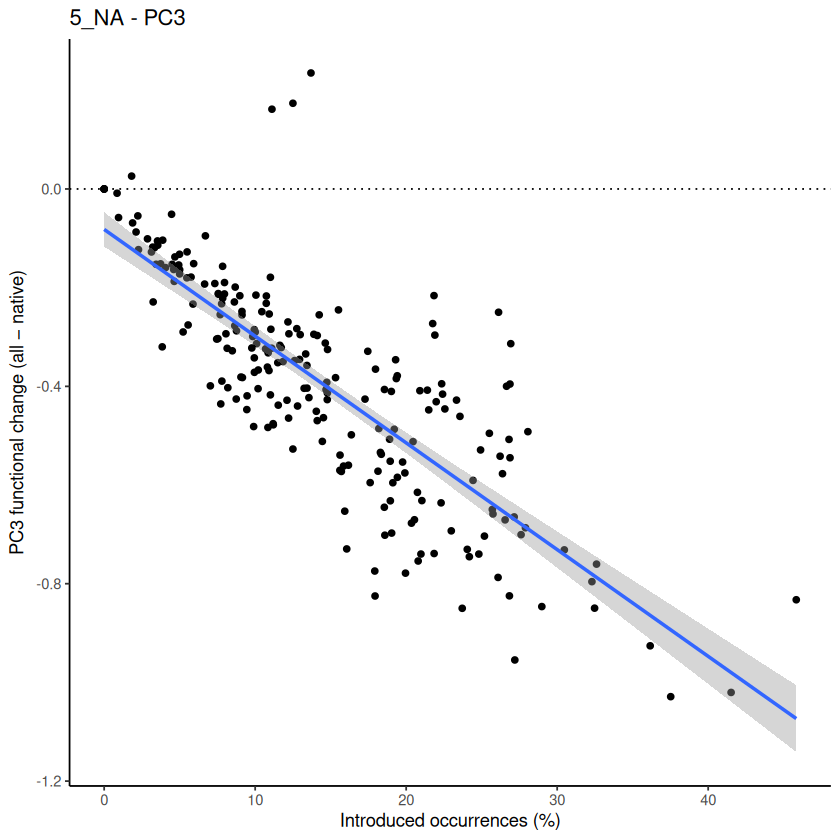

`geom_smooth()` using formula = 'y ~ x'


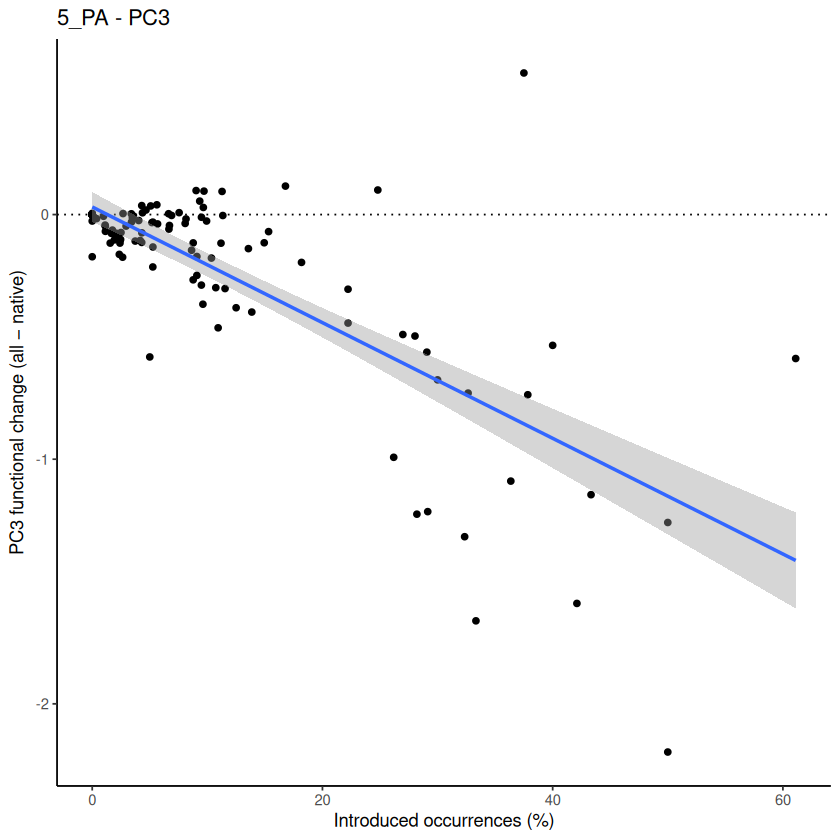

`geom_smooth()` using formula = 'y ~ x'


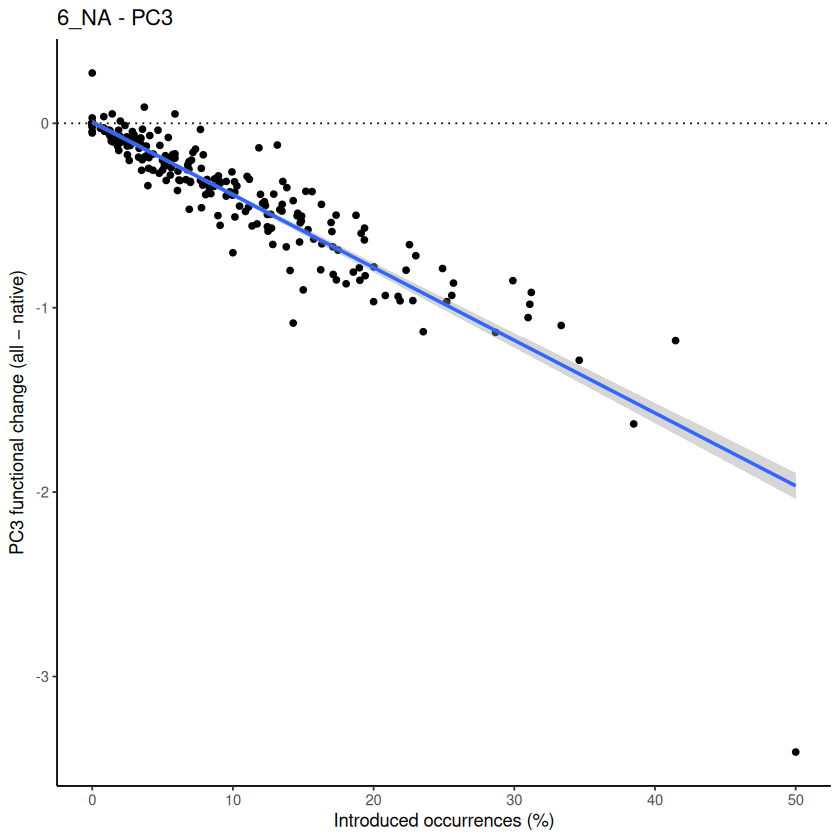

`geom_smooth()` using formula = 'y ~ x'


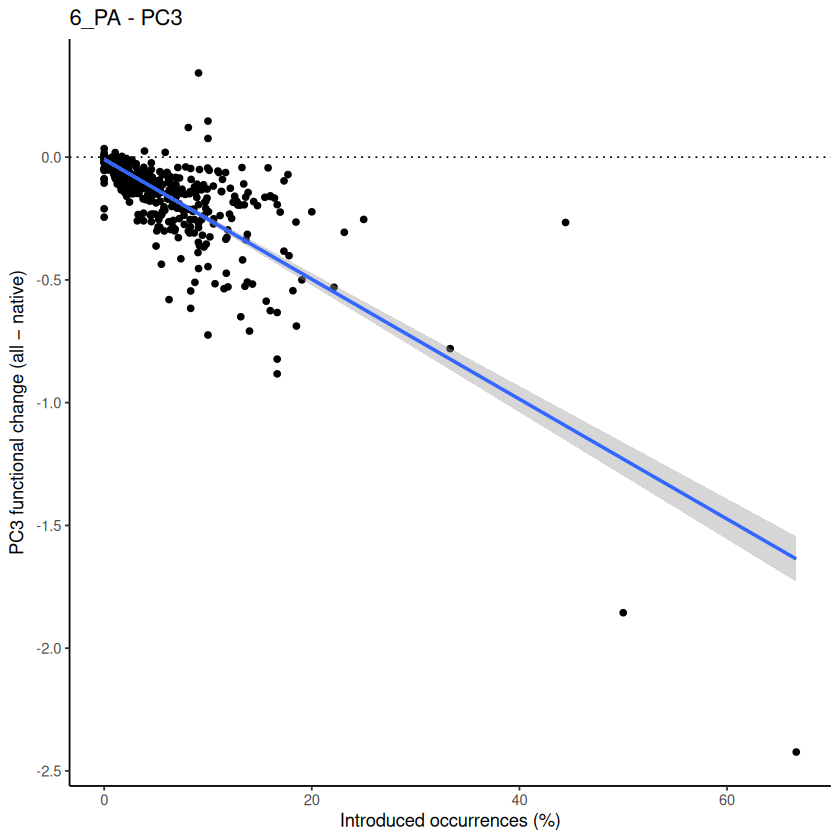

`geom_smooth()` using formula = 'y ~ x'


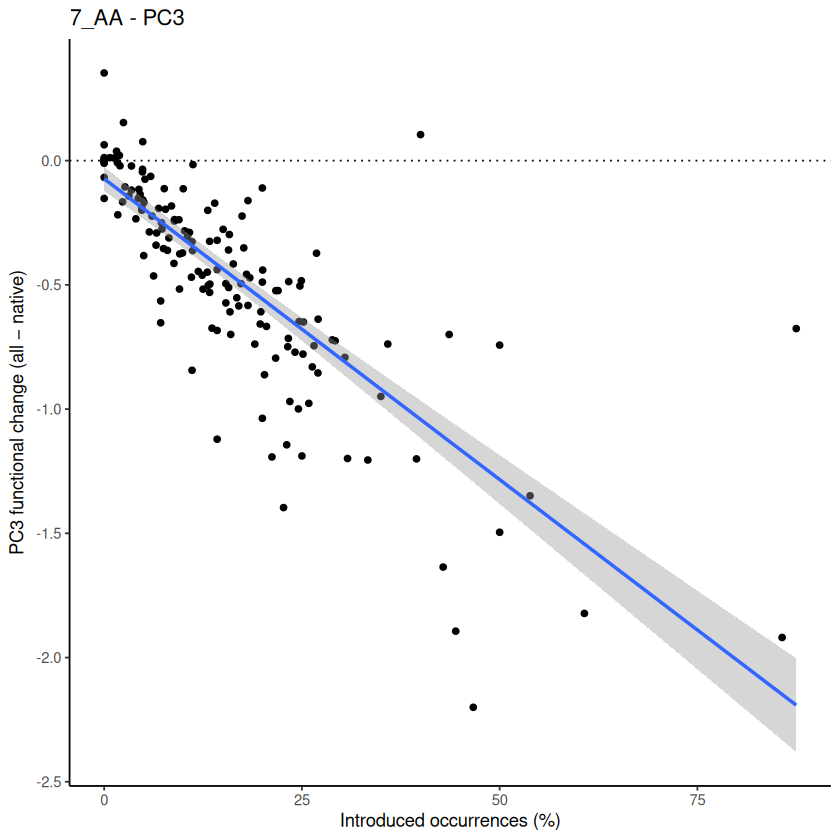

`geom_smooth()` using formula = 'y ~ x'


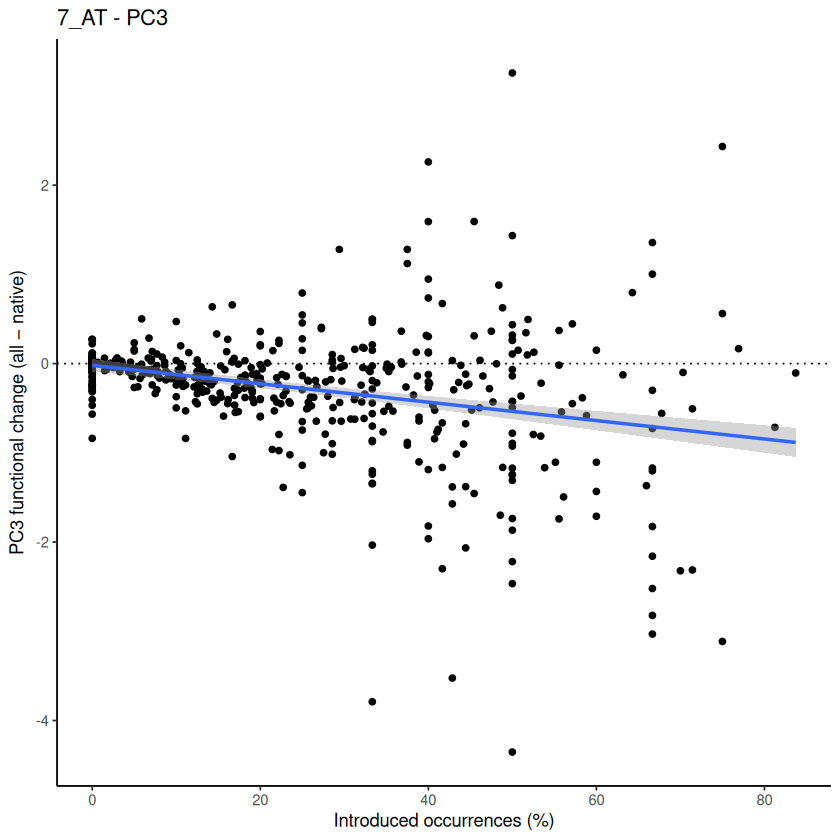

`geom_smooth()` using formula = 'y ~ x'


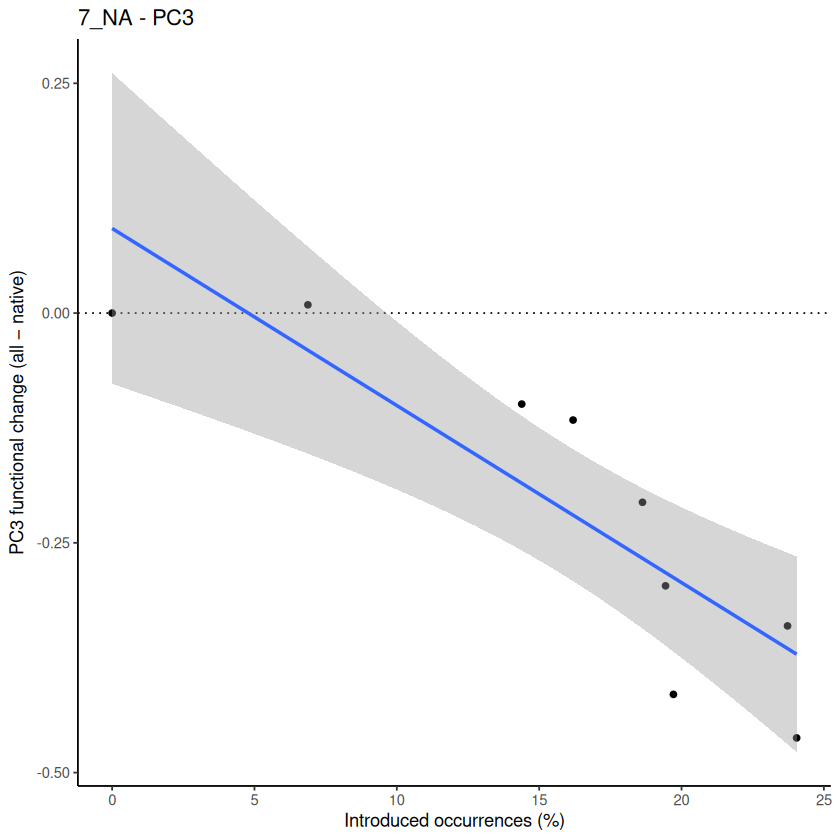

`geom_smooth()` using formula = 'y ~ x'


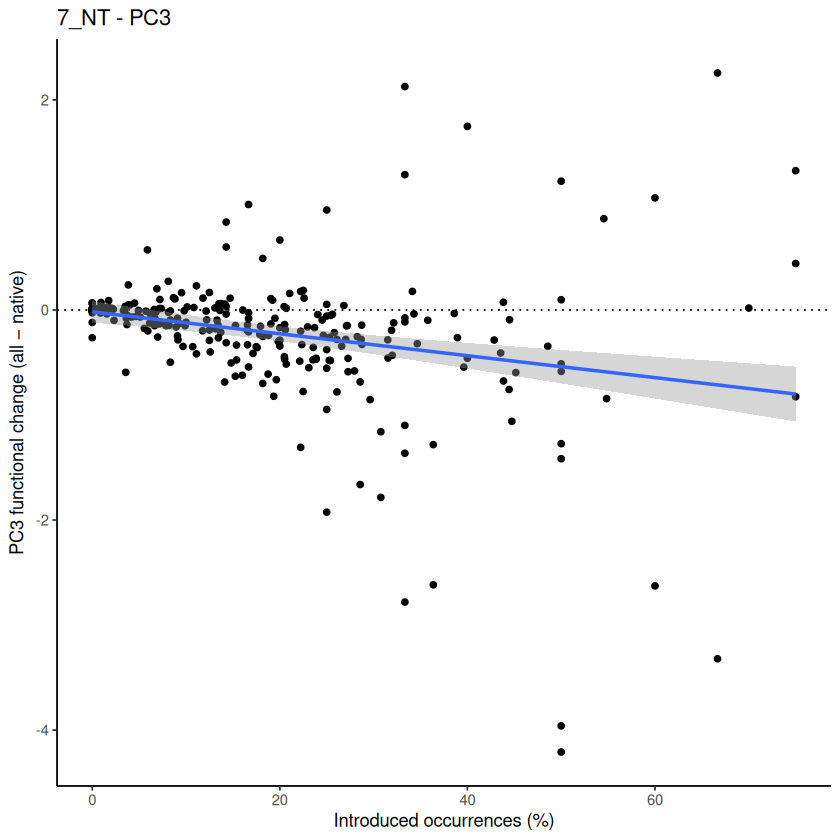

`geom_smooth()` using formula = 'y ~ x'


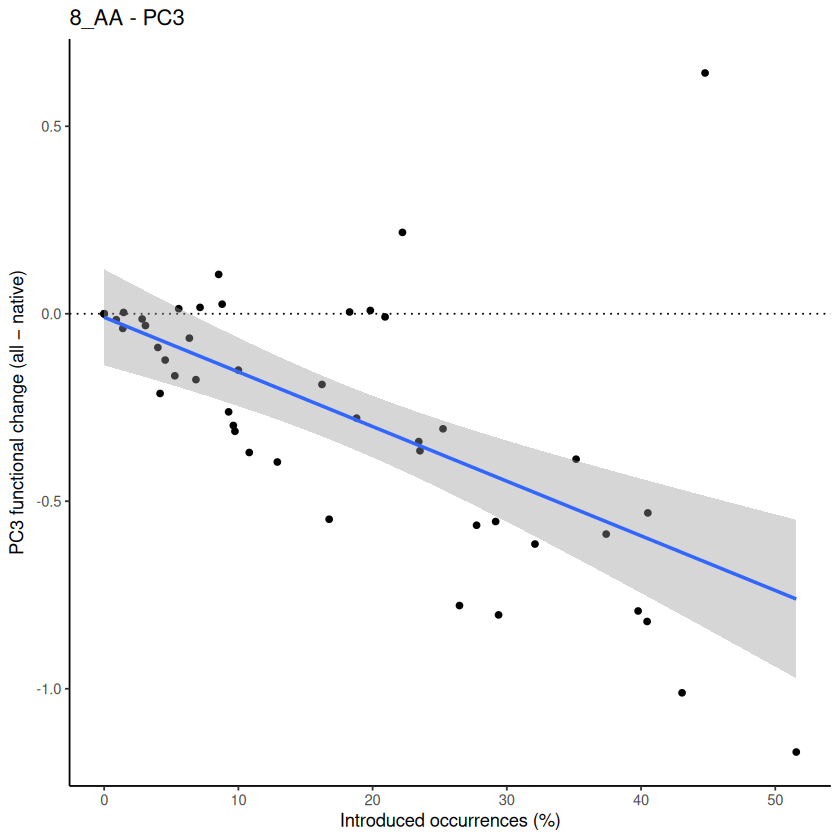

`geom_smooth()` using formula = 'y ~ x'


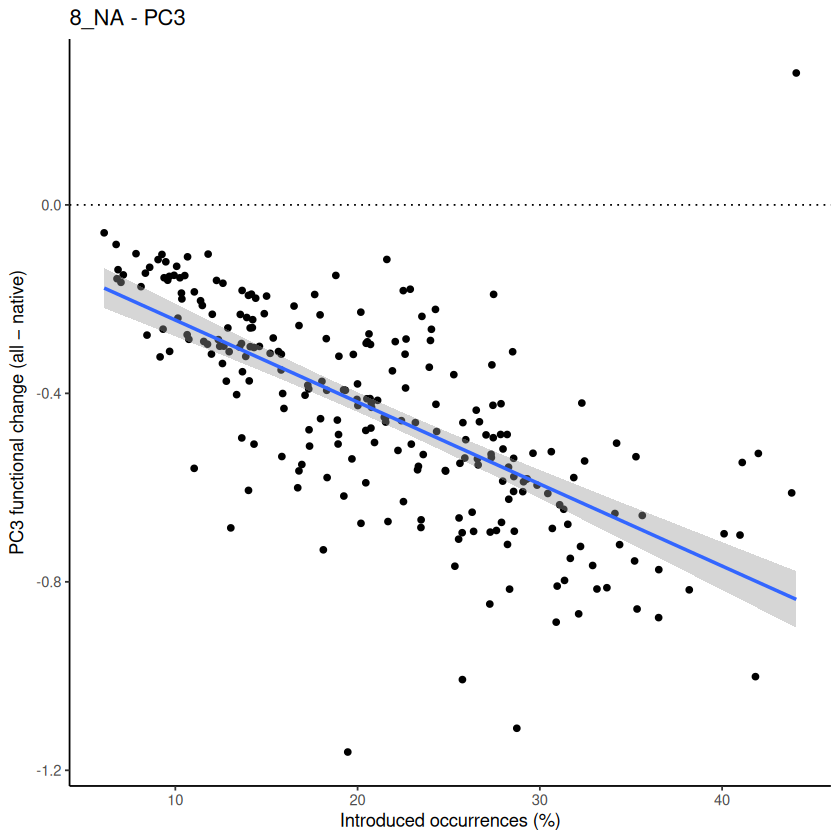

`geom_smooth()` using formula = 'y ~ x'


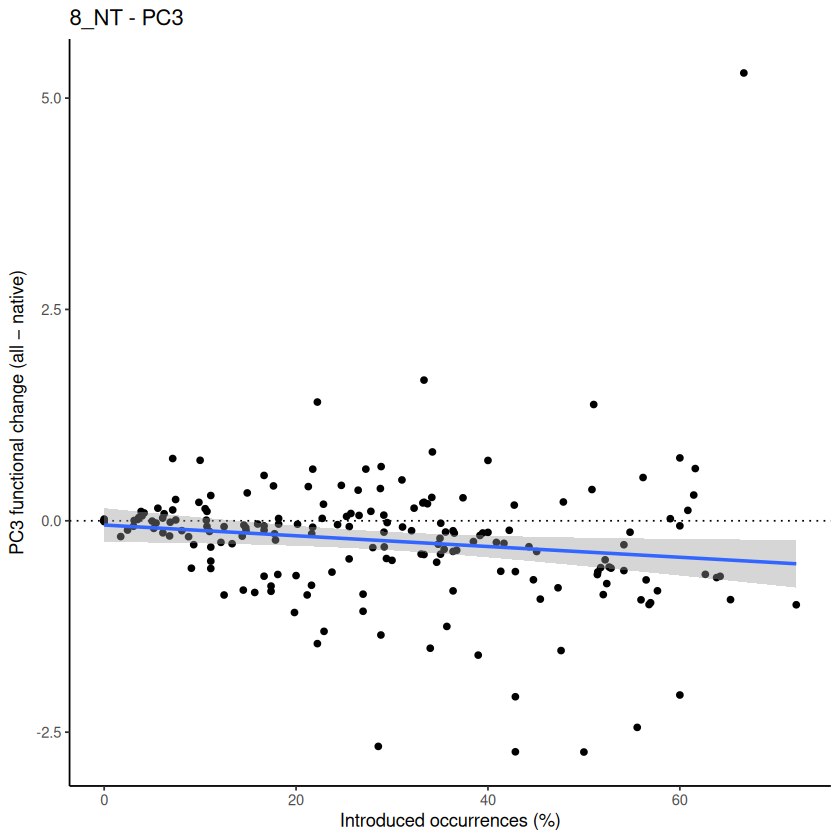

`geom_smooth()` using formula = 'y ~ x'


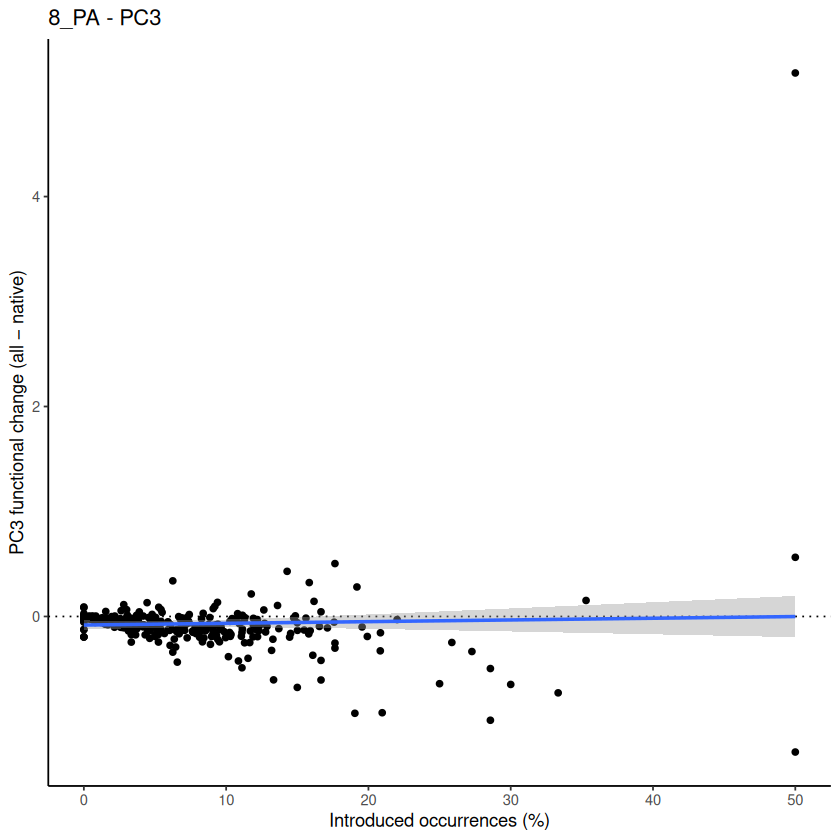

`geom_smooth()` using formula = 'y ~ x'


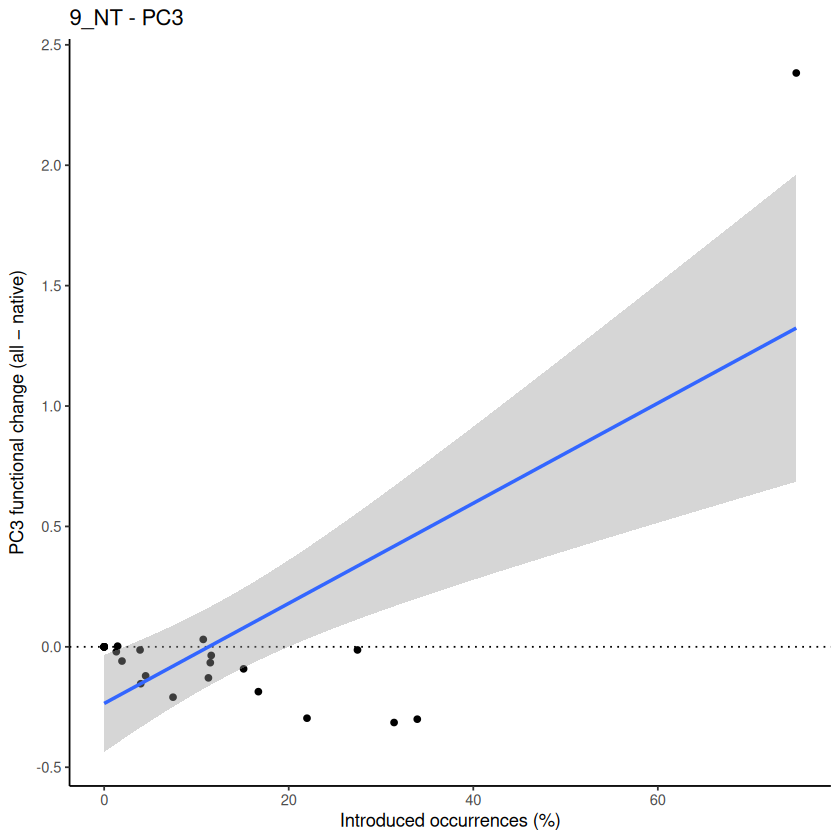

`geom_smooth()` using formula = 'y ~ x'


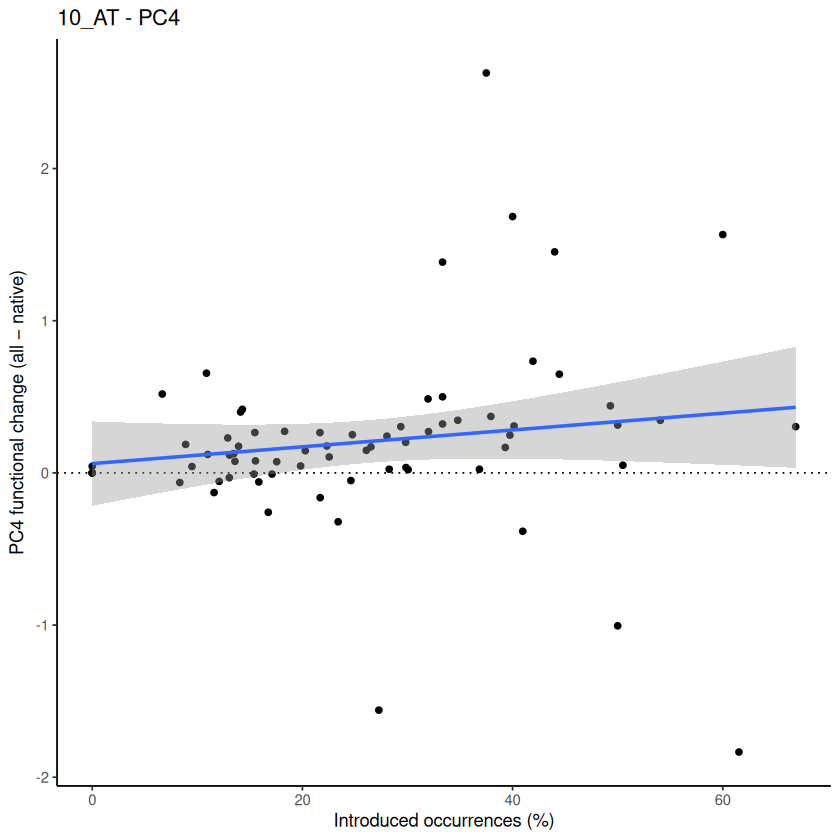

`geom_smooth()` using formula = 'y ~ x'


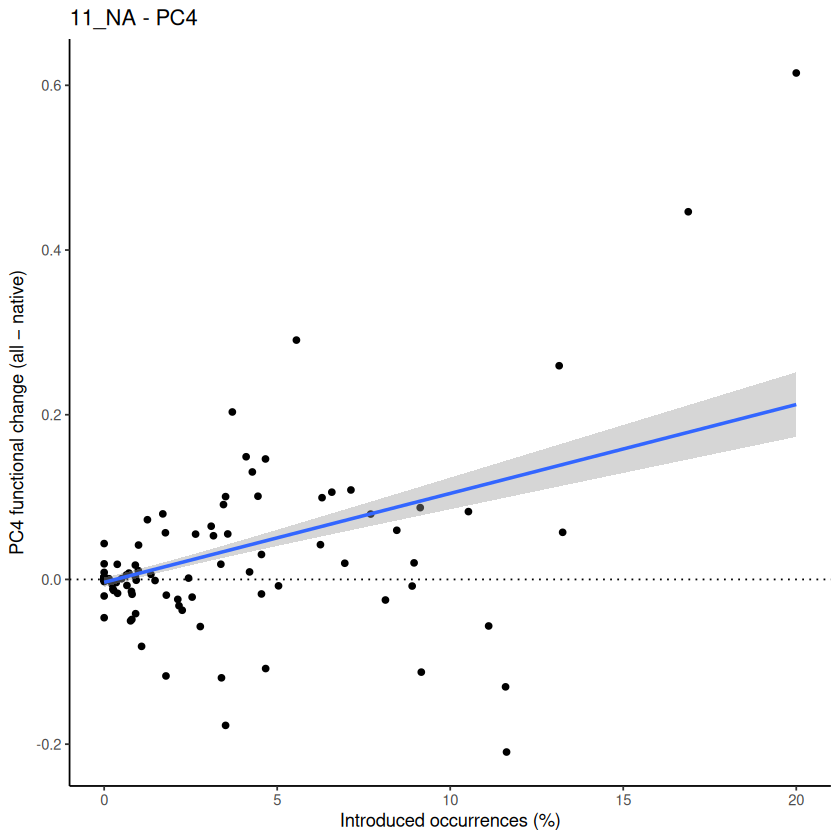

`geom_smooth()` using formula = 'y ~ x'


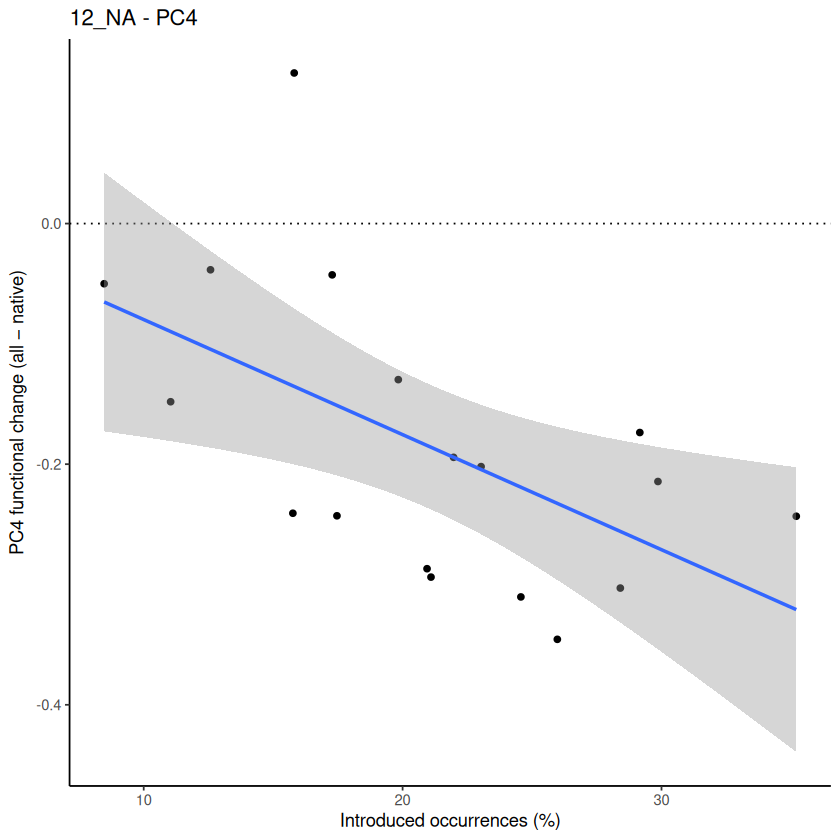

`geom_smooth()` using formula = 'y ~ x'


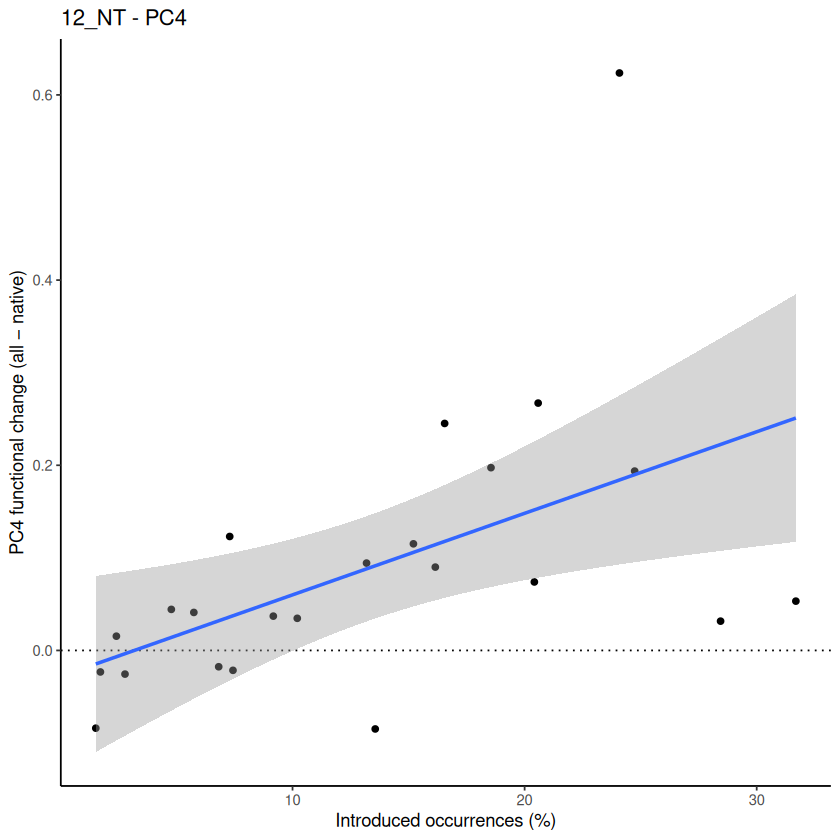

`geom_smooth()` using formula = 'y ~ x'


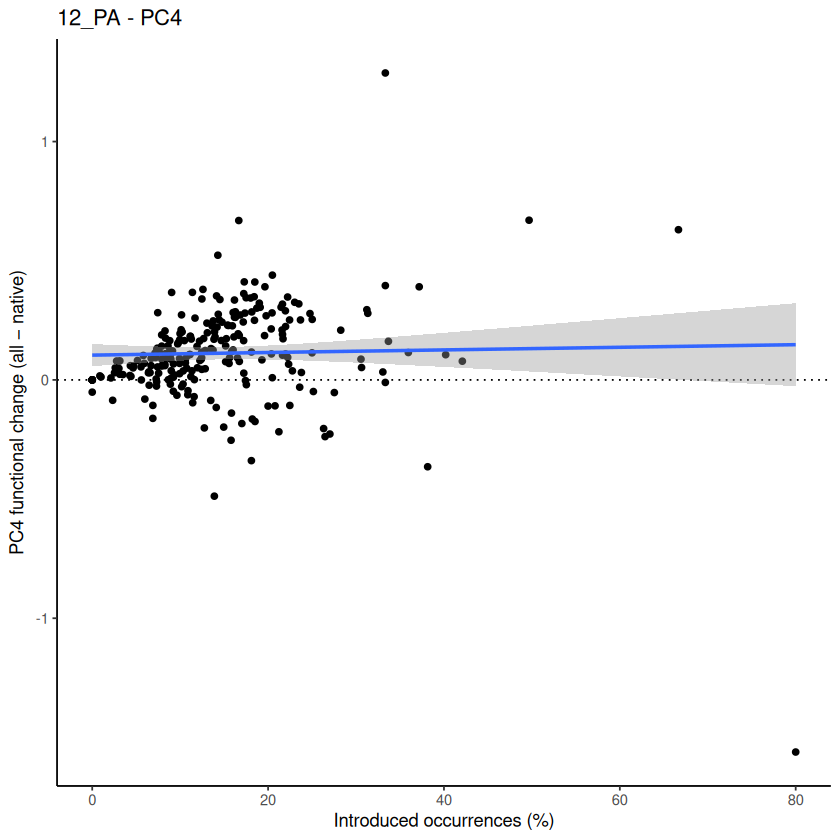

`geom_smooth()` using formula = 'y ~ x'


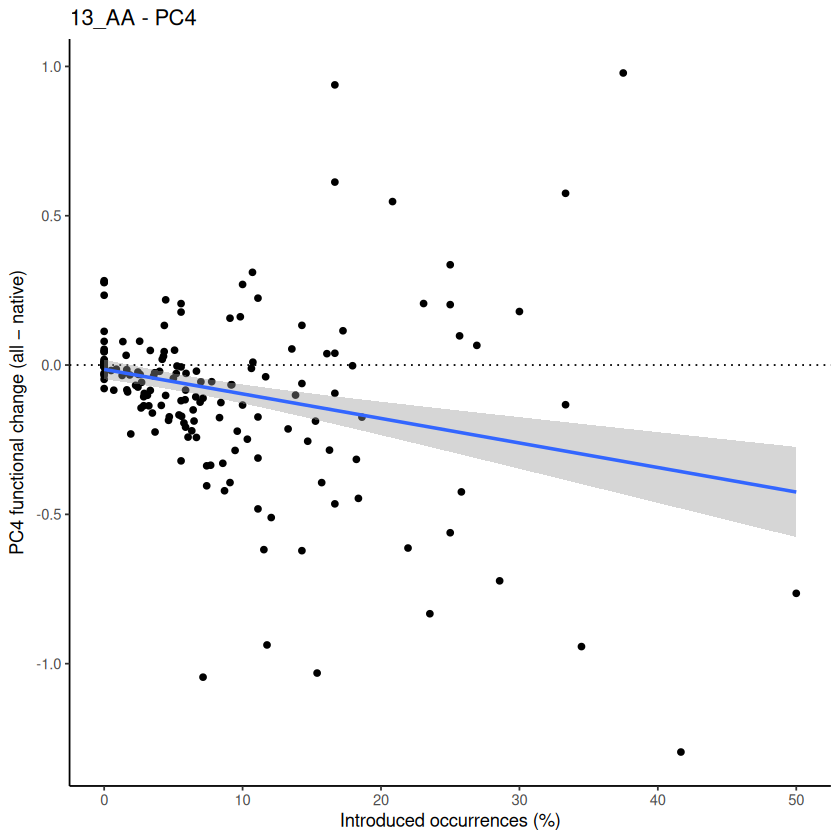

`geom_smooth()` using formula = 'y ~ x'


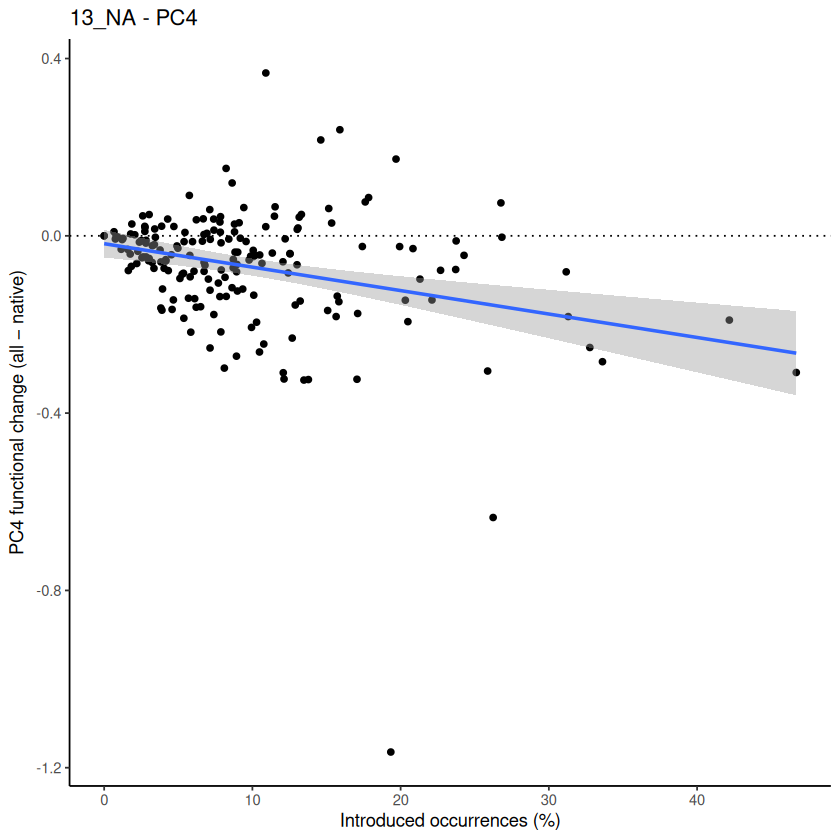

`geom_smooth()` using formula = 'y ~ x'


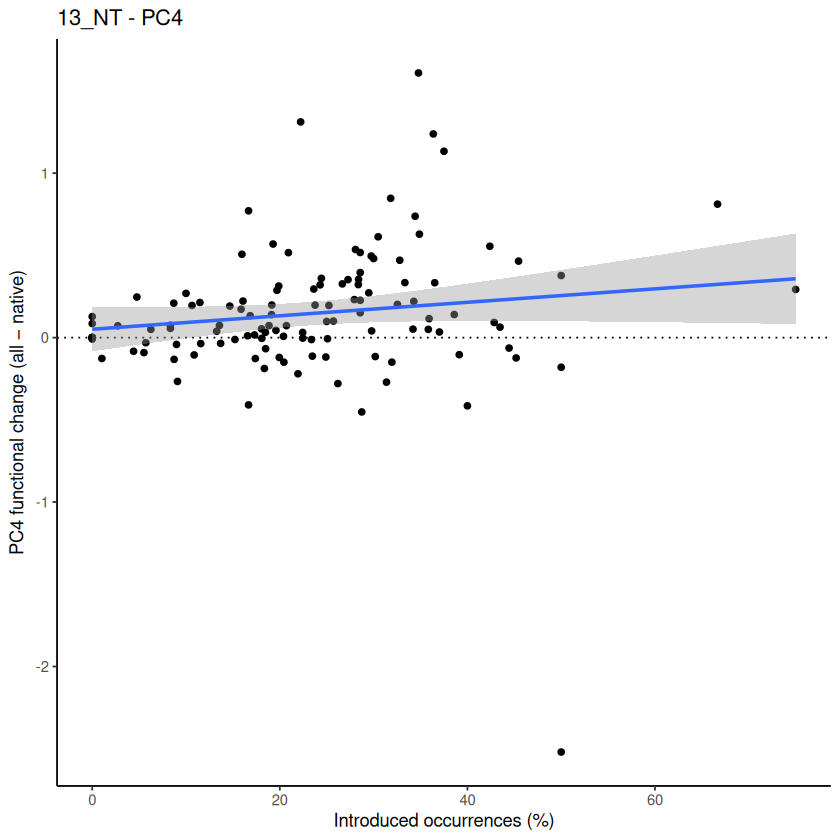

`geom_smooth()` using formula = 'y ~ x'


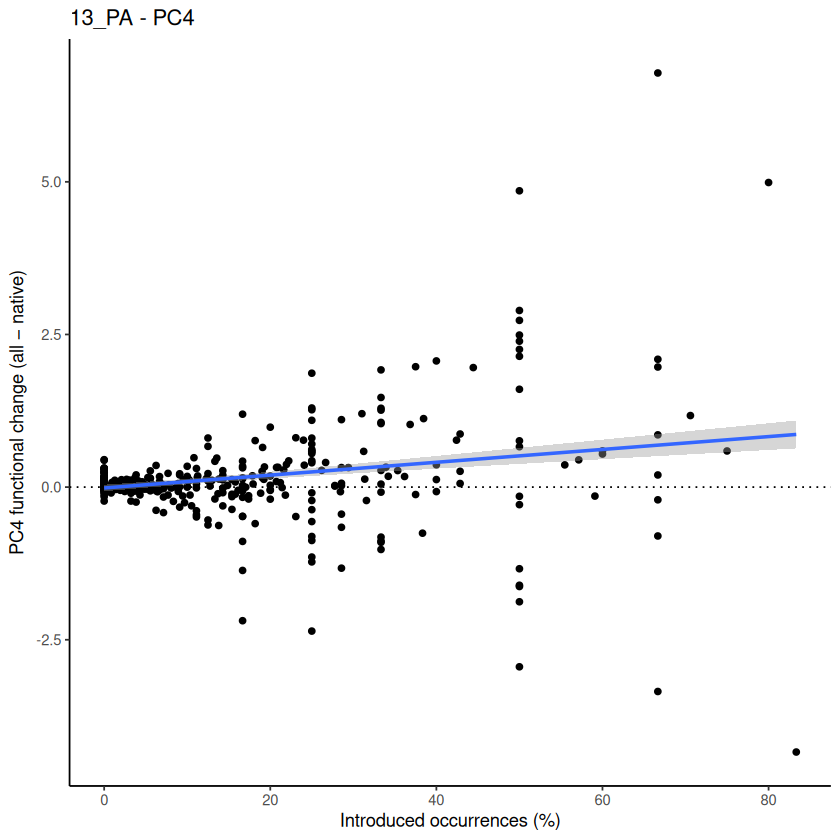

`geom_smooth()` using formula = 'y ~ x'


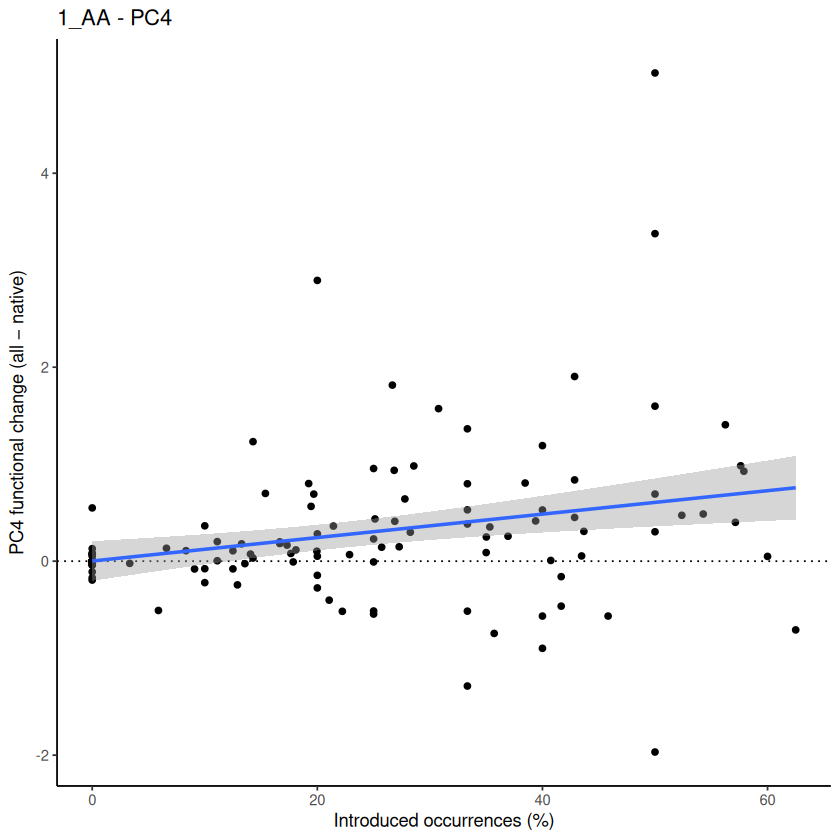

`geom_smooth()` using formula = 'y ~ x'


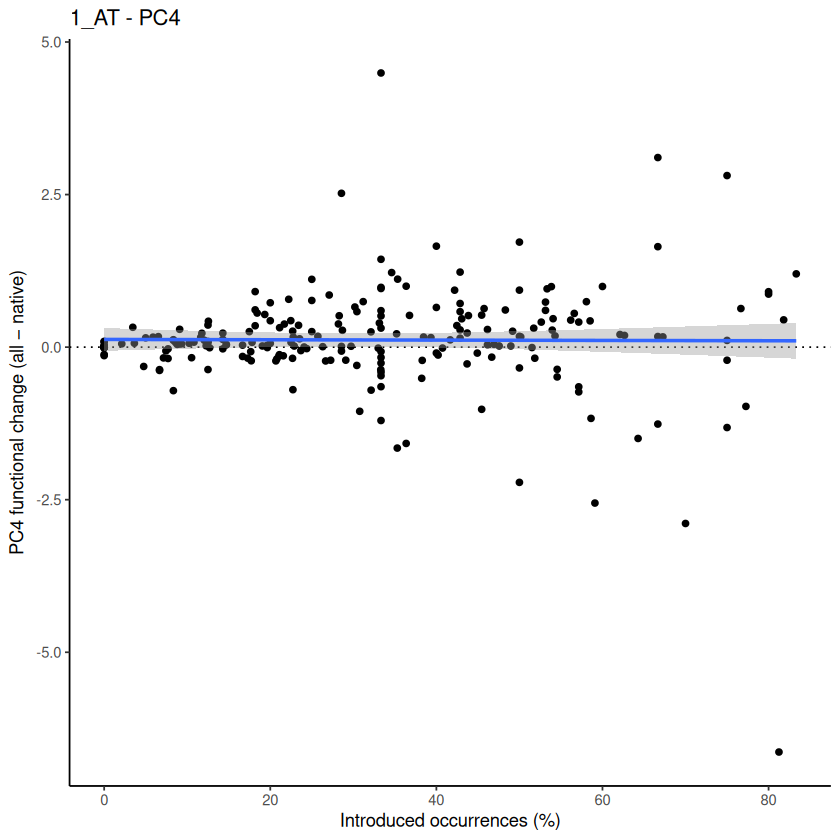

`geom_smooth()` using formula = 'y ~ x'


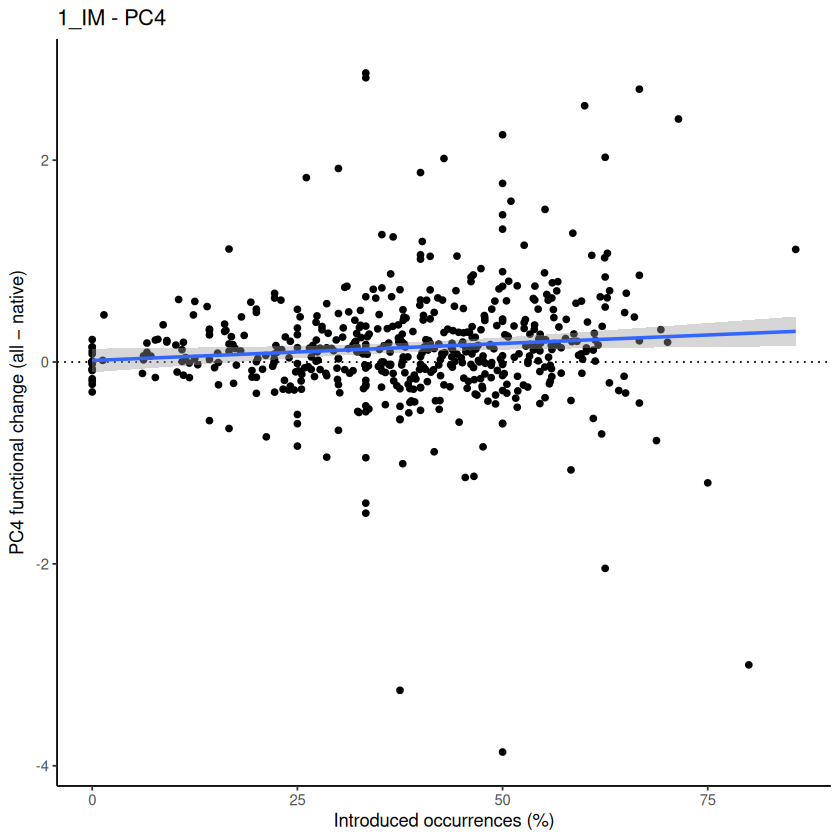

`geom_smooth()` using formula = 'y ~ x'


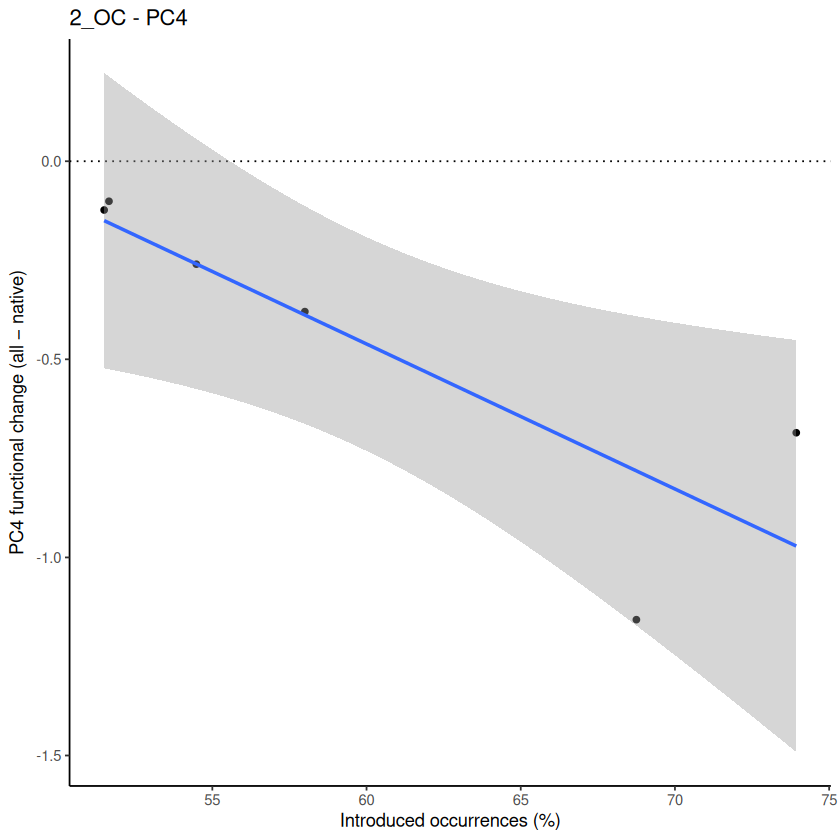

`geom_smooth()` using formula = 'y ~ x'


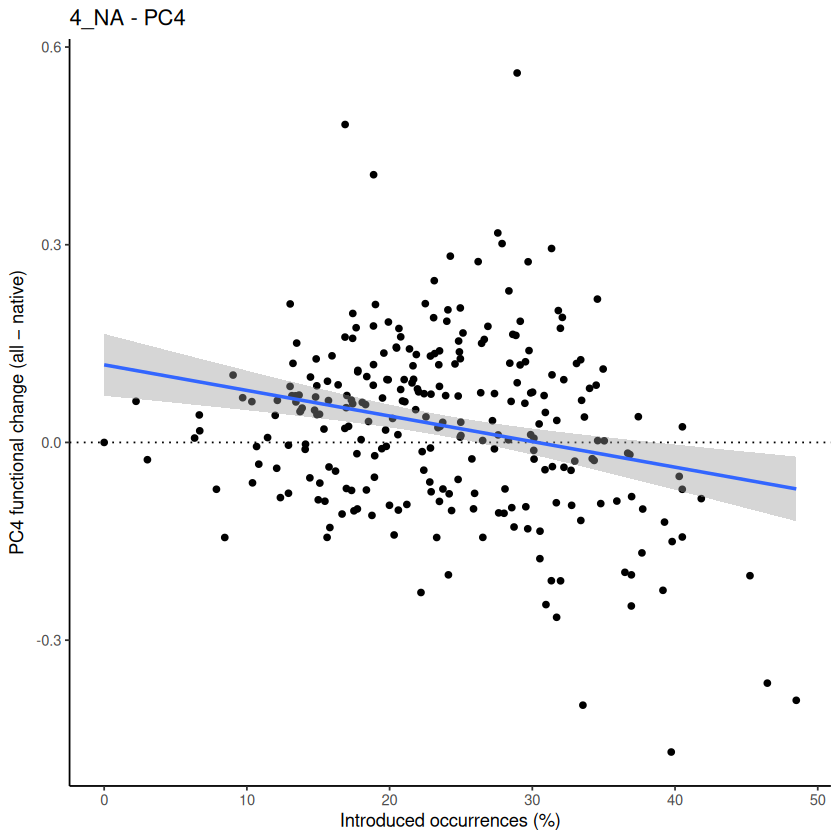

`geom_smooth()` using formula = 'y ~ x'


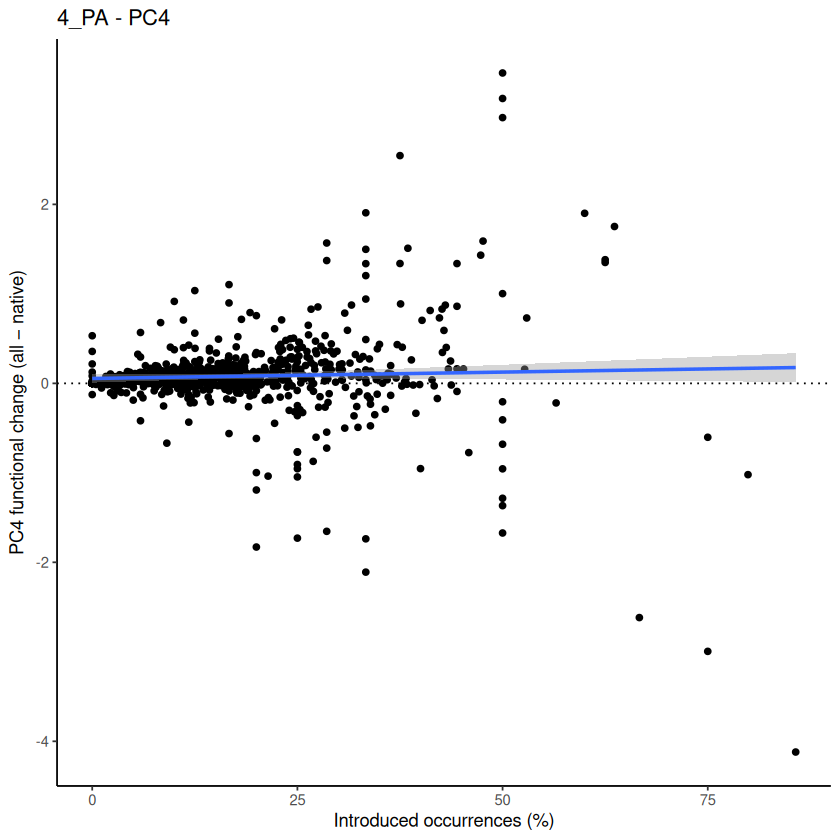

`geom_smooth()` using formula = 'y ~ x'


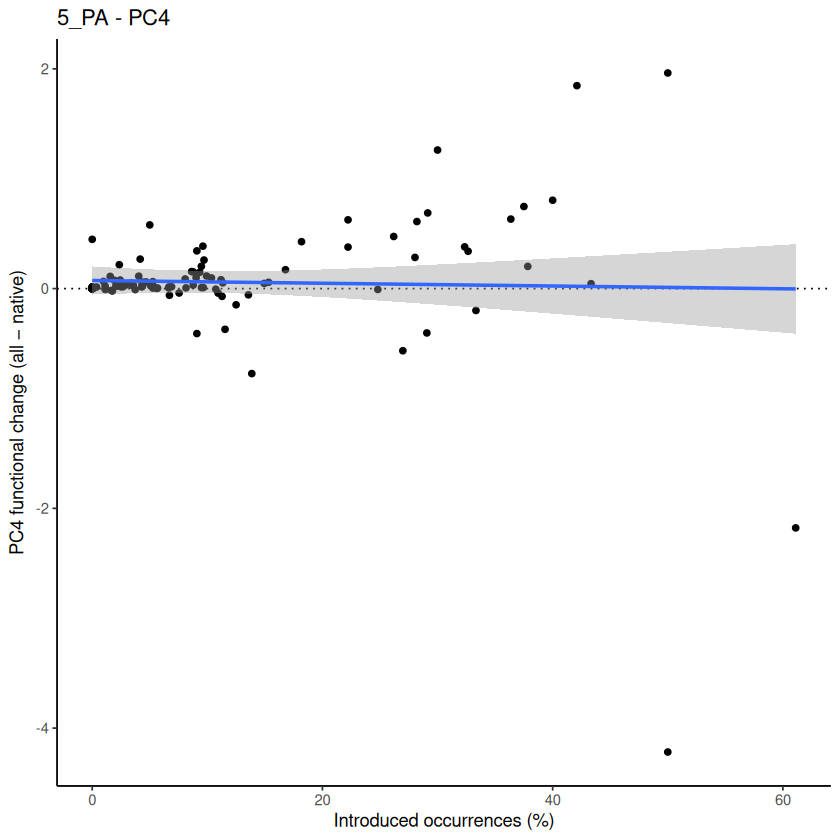

`geom_smooth()` using formula = 'y ~ x'


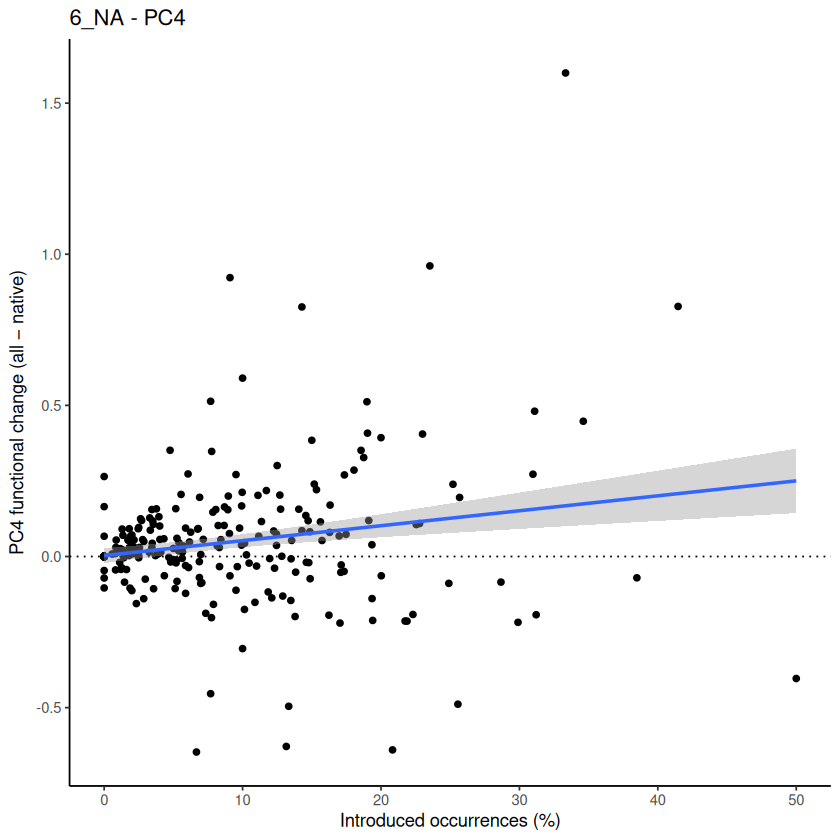

`geom_smooth()` using formula = 'y ~ x'


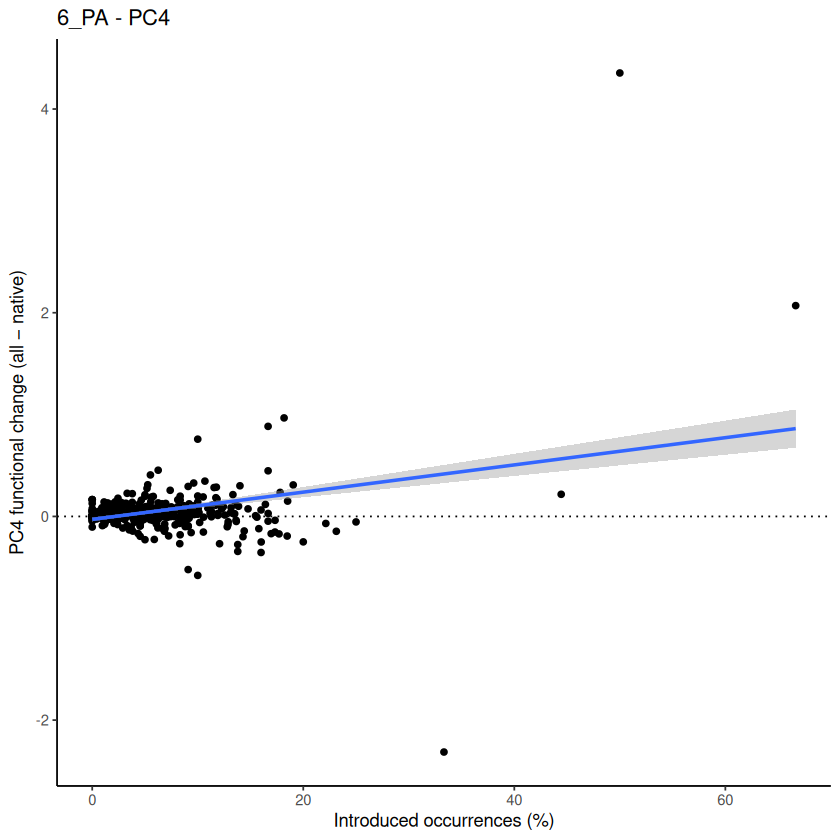

`geom_smooth()` using formula = 'y ~ x'


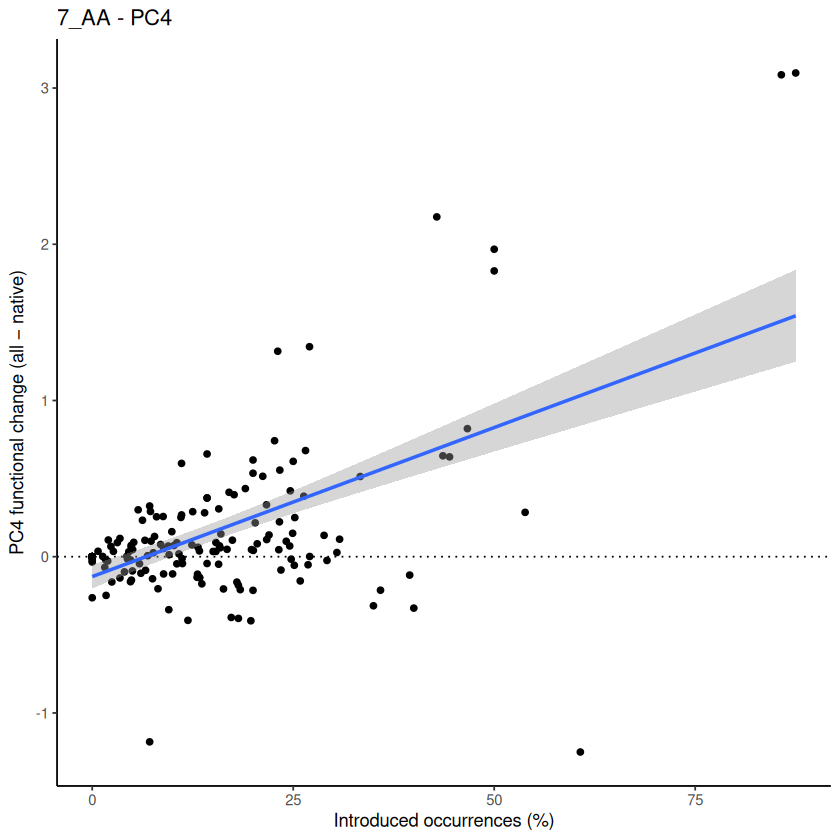

`geom_smooth()` using formula = 'y ~ x'


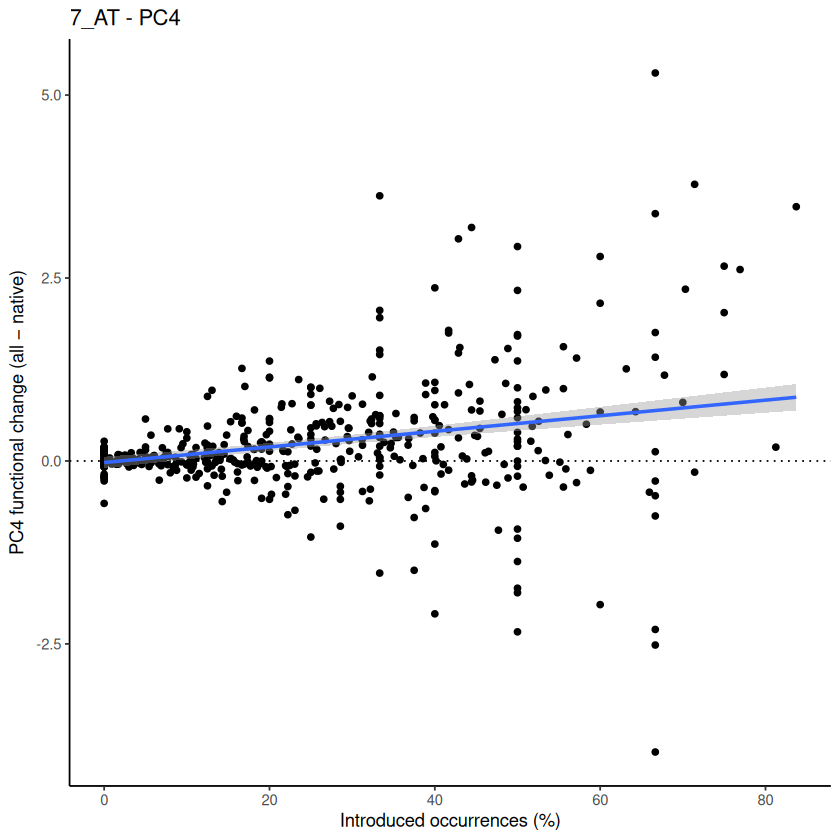

`geom_smooth()` using formula = 'y ~ x'


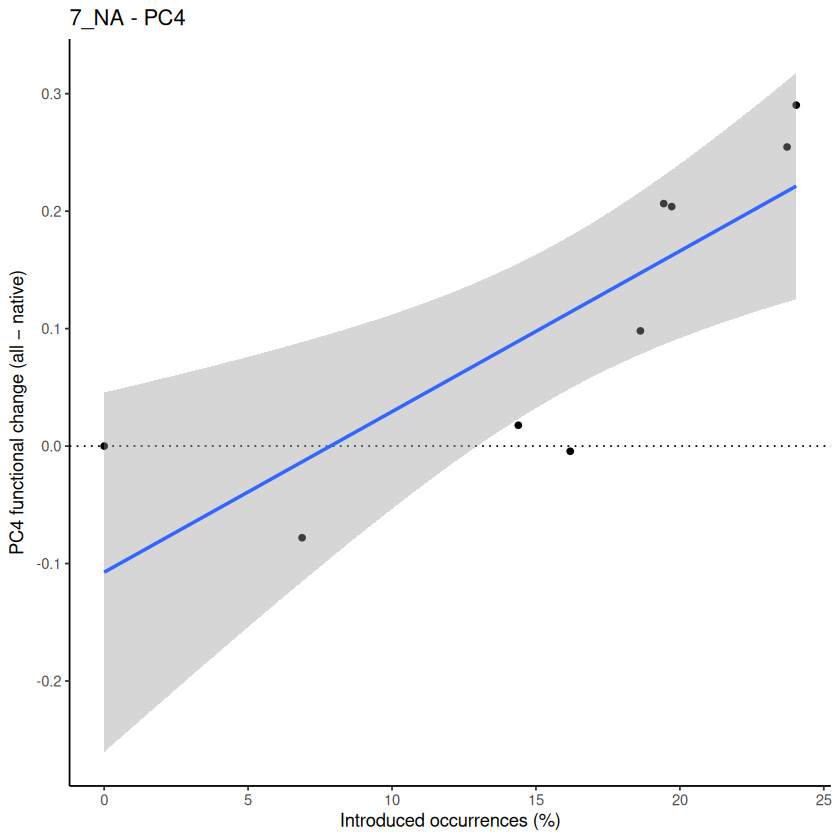

`geom_smooth()` using formula = 'y ~ x'


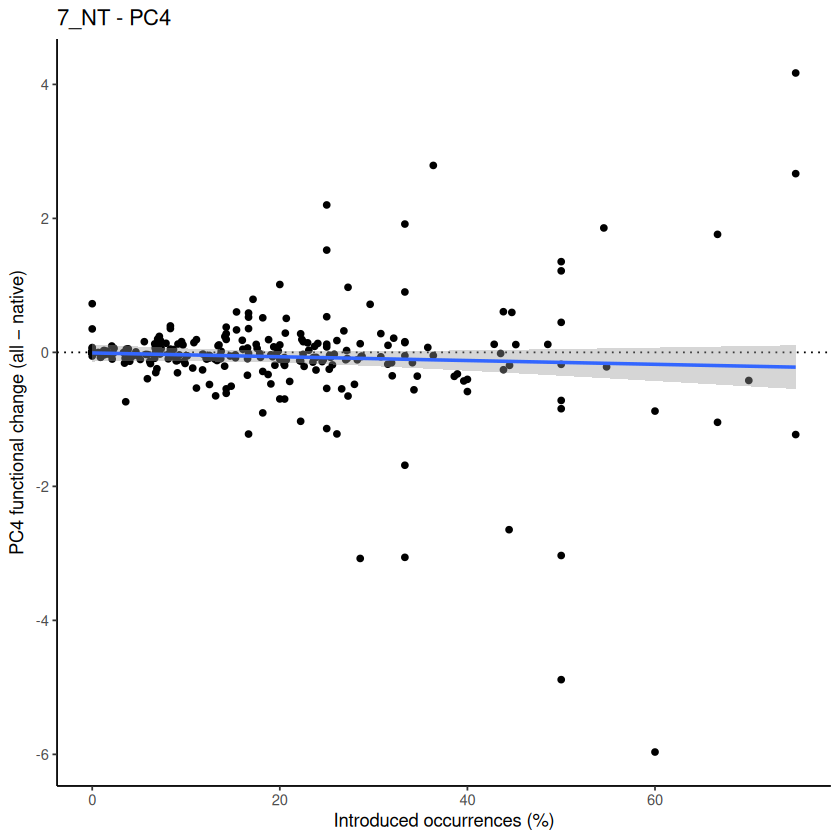

`geom_smooth()` using formula = 'y ~ x'


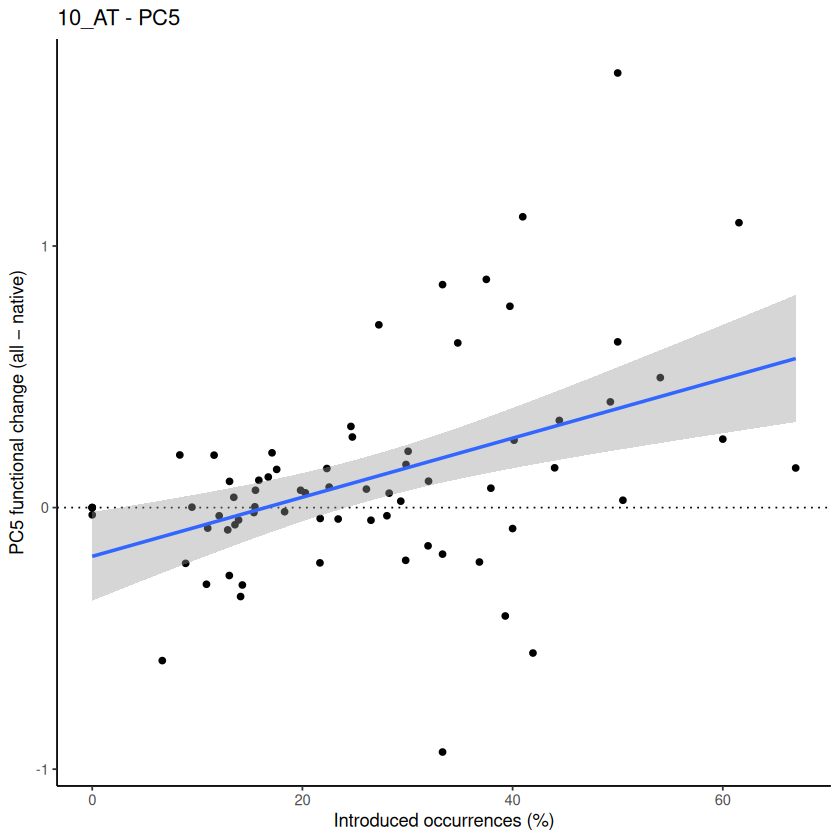

`geom_smooth()` using formula = 'y ~ x'


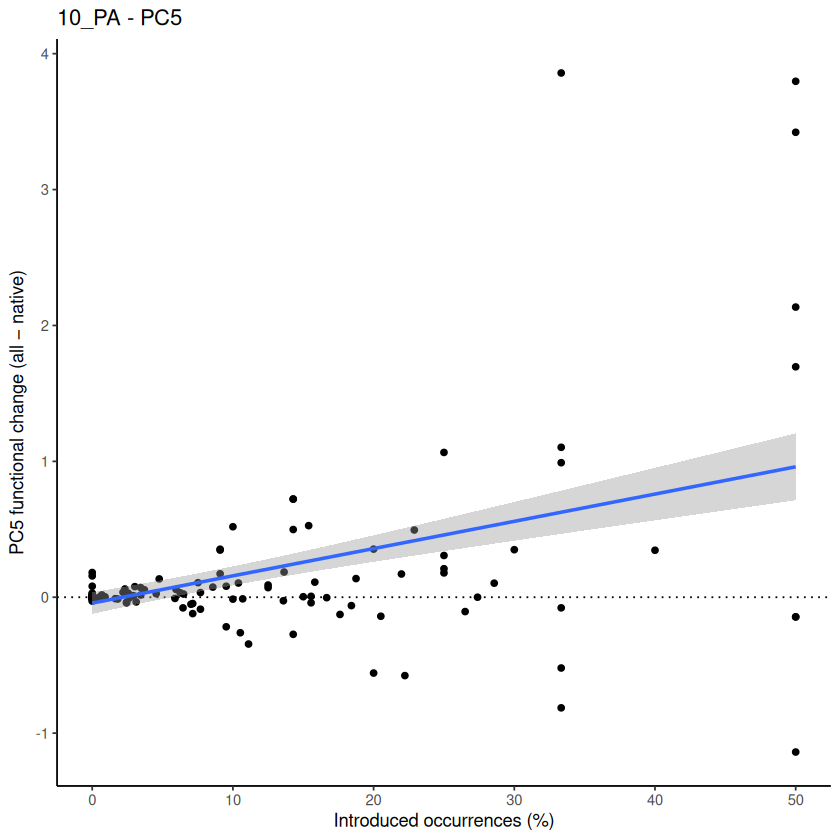

`geom_smooth()` using formula = 'y ~ x'


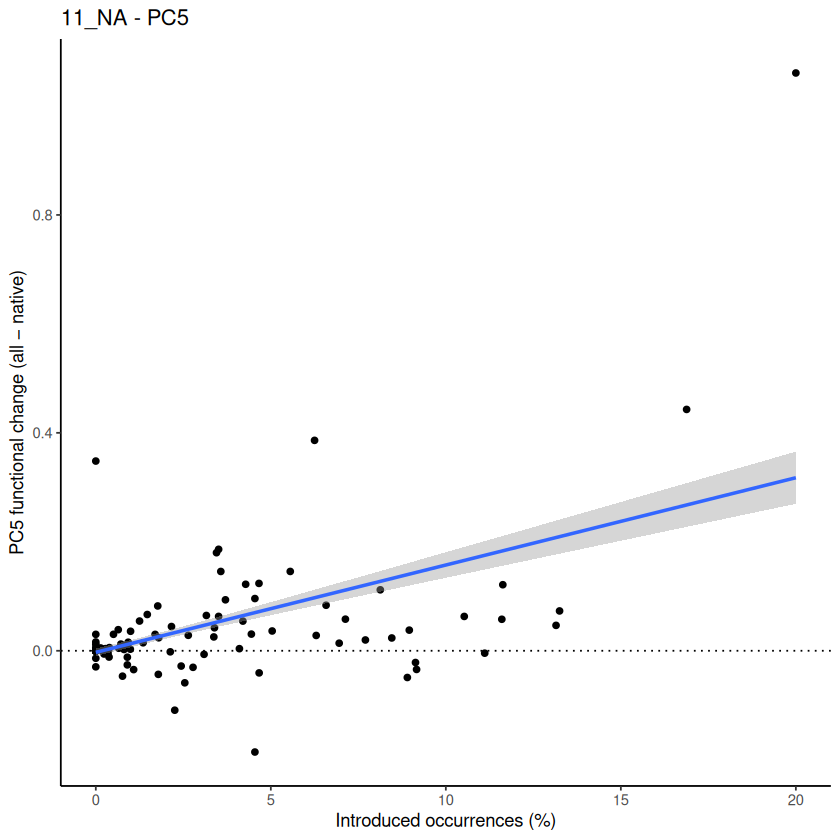

`geom_smooth()` using formula = 'y ~ x'


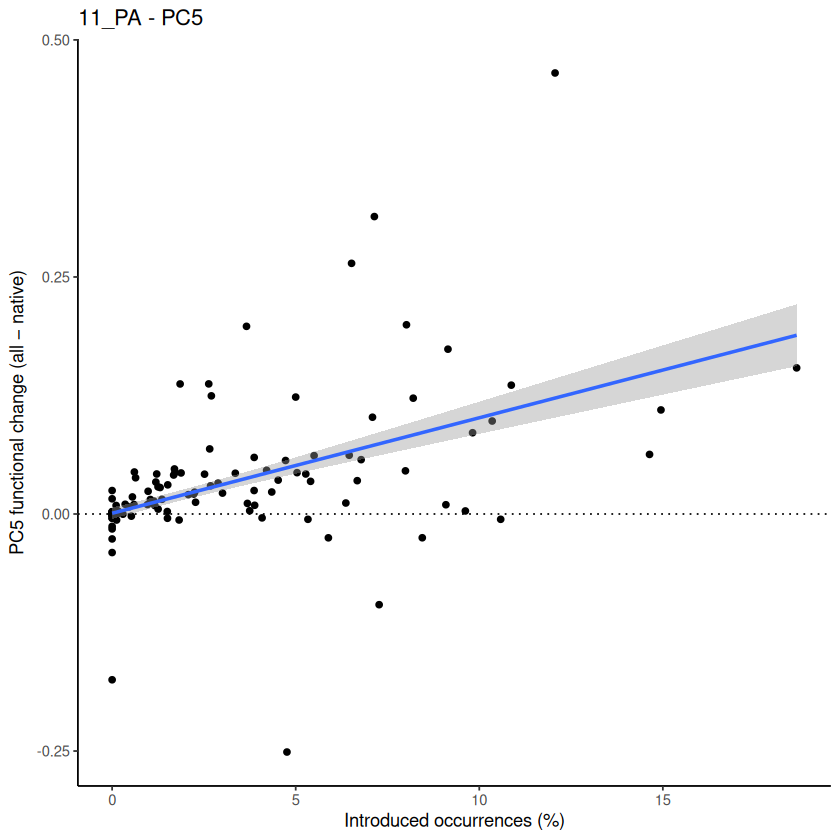

`geom_smooth()` using formula = 'y ~ x'


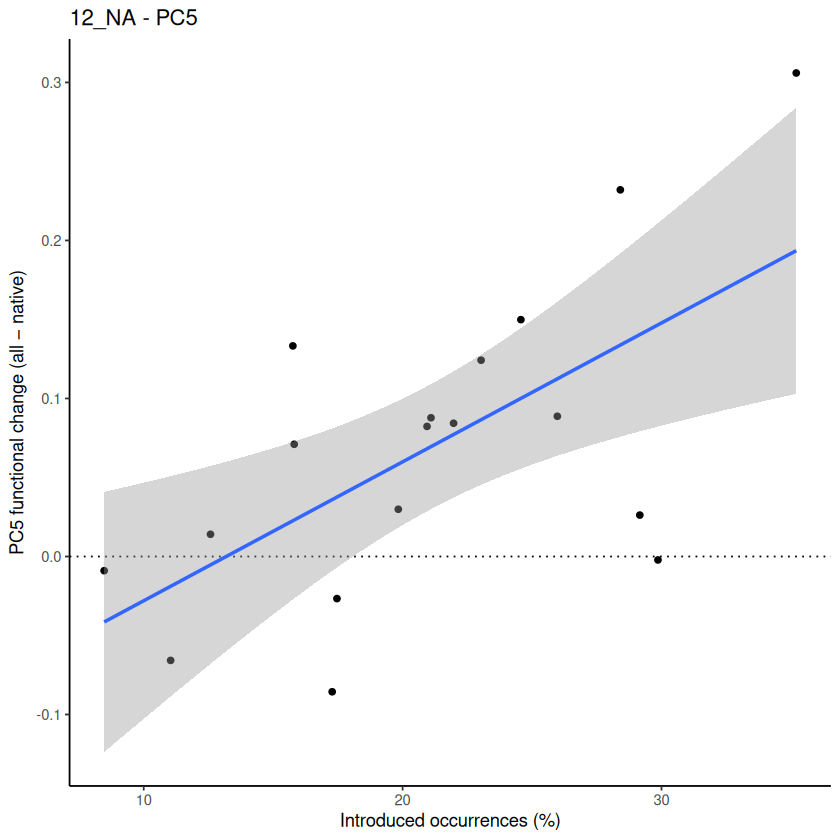

`geom_smooth()` using formula = 'y ~ x'


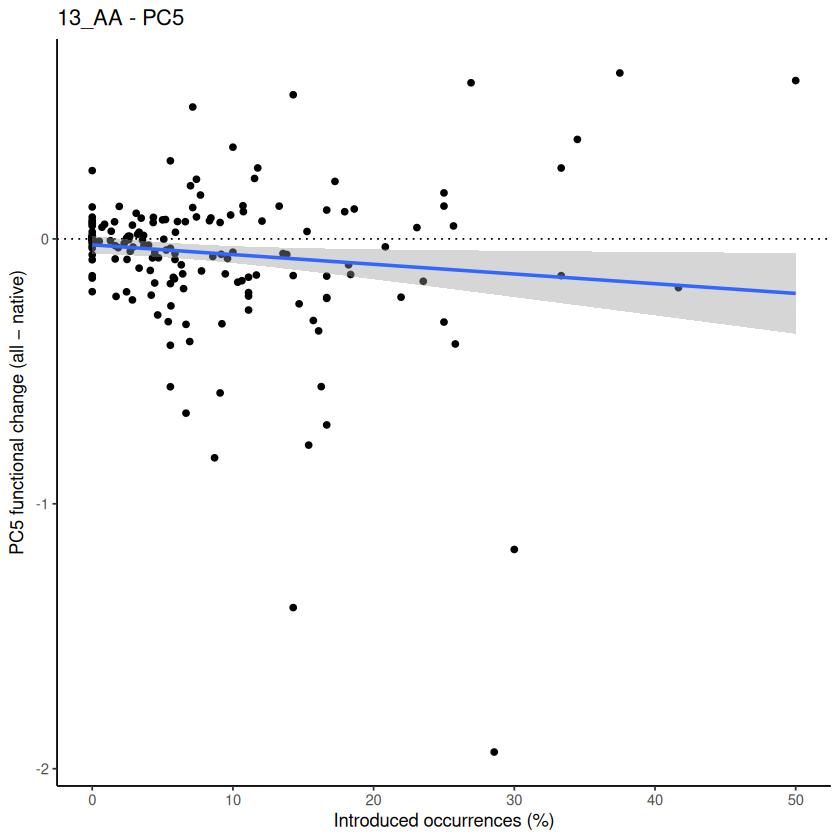

`geom_smooth()` using formula = 'y ~ x'


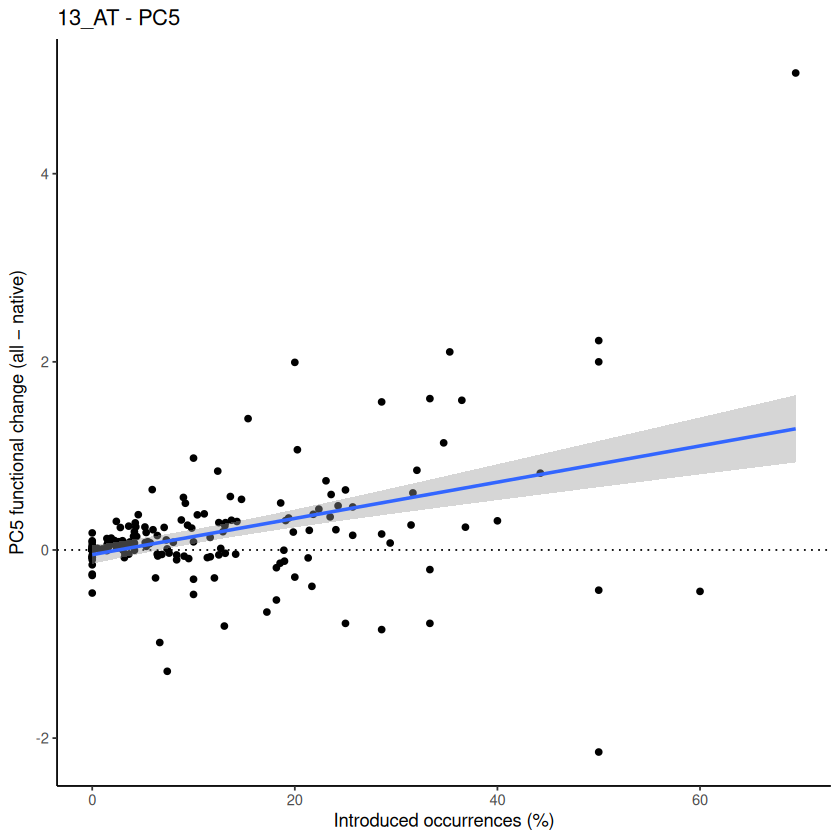

`geom_smooth()` using formula = 'y ~ x'


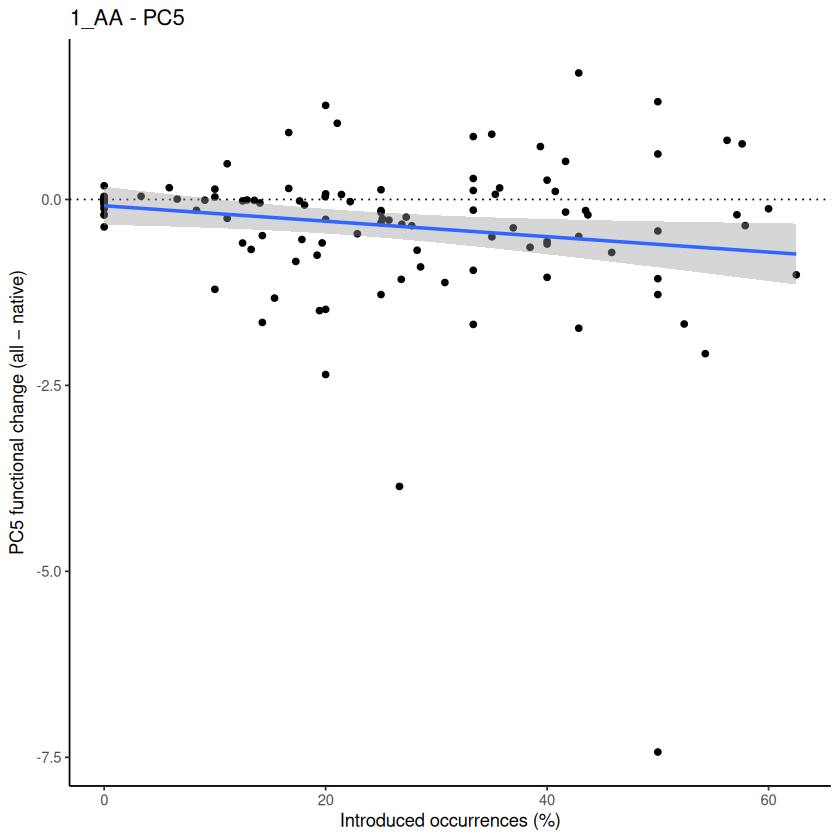

`geom_smooth()` using formula = 'y ~ x'


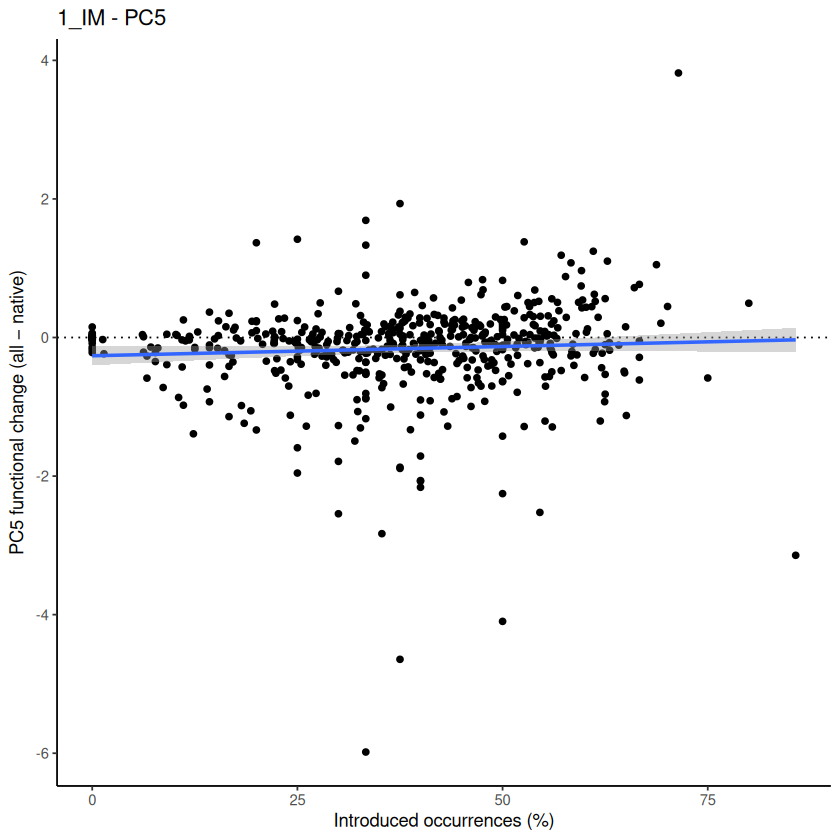

`geom_smooth()` using formula = 'y ~ x'


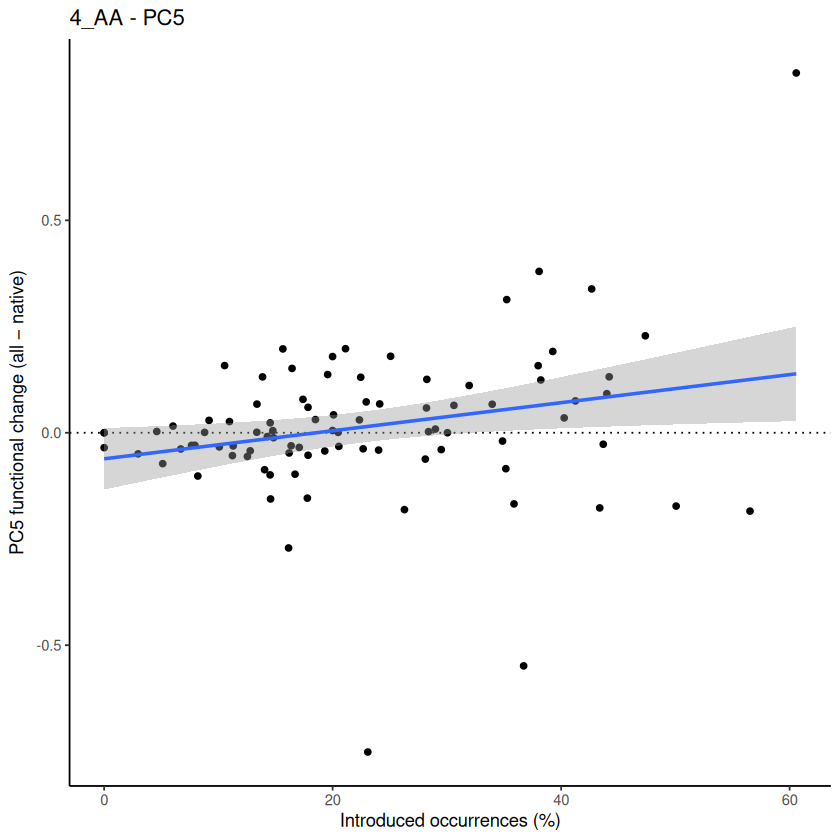

`geom_smooth()` using formula = 'y ~ x'


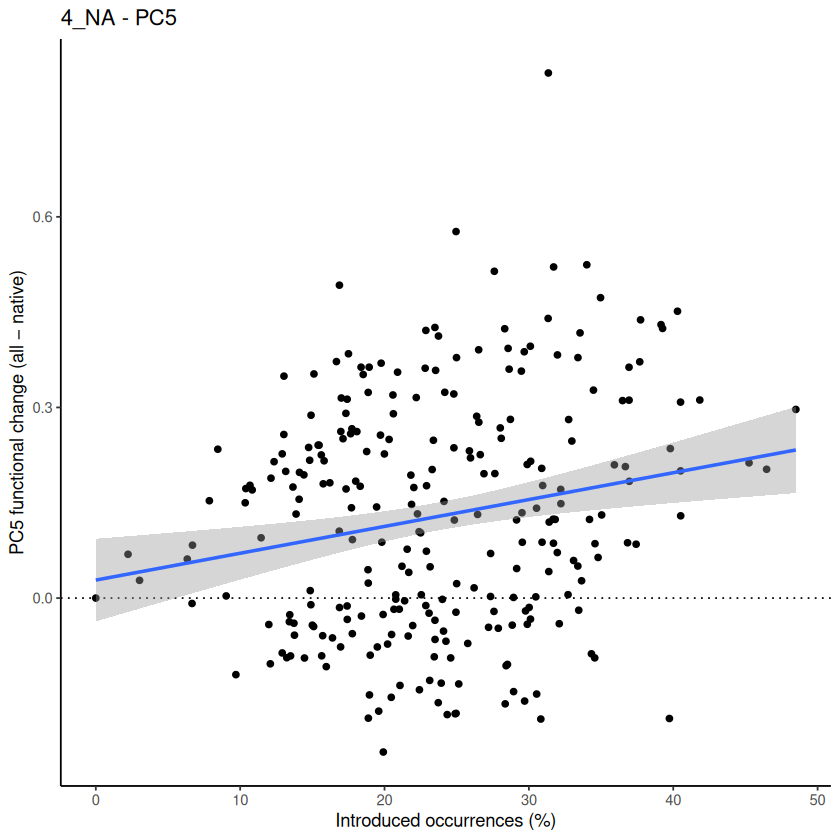

`geom_smooth()` using formula = 'y ~ x'


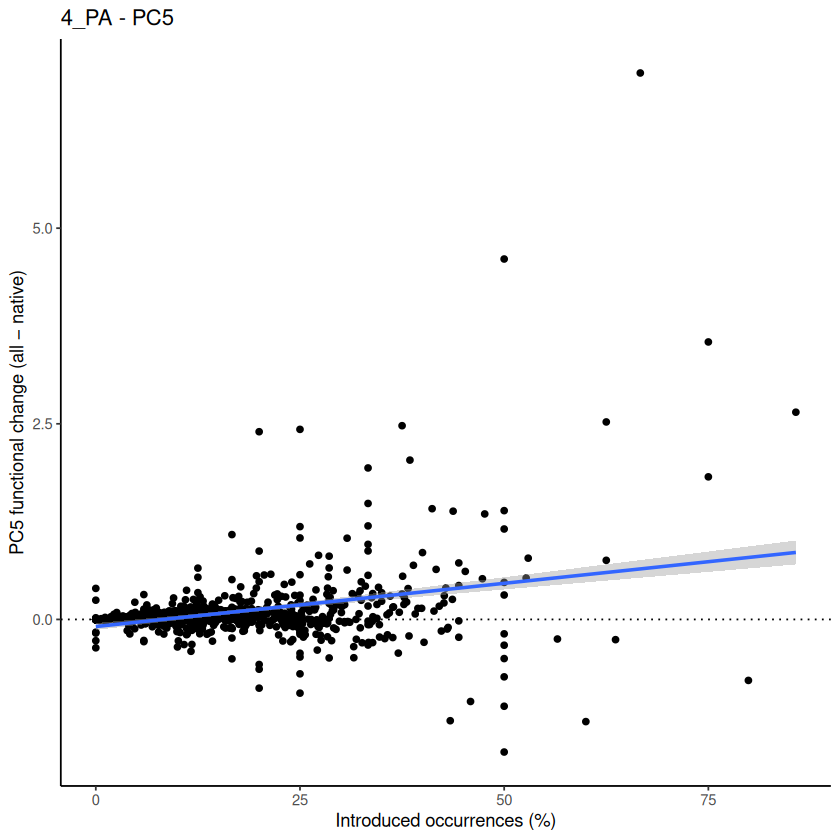

`geom_smooth()` using formula = 'y ~ x'


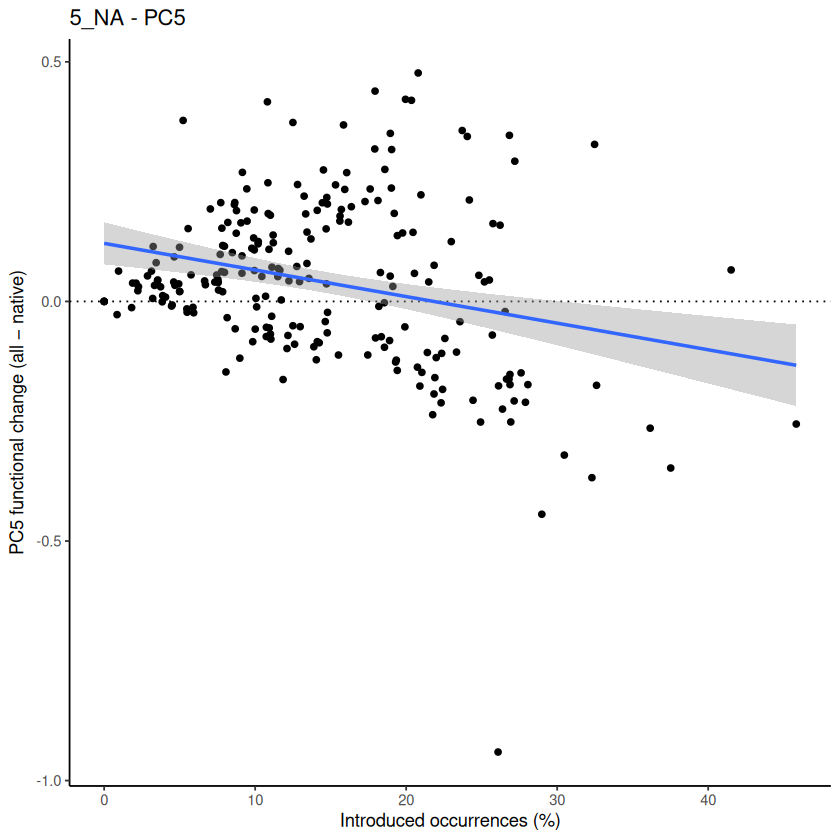

`geom_smooth()` using formula = 'y ~ x'


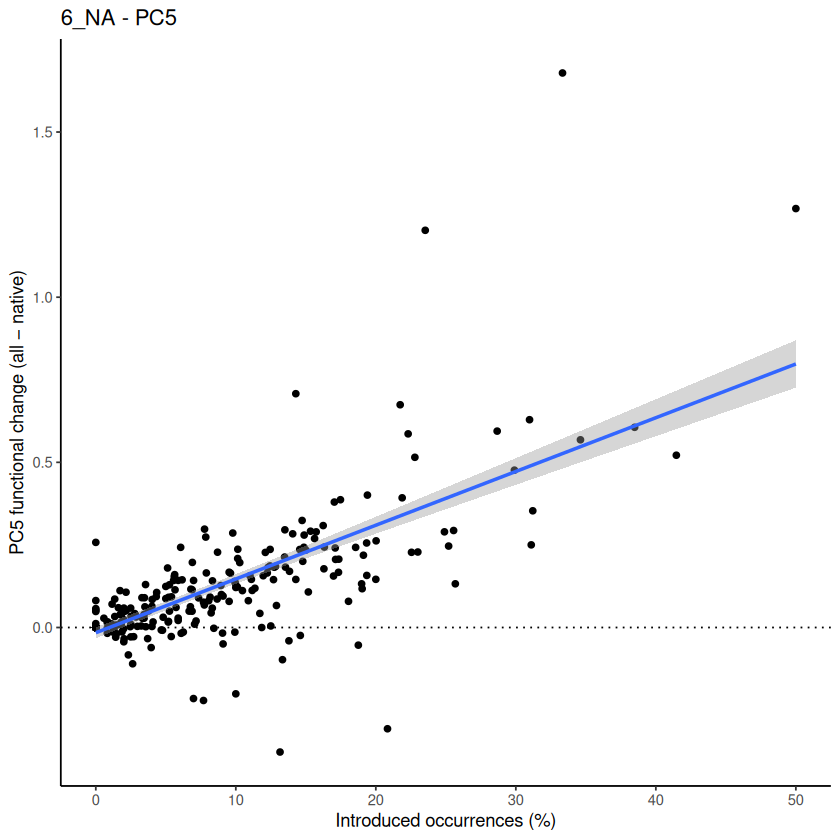

`geom_smooth()` using formula = 'y ~ x'


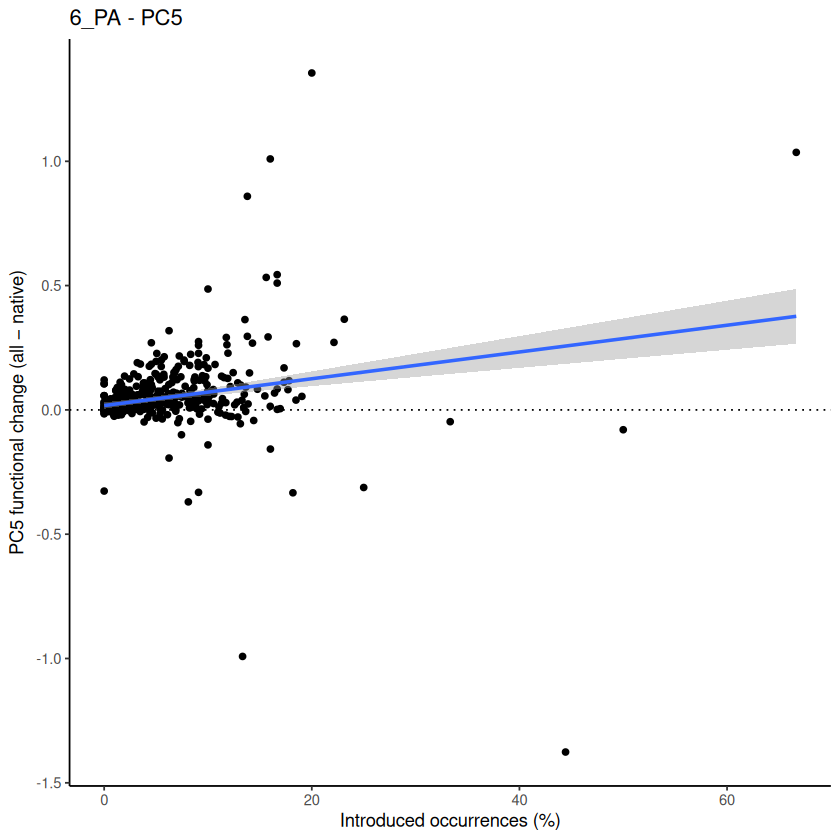

`geom_smooth()` using formula = 'y ~ x'


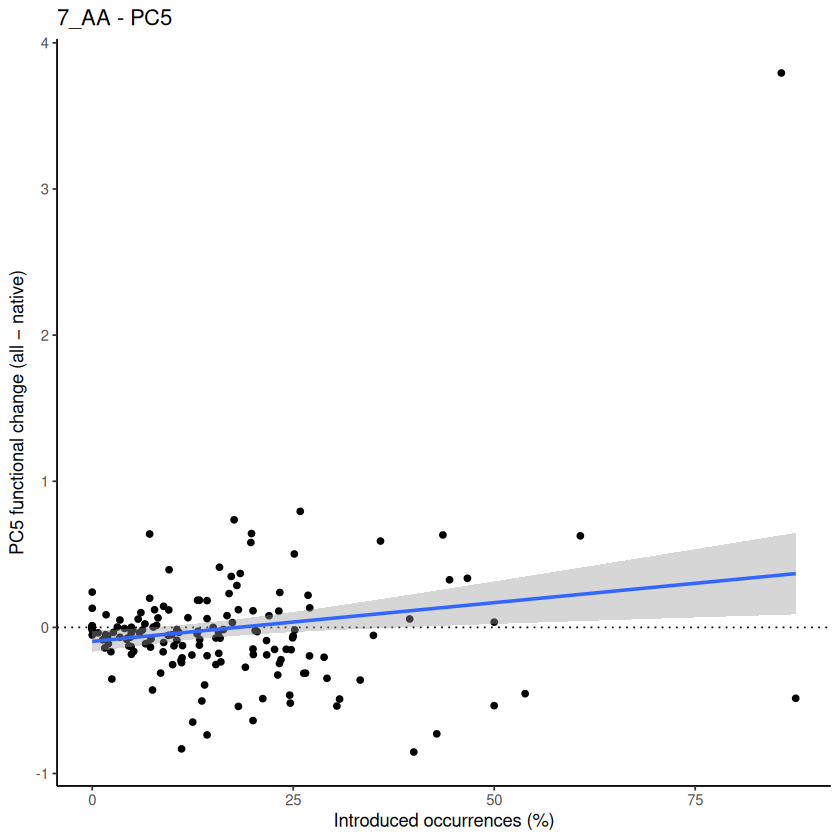

`geom_smooth()` using formula = 'y ~ x'


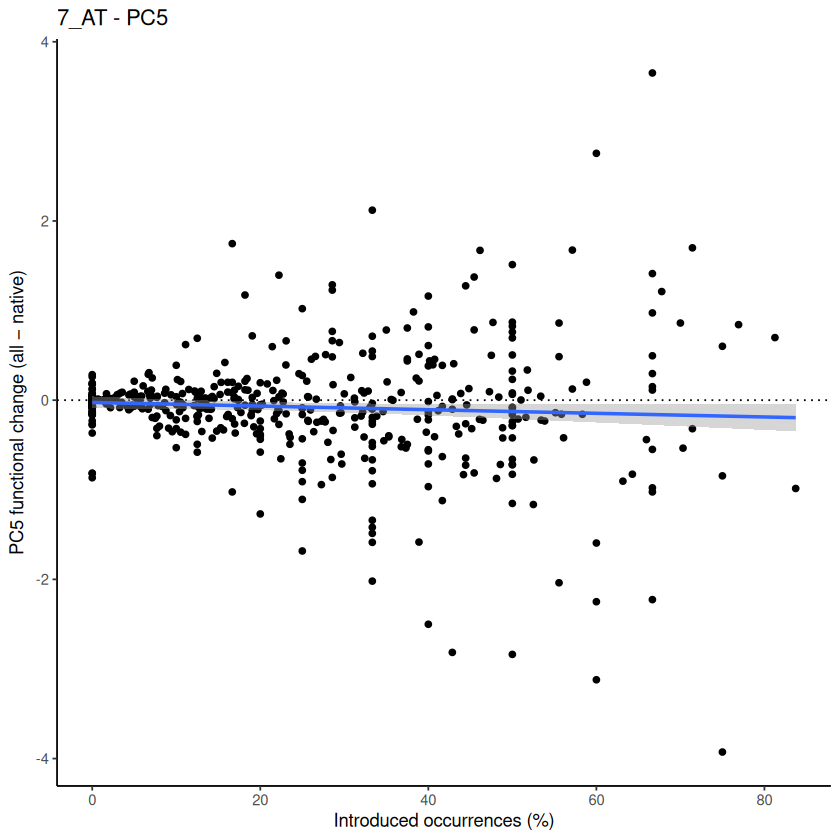

`geom_smooth()` using formula = 'y ~ x'


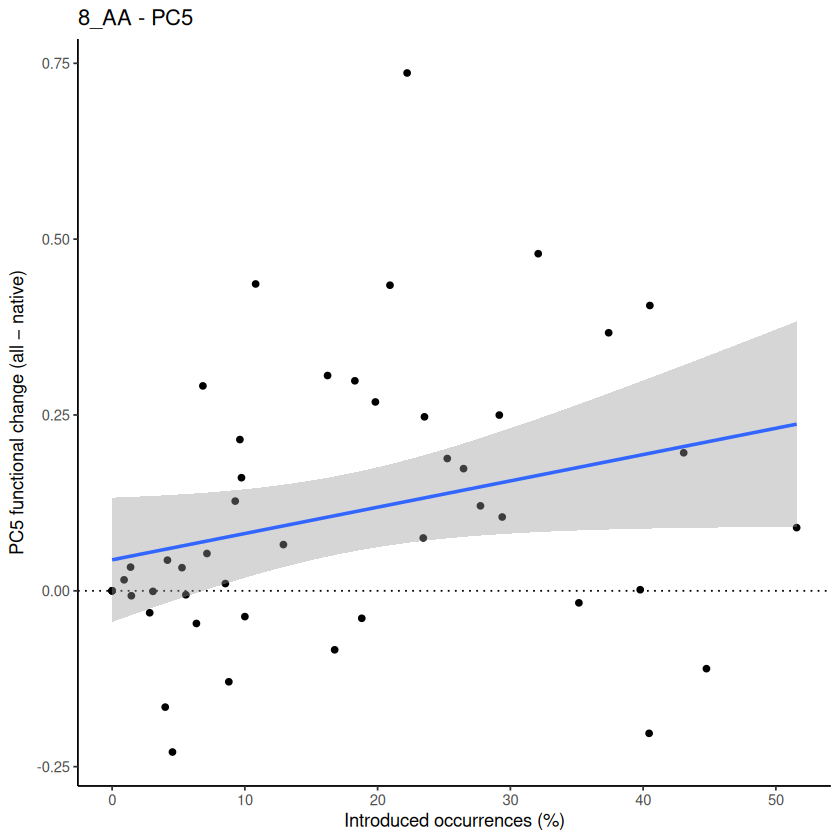

`geom_smooth()` using formula = 'y ~ x'


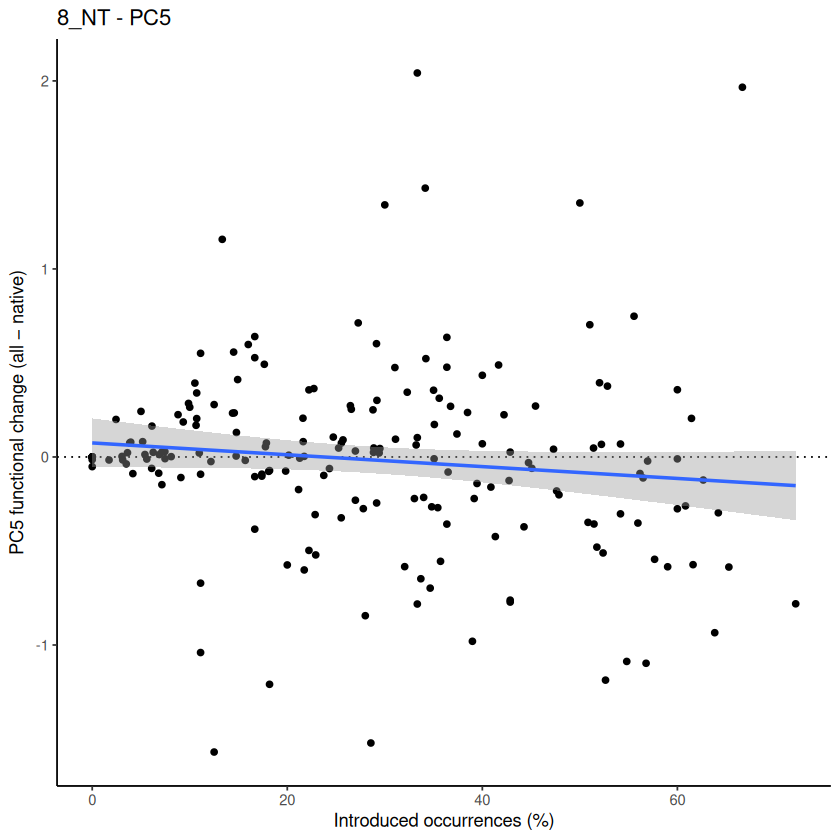

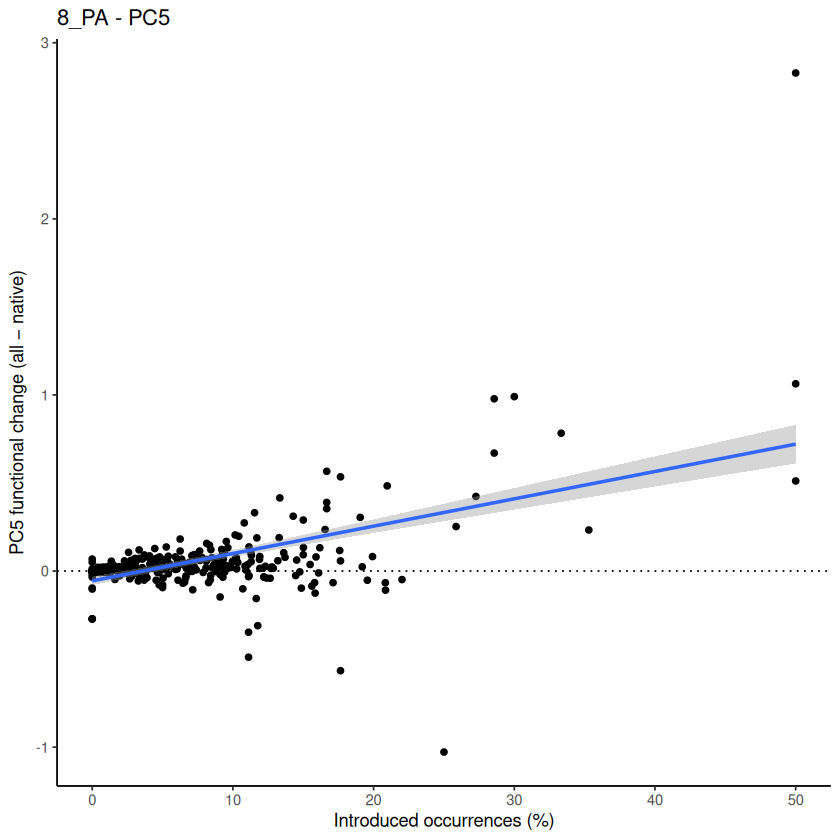

In [70]:
library(dplyr)
library(ggplot2)

# Significant biome × PC combinations
significant_combinations <- correlation_results %>%
  filter(
    predictor == "Introduced occurrences (%)",
    p_adjusted < 0.05
  ) %>%
  select(region, PC)

plot_data <- summary_stats %>%
  inner_join(
    significant_combinations,
    by = "region"
  ) %>%
  filter(
    paste0(PC, "_diff") %in% names(summary_stats)
  )

# Plot each significant biome × PC separately
for (i in seq_len(nrow(significant_combinations))) {

  region_i <- significant_combinations$region[i]
  PC_i <- significant_combinations$PC[i]
  diff_col <- paste0(PC_i, "_diff")

  p <- summary_stats %>%
    filter(region == region_i) %>%
    ggplot(
      aes(
        x = perc_introduced_occurrences,
        y = .data[[diff_col]]
      )
    ) +
    geom_hline(
      yintercept = 0,
      linetype = "dotted",
      color = "black"
    ) +
    geom_point() +
    geom_smooth(
      method = "lm",
      se = TRUE
    ) +
    labs(
      title = paste(region_i, "-", PC_i),
      x = "Introduced occurrences (%)",
      y = paste0(PC_i, " functional change (all − native)")
    ) +
    theme_classic()

  print(p)
}

`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


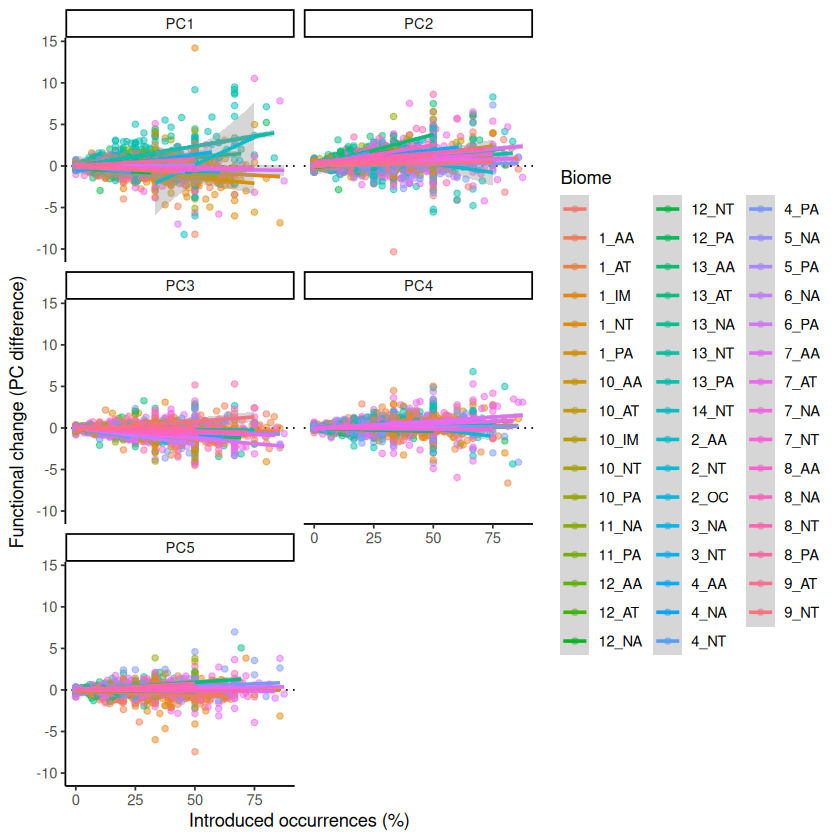

In [71]:
library(dplyr)
library(tidyr)
library(ggplot2)

# Biome × PC combinations significant for introduced occurrences
significant_combinations <- correlation_results %>%
  filter(
    predictor == "Introduced occurrences (%)",
    p_adjusted < 0.05
  ) %>%
  select(region, PC)

# Long-format data
plot_data <- summary_stats %>%
  select(
    region,
    perc_introduced_occurrences,
    PC1_diff:PC5_diff
  ) %>%
  pivot_longer(
    cols = PC1_diff:PC5_diff,
    names_to = "PC",
    values_to = "PC_diff"
  ) %>%
  mutate(
    PC = sub("_diff", "", PC)
  ) %>%
  inner_join(
    significant_combinations,
    by = c("region", "PC")
  )

ggplot(
  plot_data,
  aes(
    x = perc_introduced_occurrences,
    y = PC_diff,
    color = region
  )
) +
  geom_hline(
    yintercept = 0,
    linetype = "dotted",
    color = "black"
  ) +
  geom_point(alpha = 0.5) +
  geom_smooth(
    aes(group = region),
    method = "lm",
    se = TRUE
  ) +
  facet_wrap(~ PC, ncol = 2) +
  labs(
    x = "Introduced occurrences (%)",
    y = "Functional change (PC difference)",
    color = "Biome"
  ) +
  theme_classic()

ggsave(
  "~/Func_Neo_Phytes/Results/Figures/PC_diff_introduced_occurrences_significant_biomes.pdf",
  width = 11,
  height = 9
)